# Анализ метрик и юнит-экономики маркетплейса

В рамках проекта проанализируем данные маркетплейса, чтобы оценить текущее состояние продукта, его монетизацию и юнит-экономику, а также найти инсайты и точки роста и сформулировать гипотезы для A/B-тестирования.

Данные для анализа:

https://code.s3.yandex.net/datasets/pa_marketplace_orders.csv
https://code.s3.yandex.net/datasets/pa_marketplace_campaign_costs.csv
https://code.s3.yandex.net/datasets/pa_marketplace_users.csv
https://code.s3.yandex.net/datasets/pa_marketplace_events.csv

**Обзор ключевых метрик** <br>
Выполним верхнеуровневую оценку состояния продукта без глубокой сегментации. Рассмотрим динамику основных метрик (например, Revenue, ARPU, ARPPU, MAU, WAU, DAU, AOV, Retention, CTR, CR в заказ) и сформируем общее представление о развитии продукта, наличии роста и возможных проблемах.

**Оценка монетизации и юнит-экономики**<br>
Проанализируем, сколько зарабатывает продукт (выручка — 5% от стоимости заказа) и сколько тратит на привлечение пользователей. Рассчитаем ключевые метрики (ARPU, AOV, CAC, ROI, Payback Period) и сформулируем краткие выводы в формате аналитической записки.

**Поиск инсайтов и точек роста** <br>
Проведём более детальный анализ данных по сегментам (каналы, пользователи, категории товаров, регионы, устройства). Найдём закономерности, различия и аномалии, определим сильные и слабые сегменты, а также узкие места в воронке.

Сформулируем:
- выводы по результатам анализа,
- гипотезы для развития продукта с обоснованием (на основе динамики и взаимосвязи метрик).

В каждом блоке зафиксируем краткие выводы, чтобы можно было быстро ознакомиться с основными результатами анализа.

# Описание данных

## Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

## Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

## Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


## Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



## Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


## Выручка маркетплейса = 5% от total_price

### 1. Загрузка данных и предобработка

Загружаем данные из датасетов и получаем основную информацию о них. Проведим предобработку. Зафиксируем основную информацию о данных и предобработке в кратком промежуточном выводе.

In [ ]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# Импортируем библиотеку matplotlib_venn
!pip install matplotlib-venn
from matplotlib_venn import venn2
from matplotlib_venn import venn3

# Загружаем библиотеки для работы с массивами и математическими операциями
import numpy as np

# Импортируем Z-тест для проверки равенства долей (конверсий) в группах
from statsmodels.stats.proportion import proportions_ztest

# Импортируем T-тест Стьюдента
from scipy.stats import ttest_ind

# Отключаем предупреждения
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Выгружаем данные в датафреймы

path = 'https://code.s3.yandex.net/'
pa_marketplace_orders = pd.read_csv(path + '/datasets/pa_marketplace_orders.csv', parse_dates=['order_date', 'order_week', 'order_month'])
pa_marketplace_campaign_costs = pd.read_csv(path + '/datasets/pa_marketplace_campaign_costs.csv', parse_dates=['spend_month'])
pa_marketplace_users = pd.read_csv(path + '/datasets/pa_marketplace_users.csv', parse_dates=['registration_date', 'cohort_week', 'cohort_month'])
pa_marketplace_events = pd.read_csv(path + '/datasets/pa_marketplace_events.csv', parse_dates=['event_date', 'event_week', 'event_month'])

Чтобы познакомиться с данными датасетов создадим набор функций.

In [ ]:
# Функция, которая будет показывать первые строки и информацию о датафрейме
def show_df(df):
    """Функция показывает первые строки датафрейма и информацию о нём.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    """
    display(df.head())
    df.info()
    print()


In [ ]:
# Функция для отображения уникальных значений в столбцах датафрейма
def print_count_uniq_values (dataframe, columns):
    """
    Функция для вывода на экран количество уникальные значения в указанных столбцах датафрейма.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список столбцов, для которых нужно подсчитать количество уникальных значений
    """
    print('Количество уникальных значений в столбцах датафрейма')
    print('Размер датафрейма:', dataframe.shape[0])
    print()
    for column in columns:
        print(f'Количество уникальных значений в {column}:', dataframe[column].value_counts().count())
    print()


In [ ]:
def print_unique_categorical_values(dataframe, columns, limit=20):
    """
    Функция выводит уникальные значения в указанных столбцах.
    Если значений больше лимита, выводит только первые n элементов.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список столбцов
    limit (int): порог количества отображаемых значений
    """
    for column in columns:
        unique_vals = dataframe[column].unique()

        if len(unique_vals) > limit:
            print(f'{column}: {unique_vals[:limit]}')
        else:
            print(f'{column}: {unique_vals}')
    print()

In [ ]:
# Функция для отобразажения количества явных дубликатов
def show_duplicates(dataframe):
    """
    Функция показывает дублирующиеся строки, если они есть.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа

    Возвращает:
    pd.DataFrame или None: DataFrame с дубликатами или None, если дубликатов нет
    """
    duplicates = dataframe[dataframe.duplicated(keep=False)]

    if duplicates.empty:
        print('Дубликатов нет\n')
        return None  # Возвращаем None вместо пустого DataFrame
    else:
        print(f'Найдено дубликатов: {len(duplicates)} строк\n')
        return duplicates

In [ ]:
# Функция для отображения статистики по количеству и доле пропусков в датафрейме
def show_missing_stats(dataframe):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    Параметры:   dataframe (pd.DataFrame): Исходный DataFrame для анализа
    Возвращает:  Styler или строку: Объект Styler с подсветкой или сообщение об отсутствии пропусков
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': dataframe.isnull().sum(),
        'Доля пропусков': dataframe.isnull().mean().round(4)
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    return missing_stats.style.background_gradient(cmap='coolwarm') if not missing_stats.empty else 'Пропусков в данных нет'

In [ ]:
# Функция для отображения информации по количеству строк с неявными дубликатами по нескольким столбцам
def show_subset_duplicates(dataframe, columns):
    """
    Функция ищет дубликаты по заданному набору колонок (subset).

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список названий колонок для проверки на пересечение
    """
    # Находим все строки, которые имеют дубликаты по указанным колонкам
    duplicates = dataframe[dataframe.duplicated(subset=columns, keep=False)]

    print(f"Анализ дубликатов по столбцам: {', '.join(columns)}")

    if duplicates.empty:
        print("Дубликатов по выбранным полям не обнаружено.\n")
    else:
        print(f"Найдено строк с дубликатами: {len(duplicates)}")
        print(f"Количество уникальных пар/групп дубликатов: {len(dataframe[dataframe.duplicated(subset=columns)])}\n")

        # Выведем первые несколько строк для примера
        print("Примеры дублирующихся записей:")
        display(duplicates.sort_values(by=columns).head(8))


In [ ]:
# Функция, которая отображает временной период для полей с датой
def check_time_ranges(dataframe, date_columns):
    """
    Функция выводит временные границы для списка колонок.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    date_columns (list): список названий колонок с датами
    """
    for column in date_columns:
        min_date = dataframe[column].min()
        max_date = dataframe[column].max()
        delta = max_date - min_date

        # Если время везде нулевое, выводим только дату, иначе — с часами
        fmt = '%Y-%m-%d' if (dataframe[column].dt.hour == 0).all() else '%Y-%m-%d %H:%M:%S'

        print(f"Анализ колонки: '{column}'")
        print(f"Начало периода: {min_date.strftime(fmt)}")
        print(f"Конец периода:  {max_date.strftime(fmt)}")
        print(f"Временной диапазон: {delta.days} дней\n")



In [ ]:
# Функция для понижени разрядности столбцом с числовыми значениями (int и float)
def downcast_numeric(dataframe):
    """
    Функция понижает разрядность числовых полей (int и float).

    Параметры:
    dataframe (pd.DataFrame): датафрейм для оптимизации
    """
    # Выбираем только числовые колонки
    cols = dataframe.select_dtypes(include=['number']).columns

    for col in cols:
        # Пытаемся понизить до целого, если нет - до дробного
        if 'int' in str(dataframe[col].dtype):
            dataframe[col] = pd.to_numeric(dataframe[col], downcast='integer')
        else:
            dataframe[col] = pd.to_numeric(dataframe[col], downcast='float')



Познакомимся с датасетом `pa_marketplace_users`.

In [ ]:
# Выводим первые 5 строк и информацию
show_df(pa_marketplace_users)

,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB



In [ ]:
# Выводим уникальные значения полей gender, region, acq_channel, buyer_segment
print_unique_categorical_values(pa_marketplace_users, ['gender', 'region', 'acq_channel', 'buyer_segment'])

# Выведем количество уникальных значений полей  user_id и age
print_count_uniq_values(pa_marketplace_users, ['user_id', 'age', 'region', 'acq_channel', 'buyer_segment'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(pa_marketplace_users)



gender: ['M' 'F']
region: ['Москва' 'Санкт-Петербург' 'Краснодар' 'Другие регионы' 'Нижний Новгород'
 'Екатеринбург' 'Московская область' 'Новосибирск' 'Ростов-на-Дону']
acq_channel: ['Google Ads' 'Email Marketing' 'Affiliate' 'SEO' 'Social Media' 'TikTok']
buyer_segment: ['regular' 'rare' 'one_time' 'medium']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 44151

Количество уникальных значений в user_id: 44151
Количество уникальных значений в age: 53
Количество уникальных значений в region: 9
Количество уникальных значений в acq_channel: 6
Количество уникальных значений в buyer_segment: 4

Дубликатов нет



In [ ]:
# Проверим датафрейм на наличие неявных дубликатов одновременно по полям: registration_date, age, gender, region
show_subset_duplicates(pa_marketplace_users, ['registration_date', 'age', 'gender', 'region'])

Анализ дубликатов по столбцам: registration_date, age, gender, region
Найдено строк с дубликатами: 10
Количество уникальных пар/групп дубликатов: 5

Примеры дублирующихся записей:


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
13977,14348,2024-05-24 16:04:00,45,M,Санкт-Петербург,Social Media,medium,2024-05-20,2024-05-01
13985,14356,2024-05-24 16:04:00,45,M,Санкт-Петербург,Google Ads,one_time,2024-05-20,2024-05-01
17935,18386,2024-07-04 03:30:00,25,M,Другие регионы,Social Media,medium,2024-07-01,2024-07-01
18022,18474,2024-07-04 03:30:00,25,M,Другие регионы,Google Ads,rare,2024-07-01,2024-07-01
33150,33836,2024-10-18 11:00:00,34,M,Москва,Social Media,medium,2024-10-14,2024-10-01
33158,33844,2024-10-18 11:00:00,34,M,Москва,TikTok,rare,2024-10-14,2024-10-01
35776,36486,2024-11-05 21:37:00,63,M,Екатеринбург,TikTok,medium,2024-11-04,2024-11-01
35958,36672,2024-11-05 21:37:00,63,M,Екатеринбург,Affiliate,medium,2024-11-04,2024-11-01


In [ ]:
# Смотрим времеменной диапозон по полю registration_date
check_time_ranges(pa_marketplace_users, ['registration_date'])

Анализ колонки: 'registration_date'
Начало периода: 2024-01-01 00:07:00
Конец периода:  2024-12-31 23:44:00
Временной диапазон: 365 дней



**Описание данных после предварительного знакомства с датасетом `pa_marketplace_users`** <br>
Датасет `pa_marketplace_users` состоит из **9 полей и 44151 записи** о пользователях, зарегистрированных в течение 2024 года.

**Пользовательская база**
- 44151 уникальный пользователь (соответствует количеству записей)
- 53 уникальных значений по возрасту возраста (широкий диапозон по возрасту)

**География и каналы привлечения**
- Пользователи распределены по 9 регионам: Москва, Санкт-Петербург, Краснодар, Нижний Новгород, Екатеринбург, Новосибирск, Ростов-на-Дону, Московская область и Другие регионы
- Привлечение осуществлялось через 6 каналов: Google Ads, Email Marketing, Affiliate, SEO, Social Media и TikTok

**Сегментация пользователей**
- Пользователи разделены на 4 сегмента покупательской активности: regular, rare, one_time и medium
- Данные распределены по недельным и месячным когортам на основе даты регистрации

**Качество данных**
- Явные дубликаты отсутствуют, пропусков в данных нет
- Обнаружены неявные дубликаты - 10 строк (5 пар), где полностью совпадают время регистрации, возраст, пол и регион. Различаются ID пользователя, а также канал привлечения. Поскольку данные регистрации округлины до минут, нельзя с уверенностью сказать, что датасет содержит сведения о повторных регистрациях одних и тех же пользователей через разные источники. Поскольку неявных дубликатов всего 10, пока не будем удалять их из датасета.

**Временной диапозон**
- Датасет содержит сведения о действиях пользователей, зарегистрировавшихся с 1 января по 31 декабря 2024 (включительно)

**Тип данных**
- Типы данных соответствуют содержимому
- Для полей `user_id`, `age` можно понизить разрядность

Предобработка данных <br>
Понизим разрядность полей `user_id`, `age`.


In [ ]:
# Понизим разрядность полей с типом данных int64
downcast_numeric(pa_marketplace_users)

# Проверям результат
pa_marketplace_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int32         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int8          
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int32(1), int8(1), object(4)
memory usage: 2.6+ MB


Познакомимся с датасетом `pa_marketplace_events`.

In [ ]:
# Выводим первые 5 строк и информацию
show_df(pa_marketplace_events)

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int64         
 1   user_id       785859 non-null  int64         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  datetime64[ns]
 8   event_month   785859 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 54.0+ MB



In [ ]:
# Выводим информацию о пропусках
show_missing_stats(pa_marketplace_events)

,Кол-во пропусков,Доля пропусков
product_name,400119,0.509100


In [ ]:
# Выводим уникальные значения  полей event_type, os, device, product_name
print_unique_categorical_values(pa_marketplace_events, ['event_type', 'os', 'device', 'product_name'])

# Выведем количество уникальных пользователей и событий
print_count_uniq_values(pa_marketplace_events, ['event_id', 'user_id', 'product_name', 'event_type'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(pa_marketplace_events)

event_type: ['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'user_logout' 'search' 'category_view' 'filter_apply'
 'promo_view' 'wishlist_add' 'user_login' 'banner_click'
 'remove_from_cart']
os: ['iOS' 'Windows' 'macOS' 'Android']
device: ['mobile' 'desktop' 'tablet']
product_name: [nan 'Шорты для тренировок' 'Куртка детская' 'Балетки классические'
 'Маска для лица' 'Одеяло детское' 'Поло Ralph Lauren' 'Брюки палаццо'
 'Зубная паста' 'Коврик для йоги' 'Фен для волос' 'Гречка ядрица'
 'Пальто зимнее' 'Тушь для ресниц' 'Горелка газовая' 'Сумка кожаная'
 'Доска разделочная' 'Свитер с капюшоном' 'Шуруповерт' 'Часы Casio']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 785859

Количество уникальных значений в event_id: 785859
Количество уникальных значений в user_id: 22138
Количество уникальных значений в product_name: 200
Количество уникальных значений в event_type: 15

Дубликатов нет



In [ ]:
# Проверим датафрейм на наличие неявных дубликатов одновременно по id события и пользователя
show_subset_duplicates(pa_marketplace_events, ['event_id', 'user_id'])

Анализ дубликатов по столбцам: event_id, user_id
Дубликатов по выбранным полям не обнаружено.



In [ ]:
# Смотрим времеменной диапозон по полю registration_date
check_time_ranges(pa_marketplace_events, ['event_date'])

Анализ колонки: 'event_date'
Начало периода: 2024-01-01
Конец периода:  2024-12-31
Временной диапазон: 365 дней



**Описание данных после предварительного знакомства с датасетом `pa_marketplace_events`**

Датасет `pa_marketplace_events` состоит из **9 полей** и **785859 записей** о действиях пользователей маркетплейса в течение 2024 года.

**Пользовательская база и активность**
* 22138 уникальных пользователей, которые совершили действия в приложении
* 785859 событий (соответствует количеству уникальных `event_id`)

**Технические характеристики**
* Используются 3 типа устройств: `mobile`, `desktop` и `tablet`
* События распределены по 4 операционным системам: `iOS`, `Windows`, `macOS` и `Android`

**Сведения о товарах**
* В данных представлено 200 товаров (`product_name`)

**Событийная часть**
* Зафиксировано 15 типов событий (`event_type`): от входа и поиска до завершения оформления заказа (`checkout_complete`)
* Поле `product_name` содержит широкий перечень товаров (одежда, электроника, косметика и другие)

**Временной диапазон**
* Датасет содержит сведения о действиях пользователей за полный календарный год: с 1 января по 31 декабря 2024


**Качество данных**
* Явные и неявные дубликаты отсутствуют: проверки по всему датафрейму и по отдельно по `event_id` и `user_id` не показали налчиие дубликатов.
* В поле `product_name` 400119 пропусков (51%), что закономерно - они соответствуют событиям, не привязанным к товару (например, `page_view`, `search` или `user_login`).

**Тип данных**
* Поля соответствуют своим форматам
* Для полей `event_id` и `user_id` можно понизить разрядность


Предобработка данных <br>
Понизим разрядность полей `event_id` и `user_id`

In [ ]:
# Понизим разрядность полей с типом данных int64
downcast_numeric(pa_marketplace_events)

# Проверям результат
pa_marketplace_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int32         
 1   user_id       785859 non-null  int32         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  datetime64[ns]
 8   event_month   785859 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int32(2), object(4)
memory usage: 48.0+ MB


Познакомимся с датасетом `pa_marketplace_orders.csv`.

In [ ]:
# Выводим первые 5 строк и информацию
show_df(pa_marketplace_orders)

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int64         
 1   user_id        31357 non-null  int64         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int64         
 5   unit_price     31357 non-null  float64       
 6   total_price    31357 non-null  float64       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  datetime64[ns]
 9   order_month    31357 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.4+ MB



In [ ]:
# Выводим уникальные значения  полей product_name, category_name, quantity, category_name
print_unique_categorical_values(pa_marketplace_orders, ['product_name', 'category_name', 'quantity', 'category_name'])

# Выведем количество уникальных значений в полях order_id, user_id, product_name, quantity, category_name
print_count_uniq_values(pa_marketplace_orders, ['order_id', 'user_id', 'product_name', 'quantity', 'category_name'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(pa_marketplace_orders)

product_name: ['Шуруповерт' 'Молоток слесарный' 'Секатор садовый' 'Чай черный'
 'Грабли веерные' 'Джинсы скинни' 'Xiaomi Mi Band' 'Толстовка с капюшоном'
 'Часы настенные' 'Baseus зарядка' 'Пальто зимнее' 'Брюки палаццо'
 'Майка борцовка' 'Светильник настольный' 'Отвертки набор'
 'Футболка принт' 'Костюм спортивный' 'Ваза керамическая'
 'Настольная игра' 'Самокат трехколесный']
category_name: ['Инструменты и садовый инвентарь' 'Продукты питания' 'Женская одежда'
 'Аксессуары для гаджетов' 'Одежда для спорта' 'Декор и освещение'
 'Детская одежда' 'Детские игрушки' 'Книги и канцтовары'
 'Медицинские товары' 'Косметика и парфюмерия' 'Товары для туризма'
 'Сумки и аксессуары' 'Автотовары' 'Обувь мужская' 'Обувь женская'
 'Мужская одежда' 'Бытовая техника' 'Зоотовары' 'Товары для кухни']
quantity: [2 1 3]
category_name: ['Инструменты и садовый инвентарь' 'Продукты питания' 'Женская одежда'
 'Аксессуары для гаджетов' 'Одежда для спорта' 'Декор и освещение'
 'Детская одежда' 'Детские игрушки'

In [ ]:
# Проверим датафрейм на наличие неявных дубликатов одновременно по id заказа и пользователя
show_subset_duplicates(pa_marketplace_orders, ['order_id', 'user_id'])

Анализ дубликатов по столбцам: order_id, user_id
Дубликатов по выбранным полям не обнаружено.



In [ ]:
# Проверим датафрейм на наличие неявных дубликатов одновременно по id заказа и времени заказа
show_subset_duplicates(pa_marketplace_orders, ['order_id', 'order_date'])

Анализ дубликатов по столбцам: order_id, order_date
Дубликатов по выбранным полям не обнаружено.



In [ ]:
# Смотрим времеменной диапозон по полю registration_date
check_time_ranges(pa_marketplace_orders, ['order_date'])

Анализ колонки: 'order_date'
Начало периода: 2024-01-01 08:03:45
Конец периода:  2024-12-31 23:00:53
Временной диапазон: 365 дней



**Описание данных после предварительного знакомства с датасетом `pa_marketplace_orders.csv`**

Датасет `pa_marketplace_orders.csv` состоит из **10 полей** и **31357 записей** о совершенных заказах в течение 2024 года.

**Покупательская база**
* 8922 уникальных пользователя совершили покупки за период
* Всего 31357 уникальных заказов (`order_id`) <br>
Стоит обратить внимание, что id заказов (`order_id`) разделены по наименованиям товара - то есть выступают идентификатором позиции в заказе. Если пользователь одномоментно приобрел несколько товаров, в данных это представлено разными строками с одинаковым временем совершения операции.

**Сведения о товарах**
* В данных представлено 200 наименований товаров (`product_name`)
* Товары распределены по 25 категориям (`category_name`), включая инструменты, продукты питания, одежду, электронику, товары для дома и др.
* Количество позиций в одном заказе (`quantity`) варьируется от 1 до 3

**Временной диапазон**
* Датасет охватывает полный календарный год: с 1 января по 31 декабря 2024

**Качество данных**
* Явные и неявные дубликаты отсутствуют
* Пропуски в данных отсутствуют

**Тип данных**
* Поля в целом соответствуют форматам
* Для оптимизации памяти в полях `order_id`, `user_id`, `quantity`, `unit_price`, `total_price`  можно понизить разрядность

Предобработка данных <br>
Понизим разрядность полей `order_id`, `user_id`, `quantity`, `unit_price`, `total_price`


In [ ]:

# Понизим разрядность полей с типом данных int64
downcast_numeric(pa_marketplace_orders)

# Проверям результат
pa_marketplace_orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int16         
 1   user_id        31357 non-null  int32         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int8          
 5   unit_price     31357 non-null  float32       
 6   total_price    31357 non-null  float32       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  datetime64[ns]
 9   order_month    31357 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float32(2), int16(1), int32(1), int8(1), object(2)
memory usage: 1.6+ MB


Познакомимся с датасетом `pa_marketplace_campaign_costs.csv`.

In [ ]:
# Выводим первые 5 строк и информацию
show_df(pa_marketplace_campaign_costs)

,Unnamed: 0,acq_channel,spend_month,budget
0,0,Affiliate,2024-01-01,179343.3875
1,1,Affiliate,2024-02-01,175488.4875
2,2,Affiliate,2024-03-01,164543.4750
3,3,Affiliate,2024-04-01,186869.9750
4,4,Affiliate,2024-05-01,166443.7750


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Unnamed: 0   88 non-null     int64         
 1   acq_channel  88 non-null     object        
 2   spend_month  88 non-null     datetime64[ns]
 3   budget       88 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ KB



In [ ]:
# Выводим уникальные значения  в поле acq_channel
print_unique_categorical_values(pa_marketplace_campaign_costs, ['acq_channel'])

# Выведем количество уникальных значений в полях order_id, user_id, product_name, quantity, category_name
print_count_uniq_values(pa_marketplace_campaign_costs, ['acq_channel'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(pa_marketplace_campaign_costs)

acq_channel: ['Affiliate' 'Direct' 'Email Marketing' 'Social Media' 'Google Ads' 'SEO'
 'TikTok']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 88

Количество уникальных значений в acq_channel: 7

Дубликатов нет



In [ ]:
# Смотрим времеменной диапозон по полю registration_date
check_time_ranges(pa_marketplace_campaign_costs, ['spend_month'])

Анализ колонки: 'spend_month'
Начало периода: 2024-01-01
Конец периода:  2025-01-01
Временной диапазон: 366 дней



Описание данных после предварительного знакомства с датасетом pa_marketplace_campaign_costs.csv

Датасет `pa_marketplace_campaign_costs.csv` состоит из **4 полей** и **88 записей** с информацией о расходах по каналам привлечения.

**Каналы привлечения**
* Затраты распределены по 7 каналам: `Affiliate`, `Direct`, `Email Marketing`, `Social Media`, `Google Ads`, `SEO` и `TikTok`.
Стоит обратить внимание, что в датасете присутствует канал `Direct`, которого нет в датасете с информацией о пользователях (`pa_marketplace_users.csv`)

**Финансовые показатели**
* Поле `budget` содержит сведения о выделенных средствах на каждый канал
* Данные агрегированы помесячно

**Временной диапазон**
* Датасет охватывает период с 1 января 2024 по 1 января 2025 (в дальнейшем анализе будем учитывать сведения о маркетинговых расходах только за 2024)

**Качество данных**
* Обнаружен столбец `Unnamed: 0` (скорее всего, дублирующий индекс). Столбец необходимо будет удалить.

**Тип данных**
* Поля сооветсуют своим форматам


**Предобработка данных** <br>
Удалим столбец `Unnamed: 0 `


In [ ]:
# Удаляем столбец Unnamed: 0
pa_marketplace_campaign_costs = pa_marketplace_campaign_costs.drop(columns=['Unnamed: 0'])



Оставим в датафреме сведения только за 2024 год.

In [ ]:
pa_marketplace_campaign_costs = (pa_marketplace_campaign_costs[(pa_marketplace_campaign_costs['spend_month'] >= '2024-01-01')
                                & (pa_marketplace_campaign_costs['spend_month'] < '2025-01-01')])

Перед тем как представить промежуточные выводы проверим пересечения пользователей по трем датасетам, которые содержат информацию о пользователях, событиях и заказах. Сравнивать будем с помощью диаграммы Венна и попарно для упрощения интерпретации и анализа.

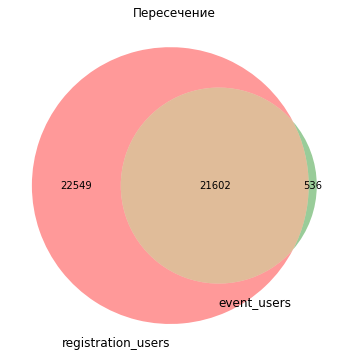

Количество уникальных зарегистрированных пользователей: 44151
Количество уникальных пользователей с событиями в приложении: 22138


In [ ]:
# Проверка на пересечение множеств уникальных пользователей в датасетах pa_marketplace_users.csv и pa_marketplace_events.csv
# с помощью диаграммы Венна
registration_user_id = set(pa_marketplace_users['user_id'].unique())
event_user_id = set(pa_marketplace_events['user_id'].unique())
order_user_id = set(pa_marketplace_orders['user_id'].unique())

# Задаем размер для фигуры
plt.figure(figsize=(6, 6))

# Строим диаграмму Венна
venn2([registration_user_id, event_user_id], set_labels=('registration_users', 'event_users'))

# Отображаем график
plt.title('Пересечение')
plt.show()

# Добавим сведения о количестве уникальных пользователей в каждом подмножестве
print(f"Количество уникальных зарегистрированных пользователей: {len(registration_user_id)}")
print(f"Количество уникальных пользователей с событиями в приложении: {len(event_user_id)}")

Диаграмма Венна показала, что 21602 уникальных пользователя, которые совершили действие в приложении (датасет `pa_marketplace_events.csv`), присутствуют в датасете с информацией о регистрациях пользователей (всего таковых 44151). Однако есть также события 536 пользователей, информация о которых отсутствует в датасете `pa_marketplace_users.csv`. Можно предположить, что эти пользователи зарегистрировались до 2024 года.


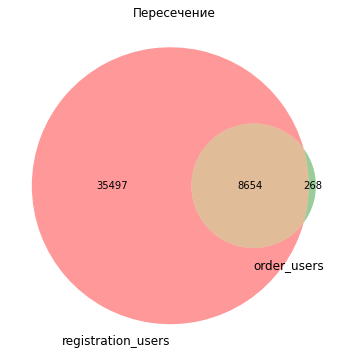

Количество уникальных зарегистрированных пользователей: 44151
Количество уникальных пользователей с заказами: 8922


In [ ]:
# Проверка на пересечение множеств уникальных пользователей в датасетах  pa_marketplace_users.csv и pa_marketplace_orders.csv

# Задаем размер для фигуры
plt.figure(figsize=(6, 6))

# Строим диаграмму Венна
venn2([registration_user_id, order_user_id], set_labels=('registration_users', 'order_users'))

# Отображаем график
plt.title('Пересечение')
plt.show()

# Добавим сведения о количестве уникальных пользователей в каждом подмножестве
print(f"Количество уникальных зарегистрированных пользователей: {len(registration_user_id)}")
print(f"Количество уникальных пользователей с заказами: {len(order_user_id)}")

Из 8922 уникальных пользователей, которые совершили заказ, для 268 пользователей нет информации в датасете с информацией о пользователях (`pa_marketplace_users.csv`). Опять же можно допустить, что эта часть аудитории зарегистрировалась до 2024 года.

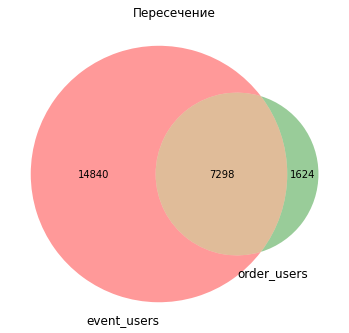

Количество уникальных пользователей с событиями в приложении: 22138
Количество уникальных пользователей с заказами: 8922


In [ ]:
# Проверка на пересечения множеств уникальных пользователей в датасетах  pa_marketplace_events.csv и pa_marketplace_orders.csv

# Задаем размер для фигуры
plt.figure(figsize=(6, 6))

# Строим диаграмму Венна
venn2([event_user_id, order_user_id], set_labels=('event_users', 'order_users'))

# Отображаем график
plt.title('Пересечение')
plt.show()

# Добавим сведения о количестве уникальных пользователей в каждом подмножестве
print(f"Количество уникальных пользователей с событиями в приложении: {len(event_user_id)}")
print(f"Количество уникальных пользователей с заказами: {len(order_user_id)}")

Среди 8922 уникальных пользователей, которые совершили заказ, есть 1624 аккаунта, для которых нет информации о действиях в датасете с пользовательскими событиями. Другими словами, действия (заказы) этой части аудиториии не отслежены среди пользовательских событий, что может повлиять на расчёт метрик (например, Retention, конверсия). <br>

Дополнительно проверим, как соотносится количество оформленных заказов (checkout_complete) и количество заказов (транзакций), а также количество уникальных пользователей, которые завершили оформление заказа, и тех, кто оплатил заказ.

Количество оформленных заказов: 84012
Количество транзакций: 31357


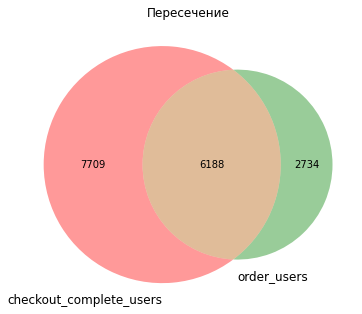

Количество уникальных пользователей, которые завершили оформление заказа: 13897
Количество уникальных пользователей с заказами (транзакциями): 8922


In [ ]:
# Фильтруем только завершенные заказы
checkout_complete_count = pa_marketplace_events[pa_marketplace_events['event_type'] == 'checkout_complete']

# Выводим количество оформленных заказов и транзакций
print(f"Количество оформленных заказов: {len(checkout_complete_count)}")
print(f"Количество транзакций: {len(pa_marketplace_orders)}")

# Фильтруем пользователей, которые завершили оформление заказа
user_checkout_complete = set(pa_marketplace_events[pa_marketplace_events['event_type'] == 'checkout_complete']['user_id'].unique())

# Задаем размер для фигуры
plt.figure(figsize=(6, 6))

# Строим диаграмму Венна
venn2([user_checkout_complete, order_user_id], set_labels=('checkout_complete_users', 'order_users'))

# Отображаем график
plt.title('Пересечение')
plt.show()

# Добавим сведения о количестве уникальных пользователей в каждом подмножестве
print(f"Количество уникальных пользователей, которые завершили оформление заказа: {len(user_checkout_complete)}")
print(f"Количество уникальных пользователей с заказами (транзакциями): {len(order_user_id)}")

Количество зафиксированных событий checkout_complete (84012) более чем в 2,5 раза превышает число транзакций (31357), а количество уникальных пользователей, оформивших заказ и оплативших различается в 1,5 раза (13897 и 8922, соответственно). Кроме того, выявлено 2734 пользователя, которые совершили покупку без прохождения логируемого этапа оформления. Такое расхождение указывает на технические проблемы логирования или наличие альтернативных способов совершения заказа. Эти обстоятельства будут учтены при дальнейшем анализе. <br>

Далее объединим таблицы: добавим в таблицу с событиями (`pa_marketplace_events`) и заказами (`pa_marketplace_orders`) информацио о пользователях из `pa_marketplace_users`.

In [ ]:
# Сохраним размер датафрейма до объединения
events_before_merge = pa_marketplace_events.shape[0]

# Добавляем в таблицу с событиями информацию о пользователях
pa_marketplace_events = (pd.merge(pa_marketplace_events, pa_marketplace_users[
                        ['user_id', 'region', 'acq_channel', 'buyer_segment', 'registration_date', 'cohort_week', 'cohort_month']],
                        how = 'left', on = 'user_id'))

# Сохраним размер датафрейма после объединения
events_after_merge = pa_marketplace_events.shape[0]

# Проверям не изменился ли размер датафрейма после объединения
print(f'Количество строк до объединения: {events_before_merge}; после: {events_after_merge}')



Количество строк до объединения: 785859; после: 785859


In [ ]:
# Сохраним размер датафрейма до объединения
orders_before_merge = pa_marketplace_orders.shape[0]

# Добавляем в таблицу с событиями информацию о пользователях
pa_marketplace_orders = (pd.merge(pa_marketplace_orders, pa_marketplace_users[
                        ['user_id', 'region', 'acq_channel', 'buyer_segment', 'registration_date', 'cohort_week', 'cohort_month']],
                        how = 'left', on = 'user_id'))

# Сохраним размер датафрейма после объединения
orders_after_merge = pa_marketplace_orders.shape[0]

# Проверям не изменился ли размер датафрейма после объединения
print(f'Количество строк до объединения: {orders_before_merge}; после: {orders_after_merge}')

Количество строк до объединения: 31357; после: 31357


**Промежуточный вывод**


В ходе первичного анализа датасетов установлено следующее:

*Пользовательская база и активность* <br>
Общая база зарегистрированных пользователей составляет 44151 человек. При этом в событийной части зафиксирована активность только 22138 уникальных пользователей (около 50% от зарегистрированных), а покупки совершили лишь 8922 уникальных пользователя (20% от зарегистрированных и 40 % от активных пользователей). Выявлено 536 активных пользователей (включая 268 покупателей), для которых нет информации о регистрации, каналах привлечения и т.д. в данных за 2024 год. Вероятно, это пользователи, пришедшие в сервис ранее. Для 1624 аккаунтов зафиксированы факты покупок при отсутствии данных о действиях в событийном логе. Это указывает на технический сбои в системе аналитики или на наличие альтернативных путей оформления заказа (например, "в один клик").

*Временной диапазон и расходы* <br>
Временной охват событий и заказов - с 1 января по 31 декабря 2024 года. Однако в датасете с маркетинговыми затратами обнаружены сведения за январь 2025 года, которые были исключены.

*Качество данных* <br>
Качество данных оценивается как высокое. Явные дубликаты отсутствуют во всех таблицах. В датасете `pa_marketplace_users.csv` выявлено 5 пар неявных дубликатов (совпадение времени регистрации, возраста и региона), что может указывать на то, что для 5 пользователей задублировались аккаунты (через разные источники). В таблице событий пропуски в поле product_name (51%) носят закономерный характер и зависят от типа события.

*Типы данных*  <br>
Все поля в целом соответствуют своим форматам. Для оптимизации памяти в числовых полях выполнено понижение разрядности.

*Предобработка* <br>
В таблице расходов выявлен и удален технический столбец Unnamed: 0.
В таблицы с пользовательскими событиями и заказами добавлены атрибуты пользователей (из `pa_marketplace_users`).

Данные пригодны для дальнейшего анализа. Будем также учитывать выявленные особенности по идентификаторам пользователей в разных датасетах.


### 2. Построить обзор ключевых метрик

На данном этапе проведем общую оценку текущего состояния маркетплейса на основе сформированных витрин данных. Задача заключается в получении целостной картины бизнеса без применения глубокой сегментации и детализации сложных срезов. Это позволит определить, соответствует ли продукт базовым ожиданиям, прослеживается ли положительная динамика и существуют ли критические сигналы в данных. <br>

Параметры и цели анализа: <br>
Монетизация: Выручка бизнеса рассчитывается как 5% комиссии от общей стоимости каждой продажи. <br>
Объект анализа: Общая динамика ключевых метрик за 2024 год. <br>

В процессе оценки проанализируем следующие показатели: <br>
**Экономика**: Динамику выручки (Revenue), среднего чека (AOV) и доходности на пользователя (ARPU). <br>
**Аудитория**: Посещаемость и активность пользователей в различных временных разрезах (MAU, WAU, DAU).<br>
**Удержание**: Жизненный цикл пользователя в продукте (Retention). <br>
**Эффективность воронки**: Конверсию из посещения в целевые действия. <br>


Итогом выполнения задания станет вывод о состоянии основных продуктовых метрик, который поможет зафиксировать текущую точку развития продукта.

<p style="font-size:20px"><strong>Revenue</strong></p>

Расчитаем и визуализируем **выручку** в продукте. Посмотрим на динамику по месяцам.

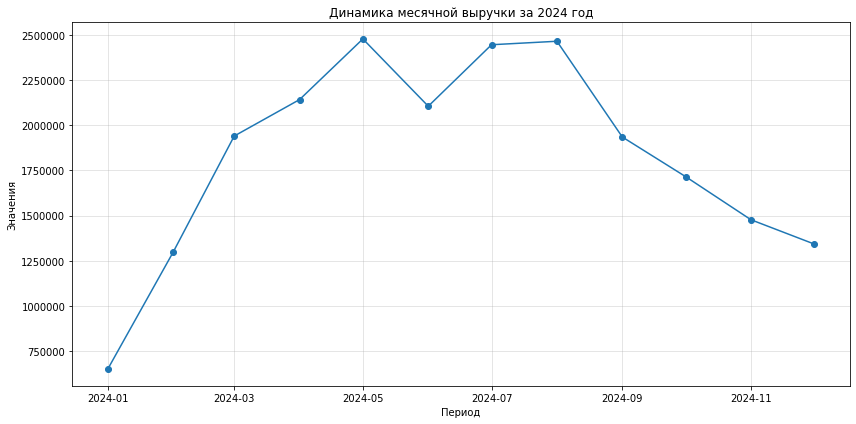

In [ ]:
# Рассчитываем выручку как 5% комиссии от общей стоимости продажи
pa_marketplace_orders['revenue'] = pa_marketplace_orders['total_price'] * 0.05

# Группируем данные по месяцам - суммируем выручку и количество заказов
revenue_per_month = pa_marketplace_orders.groupby('order_month')['revenue'].sum().reset_index()


# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(revenue_per_month['order_month'], revenue_per_month['revenue'], marker='o')

# Оформляем график
plt.title('Динамика месячной выручки за 2024 год')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

График показал динамику выручки с периодом роста в первой половине года и последующим снижением.<br>
Активный рост наблюжался с январь по май 2024 года: выручка выросла почти в 4 раза - примерно с 650 тыс. в январе до 2.5 млн в мае. После этого наблюдается стагнация в течении мая-августа: выручка стабилизировалась на уровне примерно 2.1–2.5 млн. Снижение выручки наблюдается с сентября по декабрь: выручка сократилась почти вдвое относительно пиковых значений, опустившись до уровня 1.35 млн.

Дальше посмотрим на метрики, на которые выручка раскладывается (т.е. на компоненты выручки), чтобы понять, почему она снижается:
- Средний чек (AOV)
- Количество заказов


<p style="font-size:20px"><strong>AOV</strong></p>

Посмотрим на динамику среднего чека (AOV).

При знакомстве с данными было обнаружено, что поле `order_id` является идентификатором товарной позиции, а не заказа: в один и тот же момент времени (с точностью до секунды) пользователь мог приобрести несколько товаров, при этом каждому из них был присвоен уникальный `order_id`. Следовательно, расчет AOV как "общая выручка / количество уникальных order_id" даст нам среднюю стоимость товарной позиции (или товара), а не чека. Для корректного расчета мы будем агрегировать транзакции по связке пользователя и времени покупки, определяя "заказ" как все товары, приобретенные пользователем единовременно.

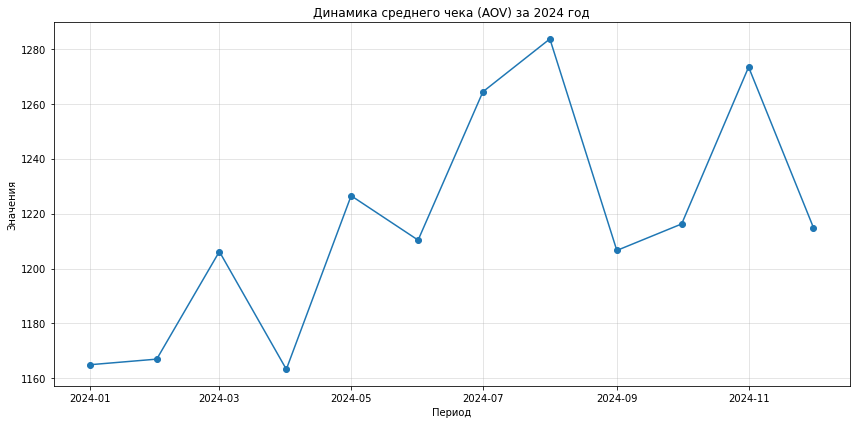

In [ ]:
# Формируем таблицу, где каждая строка - это выручка за уникальный заказ
# (суммируем выручку по товарам, приобретенным в одно время)
unique_orders = pa_marketplace_orders.groupby(['user_id', 'order_date', 'order_month'])['revenue'].sum().reset_index()

# Группируем данные по месяцам и рассчитываем средний чек (AOV)
aov_per_month = unique_orders.groupby('order_month')['revenue'].mean().reset_index(name='aov')

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(aov_per_month['order_month'], aov_per_month['aov'], marker='o')

# Оформляем график
plt.title('Динамика среднего чека (AOV) за 2024 год')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

График помесячной динамики среднего чека показал относительную стабильность показателя в течение 2024 года с небольшим трендом к росту. На протяжении всего года значение AOV колебалось в узком диапазоне - примерно от 1165 до 1284. Незначительный рост наблюдался с января по август: средний чек увеличился с 1165 до 1284 в августе. Далее последовала стабилизация: показатель удерживался на уровне 1200-1270. В отличие от выручки, которая сократилась вдвое к концу года (по сравнению с серединой года - когда было зафисировано пиковые значения), средний чек к декабрю снизился, но не так сильно. Это говорит о том, что падение выручки связано скорее с сокращением общего количества заказов.





<p style="font-size:20px"><strong>Количество заказов</strong></p>

Посмотрим на динамику количества заказов по месяцам.
Опять же, ранее выяснилось, что поле `order_id` - это скорее идентификатор товарной позиции. Поэтому будем считать количество заказов через связку инеднитификатор пользователя и время покупки.

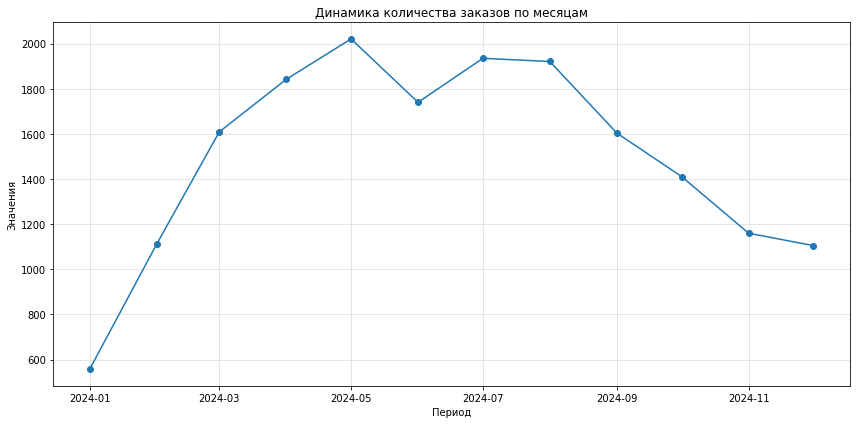

In [ ]:
# Формируем список уникальных заказов (объединяем товары, купленные одномоментно, в один заказ)
unique_orders = pa_marketplace_orders.groupby(['user_id', 'order_date', 'order_month']).size().reset_index()

# Группируем данные по месяцам
orders_per_month = unique_orders.groupby('order_month').size().reset_index(name='order_count')

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(orders_per_month['order_month'], orders_per_month['order_count'], marker='o')

# Оформляем график
plt.title('Динамика количества заказов по месяцам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


График динамики количества заказов повторяет общую тенденцию выручки: рост в первой половине 2024 года и последующий спад во второй. Активный рост числа заказов наблюдался с января по май, когда показатель увеличился почти в 4 раза: примерно с 550 до 2020 заказа в месяц. В летний период количество заказов стабилизировалось на уровне 1750–1950. Начиная с сентября и до декабря количество заказов сократилось почти вдвое относительно пика, опустившись до 1100. Сравнение этого графика с динамикой среднего чека подтверждает, что именно сокращение числа транзакций, а не изменение стоимости покупок, стало фактором падения выручки во втором полугодии.

Далее посмотрим на составляющие количества заказов: метрики активности (DAU, WAU, MAU) и конверсию.

<p style="font-size:20px"><strong>DAU, WAU, MAU</strong></p>
Теперь рассмотрим посещаемость и активность пользователей в различных временных разрезах (DAU, WAU, MAU).
Также будем учитывать активность (заказы) 1624 клиентов из таблицы с заказами.

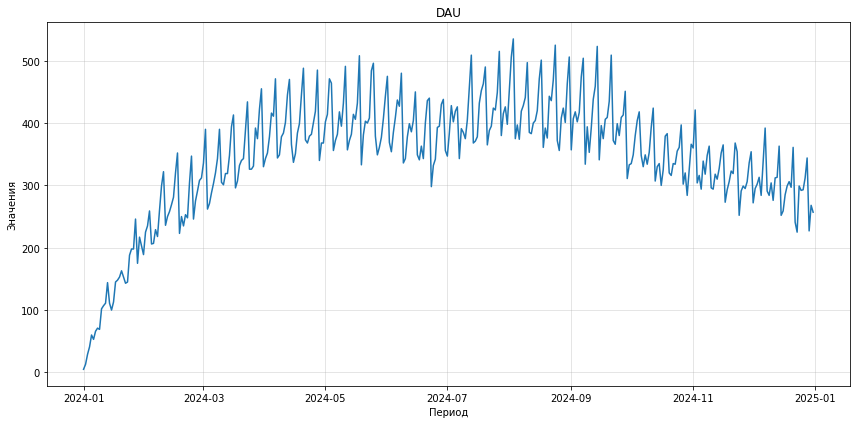

In [ ]:
# Выбираем пользователей из таблицы с событиями
active_users_events = pa_marketplace_events[['event_date', 'event_week', 'event_month', 'user_id', 'region', 'acq_channel', 'buyer_segment']]
active_users_events['event_date'] = active_users_events['event_date'].dt.date

# Выбираем уникальных пользователей из таблицы с заказами
active_users_orders = (pa_marketplace_orders[['order_date', 'order_week', 'order_month', 'user_id', 'region', 'acq_channel', 'buyer_segment']]
                .rename(columns={'order_month': 'event_month', 'order_week': 'event_week', 'order_date': 'event_date'}))
active_users_orders['event_date'] = active_users_orders['event_date'].dt.date

# Объединяем логи событий и заказов, удаляя полные дубликаты строк.
# Это позволяет получить уникальные факты активности пользователей за каждый день,
# включая тех клиентов, которые совершили покупку, но отсутствуют в таблице событий.
all_active_users = pd.concat([active_users_events, active_users_orders]).drop_duplicates()

# Рассчитываем DAU
dau = all_active_users.groupby('event_date')['user_id'].nunique().reset_index()

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(dau['event_date'], dau['user_id'])

# Оформляем график
plt.title('DAU')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

График DAU демонстрирует стабильный рост ежедневной аудитории в первой половине года с последующим снижением в четвертом квартале. Активный рост наблюдался с января по май 2024 года: показатель увеличился с нескольких десятков до 450 уникальных пользователей в день. В период с июня по октябрь метрика стабилизировалась и колебалась в диапазоне 400–450 пользователей. Начиная с октября зафиксировано падение метрики: к концу года DAU снизился до уровня примерно 300.

Далее рассчитаем WAU, чтобы оценить недельную активность пользователей.

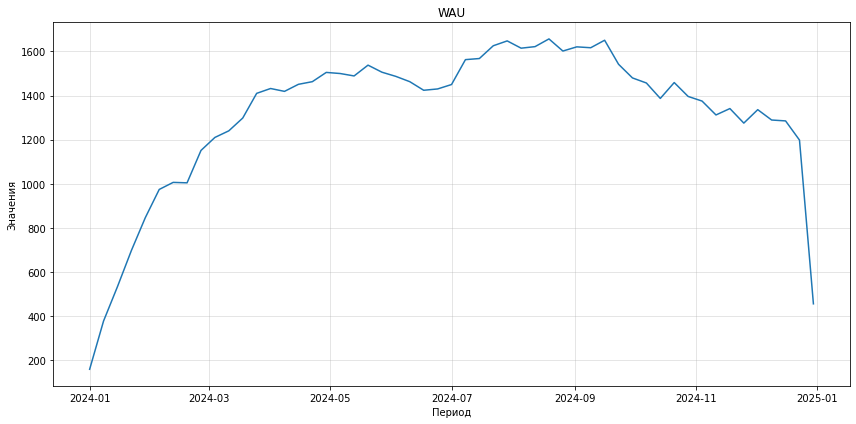

In [ ]:
# Рассчитываем WAU
wau = all_active_users.groupby('event_week')['user_id'].nunique().reset_index()

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(wau['event_week'], wau['user_id'])

# Оформляем график
plt.title('WAU')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

График WAU подтверждает общую динамику посещаемости: активный рост в начале года, затем стабилизация и последующий спад в четвертом квартале. Активный рост недельной аудитории наблюдался с января по май 2024 года, когда показатель увеличился с примерно 15о до 1500 уникальных пользователей. Далее последовал период относительной стабильности (июнь–сентябрь), в течение которого метрика удерживалась в диапазоне 1400–1650 пользователей в неделю, достигнув пика в августе. Начиная с октября метрика снижается и к середине декабря доходит до 1200–1300. Обращает на себя внимание резкое падение MAU в последнюю неделю года до 455.

Далее рассчитаем MAU

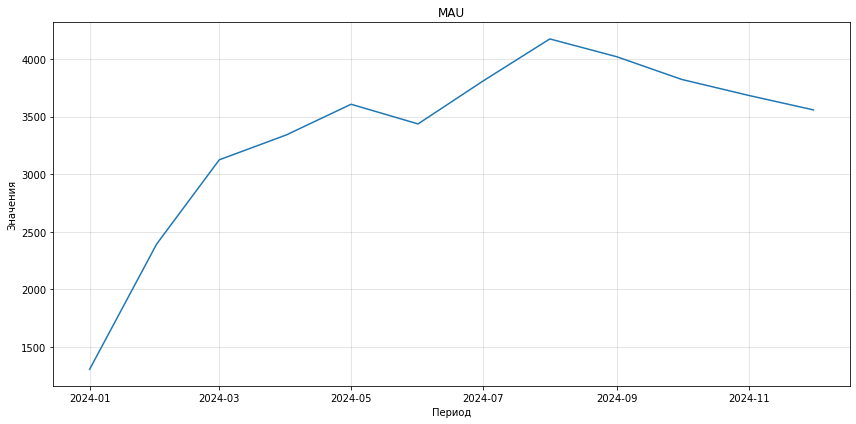

In [ ]:
# Рассчитываем MAU
mau = all_active_users.groupby('event_month')['user_id'].nunique().reset_index()

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(mau['event_month'], mau['user_id'])

# Оформляем график
plt.title('MAU')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

С января по май наблюдался интенсивный рост ежемесячной аудитории - показатель увеличился практически в 3 раза: с 1300 до 3600 уникальных пользователей. Пик активности пришелся на август - около 4150 уникальных посетителей. Начиная с сентября наметилась устойчивая отрицательная динамика: к декабрю активная аудитория сократилась примерно до 3600 пользователей.

Таким образом, анализ  DAU, WAU, MAU выявил общую проблему: после уверенного роста в первой половине года продукт начал терять активную аудиторию в четвертом квартале.

Далее необходимо выяснить, почему активная аудитория снижается. Для этого посмотрим на динамику привлечения новых пользователей и ужержание (Retention).

<p style="font-size:20px"><strong>Динамика привлечения новых пользователей</strong></p>


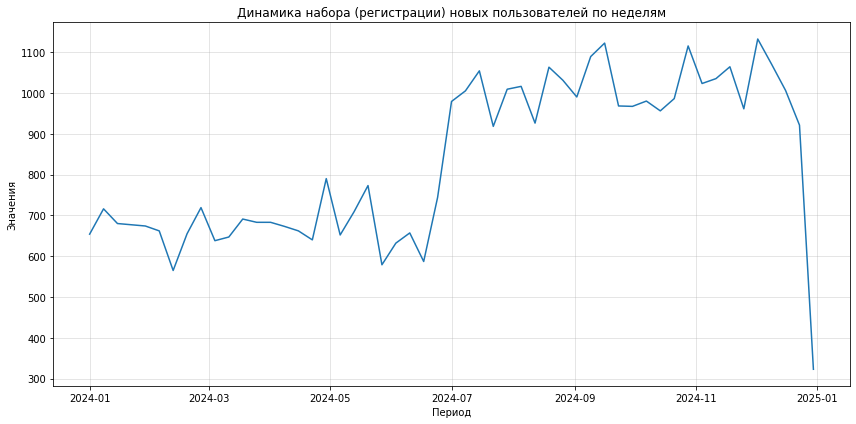

In [ ]:
# Группируем данные по неделе регистрации (привлечения), считаем уникальных пользователей за каждую неделю
new_users_per_week = pa_marketplace_users.groupby('cohort_week')['user_id'].nunique().reset_index()

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(new_users_per_week['cohort_week'], new_users_per_week['user_id'])

# Оформляем график
plt.title('Динамика набора (регистрации) новых пользователей по неделям')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


На графике видно, что количество привекаемых пользователей в продукт выросло за счёт одного резкого скачка в июле 2024 года. До неге и после прирост колеблется, но в целом стабилен. В первой половине 2024 года (январь–июнь) приток новых пользователей был на уровне 600–700 человек в неделю. Начиная с июля показатель вырос до 950–1100 новых пользователей еженедельно и удерживался на этих значениях до конца года. В последнюю неделю 2024 года наблюдается резкое падение.

Стоит обратить внимание на то, в то время как количество новых пользователей с июля выросло практически в 1.5 раза, общие показатели активности (DAU, WAU, MAU) и выручки в этот же период начали падать. Скорее всего, проблема не в количестве прироста новой аудитории, а в ее качестве или в снижении удержания новых когорт. Далее расчитаем и визуализируем метрику удержания.

<p style="font-size:20px"><strong>Retention</strong></p>
Рассчитаем и визуализируем ретеншн.
В качестве когорт возьмем месяц регистрации. Проверим повторные возвращения в приложения и и повторные заказы по месяцам.

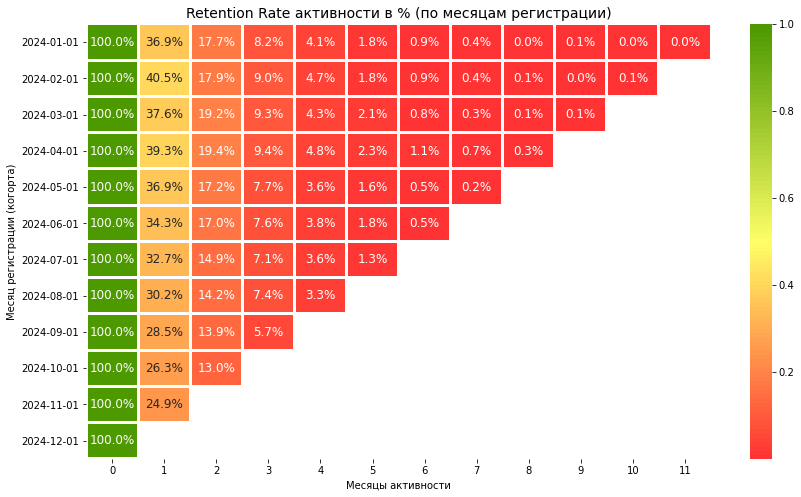

In [ ]:
# Вычитаем месяц активности из месяца решитсрации
pa_marketplace_events['n_month'] = (
    pa_marketplace_events['event_month'].dt.to_period('M').astype(int) -
    pa_marketplace_events['cohort_month'].dt.to_period('M').astype(int)
)

# Формируем сводную таблицу удержания
event_retention_pivot = pa_marketplace_events.pivot_table(
    index='cohort_month',
    columns='n_month',
    values='user_id',
    aggfunc='nunique'
)

# Заменяем для месяца региатрации (0 месяц) данные о регистрациях пользователей из таблицы pa_marketplace_users
cohort_sizes = pa_marketplace_users.groupby('cohort_month')['user_id'].nunique()
event_retention_pivot[0] = cohort_sizes

# Рассчитываем долю удержания
event_retention_pivot = event_retention_pivot.div(event_retention_pivot[0], axis=0)

# Оформление индекса для визуализации тепловой карты (даты в строках)
event_retention_pivot.index = event_retention_pivot.index.strftime('%Y-%m-%d')

# Строим тепловую карту
plt.figure(figsize=(14, 8))
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)

sns.heatmap(event_retention_pivot,
            annot=True,
            fmt='.1%',
            cmap=cmap,
            linewidths=2,
            annot_kws={"size": 12})

plt.title('Retention Rate активности в % (по месяцам регистрации)', fontsize=14)
plt.xlabel('Месяцы активности')
plt.ylabel('Месяц регистрации (когорта)')
plt.show()


Тепловая карта удержания пользователей в продукте по когортам (месяц регистрации) демонстрирует устойчивое снижение возвращаемости новых пользователей от начала года к его концу. На карте видно падение удержания первого месяца по когортам: у  когорт с января по май возвращаемость в первый месяц составляла 37-40%, а начиная с лета показатель начал снижаться и к ноябрю он упал до 25%. Значит к этому моменту продукт начал терять три четвертых привлеченной аудитории уже на следующий месяц после регистрации. Похожая динамика прослеживается и на более длинной дистанции "жизни" посльзователей. Удержание второго месяца  сократилось с 18-19% в весенних когортах до 13% в октябрьской. При этом во всех когортах к третьему месяцу жизни пользователя показатель опускается ниже 10% и тоже ухуджается от весенних к осенним когортам (с 8-9% до 5.7%). После 3 месяца показатель становится меньше 5%, а после 6 месяца меньше 1%. Такое системное снижение ретеншн во второй половине года на фоне растущего числа привлеченных пользвателей указывает на то, что приходящий трафик стал менее качественным (вовлечённым), либо продукт перестал вовлекать новых пользователей так же эффективно, как в начале года.

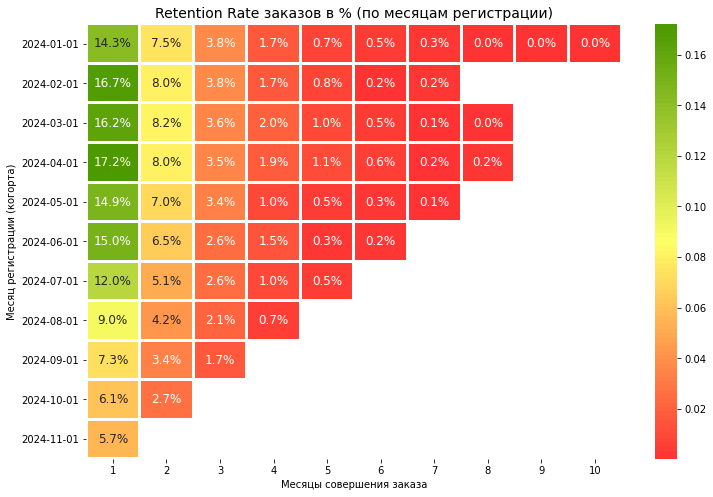

In [ ]:
# Вычитаем месяц заказа из месяца регистрации
pa_marketplace_orders['n_month'] = (
    pa_marketplace_orders['order_month'].dt.to_period('M').astype(int) -
    pa_marketplace_orders['cohort_month'].dt.to_period('M').astype(int)
)

# Формируем матрицу удержания в заказы
order_retention_pivot = pa_marketplace_orders.pivot_table(
    index='cohort_month',
    columns='n_month',
    values='user_id',
    aggfunc='nunique'
)

# Заменяем данные для 0 месяца на общее количество регистраций из pa_marketplace_users
order_retention_pivot[0] = cohort_sizes

# Рассчитываем долю удержания
order_retention_pivot = order_retention_pivot.div(order_retention_pivot[0], axis=0)

# Удаляем столбец 0 (нелевой месяц) для лучшей визуализаци
order_retention_pivot = order_retention_pivot.drop(columns=[0])

# Оформление индекса для визуализации (даты в строках)
order_retention_pivot.index = order_retention_pivot.index.strftime('%Y-%m-%d')

# Строим тепловую карту
plt.figure(figsize=(12, 8))
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)

sns.heatmap(order_retention_pivot[:-1],
            annot=True,
            fmt='.1%',
            cmap=cmap,
            linewidths=2,
            annot_kws={"size": 12})

plt.title('Retention Rate заказов в % (по месяцам регистрации)', fontsize=14)
plt.xlabel('Месяцы совершения заказа')
plt.ylabel('Месяц регистрации (когорта)')
plt.show()


Тепловая карта удержания платящих пользователей в продукте по когортам (месяц регистрации) показывает в целом схожую тенденцию, что и удержаение пользователей (посетителей маркетплейса). По когортам виден спад по покупам на первый месяц (или иначе следующий месяц) после регистрации: в первой половине года показатель находится на уровне 15-17%, во втором постепенно падает до 6%. Такое снижение прослеживается и на следующих месяцах жизни пользователя. На 3 месяц повторные покупки совершают меньше 5% покупателей в когортах (при этом показатель снижается от январской когорты к сентябрьской). После 5 месяца удержание для всех когорт становится меньше 1%. Таким образом, клиенты, которые пришли летом и позже тоже указывает на то, что в продукт пришла менее вовлечённая (лояльная) аудитория.

<p style="font-size:20px"><strong>Конверсия (CR): классическая и пошаговая воронки</strong></p>
В этой части расчитаем и визуализируем конверсии в целом и в динамике по месяцам.



У нас есть следующий список событий (поле `event_type`) в таблице с пользовательскими событиями.

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


Пути пользователя в приложении могут быть очень разными. Чтобы построить осмысленную воронку и проследить, какая часть пользователей доходят до целевого действия (завершение офорления заказа), выберем несколько шагов. Для этого посмотрим на часть действий одного пользователя.

In [ ]:
# Выводим часть действий пользователя в приложении
pa_marketplace_events[pa_marketplace_events['user_id'] == 3].head(16)

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month,region,acq_channel,buyer_segment,registration_date,cohort_week,cohort_month,n_month
37,55,3,2024-01-02,page_view,Android,mobile,NaN,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
38,56,3,2024-01-02,product_view,Android,mobile,Коляска трансформер,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
39,57,3,2024-01-02,product_click,Android,mobile,Анкер PowerBank,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
40,58,3,2024-01-02,add_to_cart,Android,mobile,Мяч футбольный,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
41,59,3,2024-01-02,checkout_start,Android,mobile,NaN,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
228,48,3,2024-01-03,page_view,Android,mobile,NaN,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
229,49,3,2024-01-03,product_view,Android,mobile,Стол обеденный,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
230,50,3,2024-01-03,product_click,Android,mobile,Светильник настольный,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
231,51,3,2024-01-03,add_to_cart,Android,mobile,Шарф кашемировый,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0
232,52,3,2024-01-03,checkout_start,Android,mobile,NaN,2024-01-01,2024-01-01,Санкт-Петербург,Google Ads,regular,2024-01-01 04:13:00,2024-01-01,2024-01-01,0


Для воронки выберем следующие четыре события:
- product_view,
- add_to_cart,
- checkout_start,
- checkout_complete

In [ ]:
# Задаём порядок шагов воронки пользовательского пути
funnel_steps = ['product_view',
                'add_to_cart',
                'checkout_start',
                'checkout_complete']

# Отсавляем только события нашей воронки
events_filtered = pa_marketplace_events[pa_marketplace_events['event_type'].isin(funnel_steps)]

# Считаем уникальных пользователей на каждом шаге и сортируем по порядку воронки
funnel_data = events_filtered.groupby('event_type')['user_id'].nunique().reindex(funnel_steps).reset_index(name='users_n')

# Строим классическая воронка
funnel_data['conversion_%'] = ((funnel_data['users_n'] / funnel_data['users_n'].iloc[0]) * 100).round(1)

# Строим step‑by‑step воронку
funnel_data['conversion_from_previous_step_%'] = (funnel_data['users_n'] / funnel_data['users_n'].shift(1) * 100).round(1)

# Выводим таблицу
display(funnel_data)

,event_type,users_n,conversion_%,conversion_from_previous_step_%
0,product_view,22069,100.0,NaN
1,add_to_cart,20411,92.5,92.5
2,checkout_start,16769,76.0,82.2
3,checkout_complete,13897,63.0,82.9


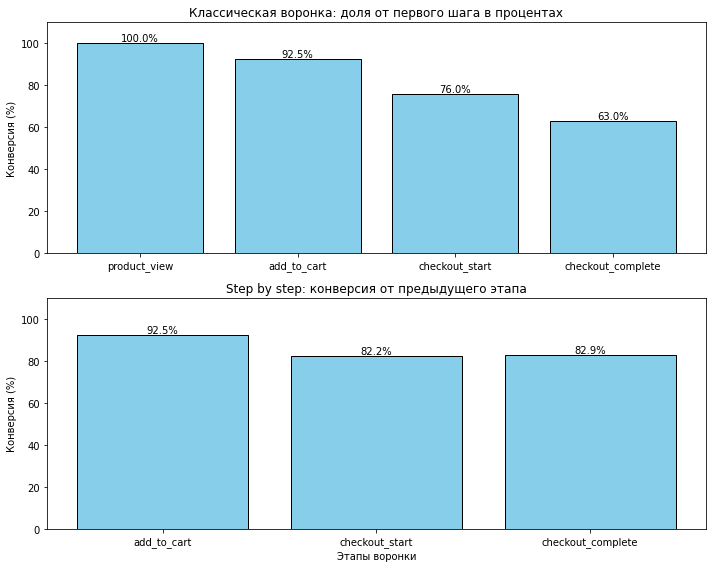

In [ ]:
# Строим две столбчатые диаграммы
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Классическая воронка, отфильтрованная с шага introduction
axes[0].bar(funnel_data['event_type'], funnel_data['conversion_%'], color='skyblue', edgecolor='black')
axes[0].set_title('Классическая воронка: доля от первого шага в процентах')
axes[0].set_ylabel('Конверсия (%)')
axes[0].set_ylim(0, 110)
# Добавляем подписи значений на столбцы
for x, y in zip(funnel_data['event_type'], funnel_data['conversion_%']):
    if pd.notna(y):
        axes[0].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

# Step by step воронка, отфильтрованная с шага registration
axes[1].bar(funnel_data['event_type'][1:], funnel_data['conversion_from_previous_step_%'][1:], color='skyblue', edgecolor='black')
axes[1].set_title('Step by step: конверсия от предыдущего этапа')
axes[1].set_ylabel('Конверсия (%)')
axes[1].set_xlabel('Этапы воронки')
axes[1].set_ylim(0, 110)
# Добавляем подписи значений
for x, y in zip(funnel_data['event_type'][1:], funnel_data['conversion_from_previous_step_%'][1:]):
    if pd.notna(y):
        axes[1].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()


*Классическая воронка* <br>
Значительная часть пользователей, открывший страницу с товаром доходит до этапа добавления товара в корзину (92.5%). Заметная потеря пользователей происходит на шаге начала оформления заказа - практически четверть от всех, кто просмотрел карточку товара (24%). Завершают оформление (checkout_complete) 63% пользователей. Таким образом, до завершения оформления заказа в приложении доходит примерно каждый третий из пяти зашедших. Стоит принимать во внимание особенность, которая была выявлена на этапе знакомства с данными: фактическую оплату совершают 8922 пользователя (из 13897), при этом 2734 из них покупают товары минуя этап завершения оформления заказа. Таким образом, если продолжать воронку до оплаты заказа, то мы получим 6188 платящих клиентов, что составляет 28% от всех зашедших в приложение пользователей.

*Воронка step-by-step* <br>
При переходе к корзине (add_to_cart) из просмотра конкретного товара конверсия достаточно высокая - 92.5%. Снижение обнаружено на этапе начала оформления заказа (checkout_start), где 82.2% пользователй доходят до этого шага, то есть на этом шаге теряется 17.8% пользователей. На финальном этапе завершения оформления (checkout_complete) конверсия сопоставима и составляет 82.9%. Основные потери аудитории внутри приложения распределены равномерно между этапами формирования корзины и завершения заказа. Если мы достоим воронку до оплаты заказа (6188 пользователей), то увидим, что с завершения оформления заказа до оплаты теряется около 55.5% аудитории.

Чтобы проиллюстрировать конверсию по всем шагам воронки, включая регистрацию и оплату заказа, снова рассчитаем воронку и сделаем визуализацию. Для этого будем использовать также таблицы с пользователями (посчитаем количество зарегистррованных пользователей) и заказами (посчитаем количество пользователей, которые совершили оплату).

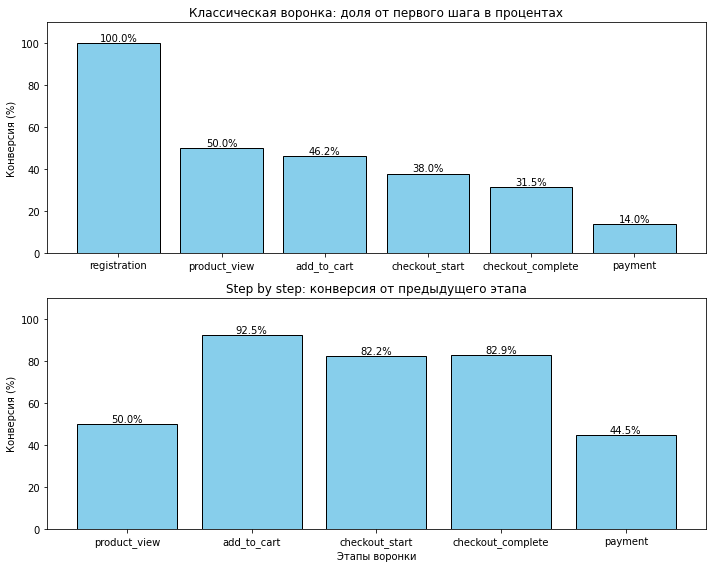

In [ ]:
# Получаем список индентификаторы тех, кто завершил оформление в приложении
completed_in_events = pa_marketplace_events[pa_marketplace_events['event_type'] == 'checkout_complete']['user_id'].unique()

# Считаем уникальных платящих пользователей, которые завершили оформления заказа
pay_users_n = pa_marketplace_orders[pa_marketplace_orders['user_id'].isin(completed_in_events)]['user_id'].nunique()

# Считаем уникальных зарегистрированных пользователей
registrated_users = pa_marketplace_users['user_id'].nunique()

# Создаем новую строку c количеством зарегистрированных для воронки
registration_step = pd.DataFrame({'event_type': 'registration', 'users_n': [registrated_users]})

# Создаем новую строку c оплатой для воронки
payment_step = pd.DataFrame({'event_type': 'payment', 'users_n': [pay_users_n]})

# Соединяем новые строки с основной воронкой
funnel_data_extended = pd.concat([registration_step, funnel_data, payment_step], ignore_index=True)

# Пересчитываем конверсии
funnel_data_extended['conversion_%'] = (funnel_data_extended['users_n'] / funnel_data_extended['users_n'].iloc[0] * 100).round(1)
funnel_data_extended['conversion_from_previous_step_%'] = (funnel_data_extended['users_n'] / funnel_data_extended['users_n'].shift(1) * 100).round(1)

# Строим две столбчатые диаграммы
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Классическая воронка, отфильтрованная с шага introduction
axes[0].bar(funnel_data_extended['event_type'], funnel_data_extended['conversion_%'], color='skyblue', edgecolor='black')
axes[0].set_title('Классическая воронка: доля от первого шага в процентах')
axes[0].set_ylabel('Конверсия (%)')
axes[0].set_ylim(0, 110)
# Добавляем подписи значений на столбцы
for x, y in zip(funnel_data_extended['event_type'], funnel_data_extended['conversion_%']):
    if pd.notna(y):
        axes[0].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

# Step by step воронка, отфильтрованная с шага registration
axes[1].bar(funnel_data_extended['event_type'][1:], funnel_data_extended['conversion_from_previous_step_%'][1:], color='skyblue', edgecolor='black')
axes[1].set_title('Step by step: конверсия от предыдущего этапа')
axes[1].set_ylabel('Конверсия (%)')
axes[1].set_xlabel('Этапы воронки')
axes[1].set_ylim(0, 110)
# Добавляем подписи значений
for x, y in zip(funnel_data_extended['event_type'][1:], funnel_data_extended['conversion_from_previous_step_%'][1:]):
    if pd.notna(y):
        axes[1].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()


**Переход из регистации к просмотру товара** (из `registration` в `product_view`) <br>
Происходит резкий отсев аудитории - только 50% зарегистрированных пользователей доходят до просмотра товаров. Это означает, что каждый второй привлеченный пользователь становится неактивным сразу после создания аккаунта, так и не приступив к просмотру товаров.

**Финал воронки** (из `сheckout_сomplete` в `payment`) <br>
При оплате заказа происходит критическое падение: его завершают всего лишь 44.5% из тех, кто офорил заказ.

Из 44151 зарегистрированного пользователя до реальной покупки доходят лишь 6188 (общая конверсия 14%). Основной потенциал роста выручки скрыт в устранении барьеров именно на этих двух этапах: активации новичков и завершении платежей.

Теперь посмотрим на конверсию в динамике: стоит проверить, как меняется конверсия - от просмотра конкретного товара к завершению оформления заказа по месяцам.

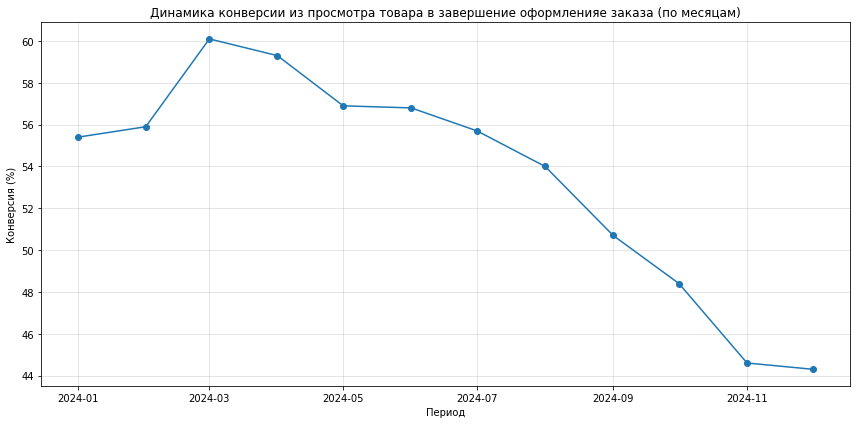

In [ ]:
# Считаем уникальных пользователей для каждого нужного события по месяцам
# Берем два шага: просмотр товара и завершение оформления заказа
events_subset = pa_marketplace_events[pa_marketplace_events['event_type'].isin(['product_view', 'checkout_complete'])]

# Создаем сводную таблицу: месяцы в строках, типы событий в столбцах
dynamic_cr = events_subset.pivot_table(
    index='event_month',
    columns='event_type',
    values='user_id',
    aggfunc='nunique'
).reset_index()

# Рассчитываем конверсию
dynamic_cr['cr_step_%'] = (dynamic_cr['checkout_complete'] / dynamic_cr['product_view'] * 100).round(1)

#  Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(dynamic_cr['event_month'], dynamic_cr['cr_step_%'], marker='o')

# Оформляем график
plt.title('Динамика конверсии из просмотра товара в завершение оформленияе заказа (по месяцам)')
plt.xlabel('Период')
plt.ylabel('Конверсия (%)')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()



График динамики конверсии из просмотра товара в завершение оформления заказа (от `product_view` к `checkout_complete`) показал устойчивый нисходящий тренд во второй половине года. В первой половине 2024 года показатель колебался в диапазоне 55–60%, достигнув пика в марте (60%). Начиная с августа метрика постепенна падает: к декабрю конверсия сократилась примерно до 44%. Таким образом, за последние четыре месяца 2024 года вероятность того, что просмотр товара завершится оформлением заказа, снизилась более чем на четверть относительно средних годовых значений.

Скорее всего, во второй половине года также снижается и финальная конверсия в покупку заказа. Чтобы проверить это предположение построим график с динамикой конверсии из завершения оформления заказа в оплату заказа.

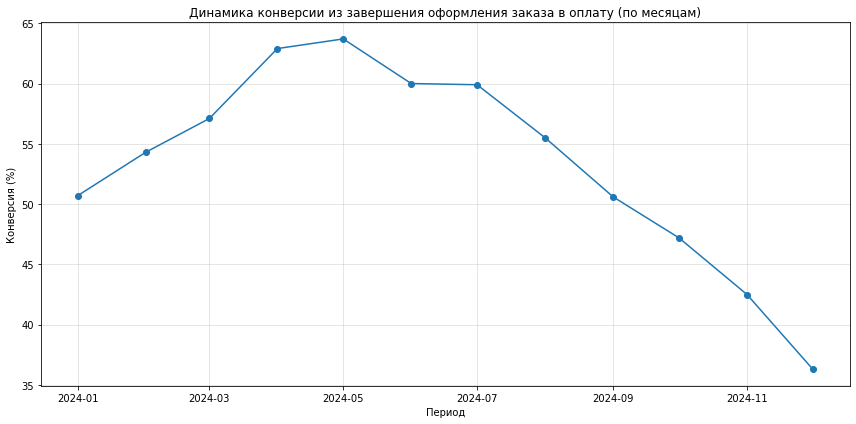

In [ ]:
# Считаем  количество пользователей по месяцам (отфильтрованных по таблице с пользовательских событий на шаге завершение оформления заказа)
payrs_per_month = pa_marketplace_orders[pa_marketplace_orders['user_id'].isin(completed_in_events)].groupby('order_month')['user_id'].nunique().reset_index(name='payments')

# Объединяем с таблицей dynamic_cr
complite_orders_to_transaction = pd.merge(dynamic_cr[['event_month', 'checkout_complete']], payrs_per_month[['order_month', 'payments']], left_on='event_month', right_on='order_month', how='left').drop(columns='order_month')

# Считаем конверсию из оформления в оплату
complite_orders_to_transaction['cr_%'] = (complite_orders_to_transaction['payments'] / complite_orders_to_transaction['checkout_complete'] * 100).round(1)

#  Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(complite_orders_to_transaction['event_month'], complite_orders_to_transaction['cr_%'], marker='o')

# Оформляем график
plt.title('Динамика конверсии из завершения оформления заказа в оплату (по месяцам)')
plt.xlabel('Период')
plt.ylabel('Конверсия (%)')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


В первой половине 2024 года конверсия из завершения оформления заказа в оплату заказа росла, достигнув пика в мае  (63.7%). Однако, начиная с июня, метрика постоянно снижается: к декабрю конверсия в оплату упала почти вдвое, составив всего 36.3%. Таким образом, если в начале года более половины оформленных заказов завершались транзакцией, то к концу года этот показатель снизился примерно до каждого третьего заказа.

<p style="font-size:20px"><strong>Промежуточный вывод: обзор ключевых метрик</strong></p>

**Продуктовые метрики** <br>
Анализ показал, что за годовым ростом **выручки** (пик в мае) последовала стагнация и падение к декабрю до уровня начала года.

Декомпозиция выявила следующие причины:
- **Относительно стабильный средний чек**: AOV сохраняет устойчивость (1200-1270) и не является фактором падения выручки.
- **Сокращение количества заказов**: объем заказов упал почти вдвое относительно пика, повторяя тренд выручки.
- **Снижение DAU, WAU, MAU**: после  роста в первой половине года продукт начал терять активную аудиторию в четвертом квартале.
- **Ухудшение конверсии**: конверсия в оформление и оплату во втором полугодии снизилась до уровней ниже январских, при этом критический провал зафиксирован на этапе перехода к оплате.
- **Проблемы с удержанием**: несмотря на рост притока новой аудитории с июля, Retention (активности и заказов) во второй половине года последовательно снижается.

Маркетплейс теряет выручку не из-за снижения среднего чека или нехватки притока новой аудитории, а скорее из-за ухудшения качества новой аудитории и снижения конверсии внутри приложения.

### 3. Оценка метрик монетизации и юнит-экономики

Теперь выполним анализ монетизации: определим, сколько зарабатывает продукт и сколько тратит на привлечение.

Посмотрим на агрегированные метрики (ARPU и AOV) и показатели эффективности (CAC, ROI, Payback Period).



<p style="font-size:20px"><strong>AOV</strong></p>

На предыдущем этапе мы рассмотрели **средний чек (AOV)**: наблюдался небольшой рост до августа. Метрика сильно колеблется от месяца к месяцу и к концу года не демонстирует ни роста, ни падения. Но в целом диапозон колебаний небольшой: примерно от от 1165 до 1284.
![image.png](attachment:image.png)

<p style="font-size:20px"><strong>ARPU</strong></p>

Рассчитаем и визуализируем динамику ARPU (среднюю выручку на пользователя)
Поскольку, как выяснилось ранее, в таблице с заказами есть 1624 клиента (платящих пользователей), действий которых нет в таблице с пользовательскими событиями, для расчета ARPU мы объединим уникальных id пользователей из двух этих таблиц.

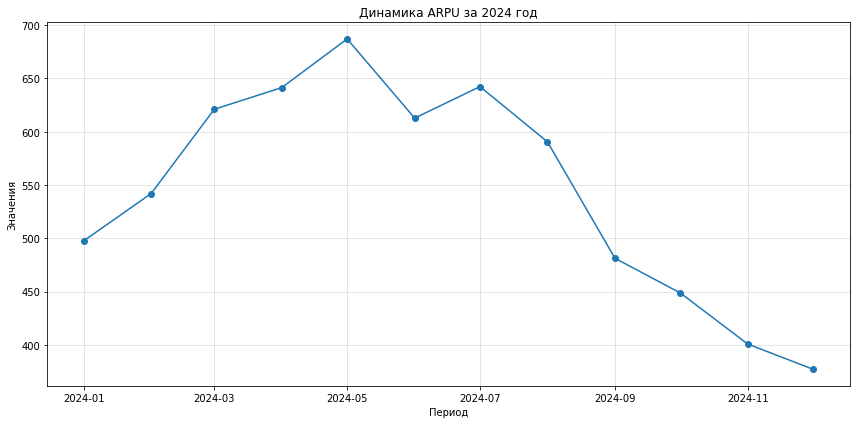

In [ ]:
# Выбираем уникальных пользователей из таблицы с событиями по месяцам
events_users = pa_marketplace_events[['event_month', 'user_id', 'region', 'acq_channel', 'buyer_segment']]

# Выбираем уникальных пользователей из таблицы с заказами
orders_users = pa_marketplace_orders[['order_month', 'user_id', 'region', 'acq_channel', 'buyer_segment']].rename(columns={'order_month': 'event_month'})

# Склеиваем таблицы, убрав полные дубликаты (пользователь + месяц), и рассчитываем общее количество уникальных пользователей по месяцам
all_users = pd.concat([events_users, orders_users]).drop_duplicates()
users_per_month = all_users.groupby('event_month')['user_id'].nunique().reset_index(name='users_count')

# Объединяем данные по выручке и количеству уникальных пользователей
arpu_per_month = pd.merge(revenue_per_month, users_per_month, how='inner', left_on='order_month', right_on='event_month')
arpu_per_month = arpu_per_month.drop(columns=['order_month'])

# Рассчитываем ARPU
arpu_per_month['arpu'] = arpu_per_month['revenue'] / arpu_per_month['users_count']

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(arpu_per_month['event_month'], arpu_per_month['arpu'], marker='o')

# Оформляем график
plt.title('Динамика ARPU за 2024 год')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

График динамики ARPU показал рост метрики в первой половине года с последующим снижением. Активный рост наблюдался с января по май 2024 года: показатель увеличился с 497 до 687. Далее последовал период относительной стабилизации в июне-августе на уровне 590–640. Начиная с сентября метрика падает: к декабрю ARPU сократился почти в два раза относительно пиковых значений, опустившись до 377. Продукт стал приносить меньше денег в расчете на каждого активного пользователя на фоне снижения выручки. Поведение метрики закономерно, учитывая несколько связанных тенденций лета и второй половины 2024 года: с одной стороны, рост объема привлеченной аудитории, с другой стороны, снижение метрик активностей,  удержания и конверсии.

<p style="font-size:20px"><strong>CAC, ROI, Payback Period</strong></p>


Рассчитаем и визуализируем CAC по месяцам. Будем рассчитывать показатель как стоимость привлечения на всех привеченных пользователей.

Визуализируем динамику CAC.

In [ ]:
# Рассчитаем суммарный бюджет на привлечения по всем каналам в разрезе месяца
budget_monthly = pa_marketplace_campaign_costs.groupby('spend_month')['budget'].sum().reset_index()

# Переименуем название столбца с указанием месяца
budget_monthly.rename(columns={'spend_month': 'cohort_month'}, inplace=True)


# Объединяем полученную таблицу с таблицей, где собрано количество пользователей, привлеченных по месяцам (cohort_sizes)
cac_monthly = pd.merge(budget_monthly, cohort_sizes, how = 'inner', on = 'cohort_month')

# Переименуем название столбца с количеством пользователей
cac_monthly.rename(columns={'user_id': 'n_users'}, inplace=True)

# Рассчитаем САС
cac_monthly['cac'] = cac_monthly['budget'] / cac_monthly['n_users']

# Приводим значения бюджета к целочисленному типу
cac_monthly['budget'] = cac_monthly['budget'].astype(int)

# Выводим результат на экран
cac_monthly

,cohort_month,budget,n_users,cac
0,2024-01-01,1177456,2985,394.457945
1,2024-02-01,1061385,2711,391.510856
2,2024-03-01,1167680,2965,393.821373
3,2024-04-01,1147739,2905,395.091194
4,2024-05-01,1225322,3066,399.648493
5,2024-06-01,1130439,2810,402.291733
6,2024-07-01,1776446,4388,404.841979
7,2024-08-01,1811677,4431,408.864309
8,2024-09-01,1820718,4466,407.684467
9,2024-10-01,1810802,4440,407.838417


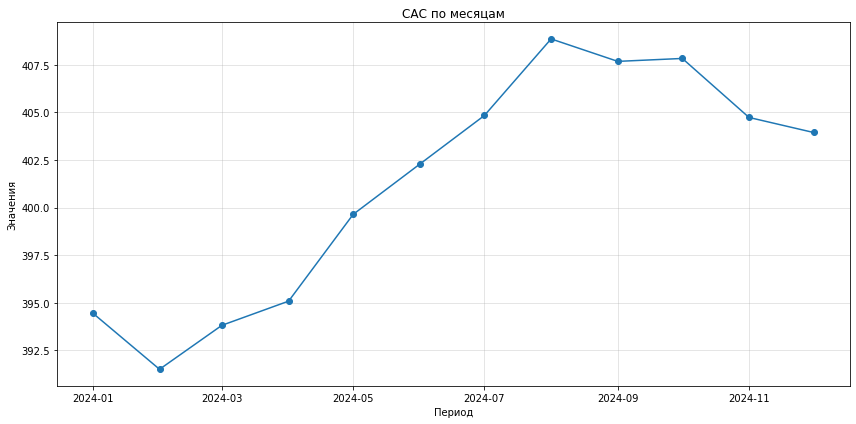

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(cac_monthly['cohort_month'], cac_monthly['cac'], marker='o')

# Оформляем график
plt.title('САС по месяцам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

Стоимость привлечения пользователя росла незначительно менялась на протяжении года. рост с февраля по август был с 391 до 408, снижение с августа по декабрь - с 408 до 403.

Рассчитаем значение LTV в течении 30 дней, то есть посчитаем, сколько выручки приносят пользователи по месячным когортам в течение 30 дней.

In [ ]:
# Исключаем из анализа заказы пользователей, по которым нет даты регистрации
orders_ltv = pa_marketplace_orders.dropna(subset=['registration_date']).copy()

# Рассчитываем количество дней между регистрацией и совершением заказа
orders_ltv['n_days'] = (orders_ltv['order_date'] - orders_ltv['registration_date']).dt.days

# Оставляем только те заказы, которые были совершены в первые 30 дней после регистрации
orders_30d = orders_ltv[orders_ltv['n_days'] <= 30]

# Группируем данные по месяцам и считаем суммарную выручку (5% комиссии)
cohort_revenue_30d = orders_30d.groupby('cohort_month')['revenue'].sum().reset_index()

# Приводим значения выручки к целочисленному типу
cohort_revenue_30d['revenue'] = cohort_revenue_30d['revenue'].astype(int)

# Объединяем с таблицей по затратам на привлечение
ltv_cac_roi_monthly = pd.merge(cac_monthly, cohort_revenue_30d, how = 'inner', on = 'cohort_month')

# Рассчитываем LTV (за 30 дней)
ltv_cac_roi_monthly['ltv'] = ltv_cac_roi_monthly['revenue'] / ltv_cac_roi_monthly['n_users']

# Рассчитываем ROI - показатель окупаемости инвестиций
ltv_cac_roi_monthly['roi'] = (ltv_cac_roi_monthly['ltv'] - ltv_cac_roi_monthly['cac']) / ltv_cac_roi_monthly['cac'] * 100

# Выводим итоговую таблицу
ltv_cac_roi_monthly.head()


,cohort_month,budget,n_users,cac,revenue,ltv,roi
0,2024-01-01,1177456,2985,394.457945,1079170,361.530988,-8.347393
1,2024-02-01,1061385,2711,391.510856,1091384,402.576171,2.826311
2,2024-03-01,1167680,2965,393.821373,1230783,415.103879,5.404101
3,2024-04-01,1147739,2905,395.091194,1313823,452.262651,14.470446
4,2024-05-01,1225322,3066,399.648493,1287760,420.013046,5.095616


Визуализируем динамику LTV (за 30 дней)  в сравнеии с CAC для разных когорт (месяцев).

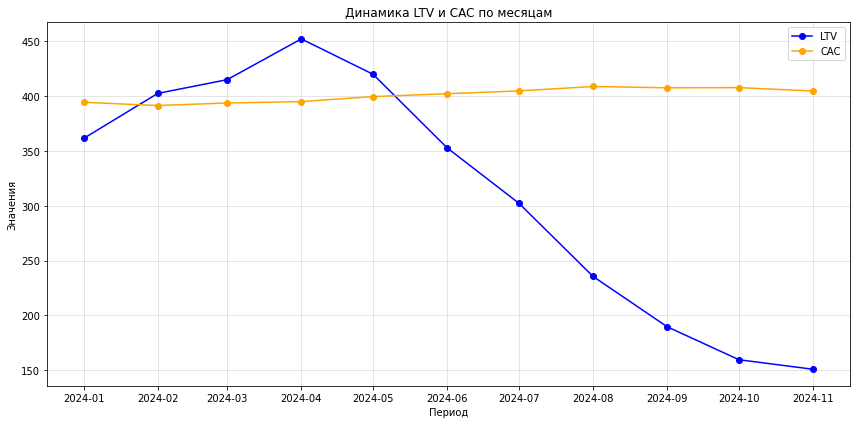

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(ltv_cac_roi_monthly['cohort_month'][:-1], ltv_cac_roi_monthly['ltv'][:-1], marker='o', color='blue', label = 'LTV')
plt.plot(ltv_cac_roi_monthly['cohort_month'][:-1], ltv_cac_roi_monthly['cac'][:-1], marker='o', color='orange', label = 'CAC')

# Оформляем график
plt.title('Динамика LTV и CAC по месяцам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

График сравнения CAC и LTV показал, что при стабильной стоимости привлечения доходность пользователей стремительно падает после мая 2024. На протяжении всего года стоимость привлечения одного пользователя удерживалась в пределах 390-410. В то же время LTV в течение 30 дней по когортам демонстрировал рост только до апреля (пик составил - 452), после чего началось падение. Начиная с июня, кривая LTV пересекла линию CAC и к ноябрю опустилась до критической отметки 150. Декабрьская когорта исключена, потому что данные по заказам собраны до 2024 года.

Во второй половине года привлекаемая аудитория перестала окупать вложенные в неё средства в первый месяц жизни.

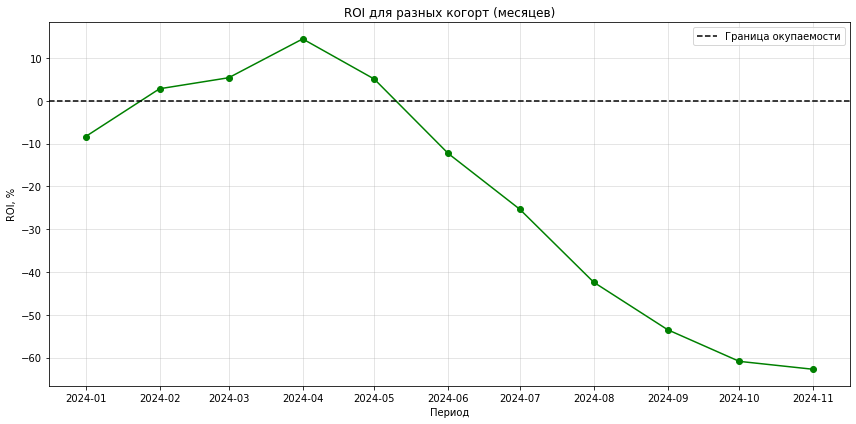

In [ ]:
# Строим график в matplotlib
plt.subplots(figsize=(12,6))
plt.plot(ltv_cac_roi_monthly['cohort_month'][:-1], ltv_cac_roi_monthly['roi'][:-1], marker='o', color='green')


# Добавляем горизонтальную линию — границу окупаемости
plt.axhline(y=0, color='black', linestyle='--', label='Граница окупаемости')


# Оформляем график
plt.title('ROI для разных когорт (месяцев)')
plt.xlabel('Период')
plt.ylabel('ROI, %')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

Кривая ROI практически полностью повторяет траекторию LTV из-за стабильности затрат на привлечение (CAC). Показатель находился в положительной зоне лишь с февраля по май, достигнув максимума в апреле (14.5%). Начиная с июня, окупаемость ушла в отрицательные значения и к ноябрю достигла -62.7%. Такая динамика указывает на то, что маркетплей продолжая активно инвестировать в привлечение пользователей, с июня больше не возвращает вложенные средства в течение первого месяца жизни пользователей в продукте.

Теперь перейдем к расчету ROI и Payback Period по когортам. Для определения срока окупаемости пересчитаем LTV и ROI накопительным итогом по месяцам жизни каждой месячной когорты.

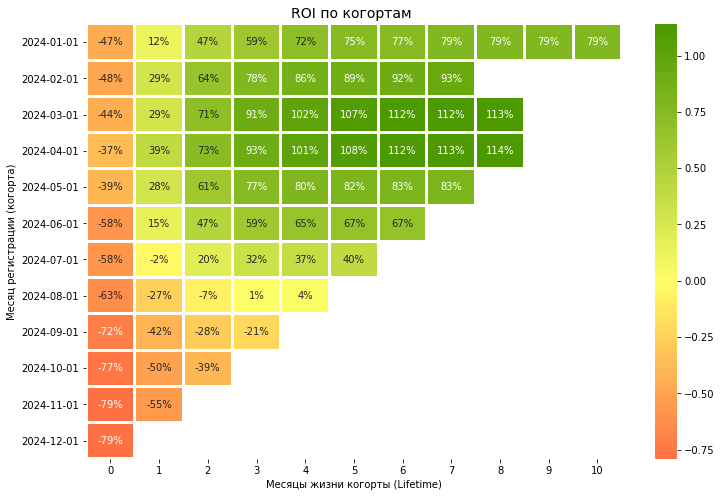

In [ ]:
# Рассчитываем выручку по каждой когорте и месяцу жизни
cohort_cum_revenue = orders_ltv.groupby(['cohort_month', 'n_month'])['revenue'].sum().reset_index()

# Считаем кумулятивную выручку для каждой когорты
cohort_cum_revenue['cum_revenue'] = cohort_cum_revenue.groupby('cohort_month')['revenue'].cumsum()

# Объединяем кумулятивную выручку с данными о размере когорт и CAC
cum_ltv_roi = pd.merge(cohort_cum_revenue, ltv_cac_roi_monthly[['cohort_month', 'n_users', 'cac']], on='cohort_month')

# Рассчитываем LTV и ROI для каждого месяца жизни
cum_ltv_roi['ltv'] = cum_ltv_roi['cum_revenue'] / cum_ltv_roi['n_users']
cum_ltv_roi['roi'] = (cum_ltv_roi['ltv'] - cum_ltv_roi['cac']) / cum_ltv_roi['cac']

# Формируем сводную таблицу для визуализации сроков окупаемости
cum_ltv_roi_pivot = cum_ltv_roi.pivot_table(
    index='cohort_month',
    columns='n_month',
    values='roi'
)

# Приводим индекс к формату даты для отображения на графике
cum_ltv_roi_pivot.index = cum_ltv_roi_pivot.index.strftime('%Y-%m-%d')

# Визуализируем динамику окупаемости
plt.figure(figsize=(12, 8))
cmap = mcolors.LinearSegmentedColormap.from_list('red_yellow_green', ['#FF3333', '#FFFF66', '#4C9900'], N=100)

sns.heatmap(cum_ltv_roi_pivot,
            annot=True,
            fmt='.0%',
            cmap=cmap,
            center=0,
            linewidths=2,
            annot_kws={"size": 10})

plt.title('ROI по когортам ', fontsize=14)
plt.xlabel('Месяцы жизни когорты (Lifetime)')
plt.ylabel('Месяц регистрации (когорта)')
plt.show()


Тепловая карта подтверждает ухудшение юнит-экономики во второй половине года. Для когорт начала года (январь-июнь) ROI становится положительным всего один месяц. Заметно, что темп возврата инвестиций рос по когортам: от январькой до апрельской (для апрельской когорты ROI был 39% по итогам первого месяца жизни, а для январьской - 12%). Но даже когорт первого полугодия заметно замедление темпов роста ROI с течением времени. Основной доход генерируется в первые 2–3 месяца, после чего кривая окупаемости выходит на плато. Например, мартовская когорта за второй месяц жизни прибавила 42 п.п. к ROI, за шестой 5 п.п, а за восьмой 1 п.п.

Дальше когорт второго полугодия ситуация меняется. Срок окупаемости июльской когорты увеличился до двух месяцев, а августовская когорта достигла окупаемости только на третий месяц. Судя по динамике ROI, у осенних когорты срок окупаемости отодвинут значительно дальше, поскольку темп прироста ROI оказался очень медленным (у сентябрьской когорты прирост ROI между вторым и третьи месяцем жизни в продукте - 7 п.п.). Для последующих когорт ROI еще ниже: ROI на первый месяц октябрьской когорты составил -50%, ноябрьской -55%.

Такая динамика свидетельствует о том, что привлечение пользователей во втором полугодии намного дольше окупается. Если весенние когорты приносили прибыль в течении на следующий месяц после месяца регистрации, то последующая аудитория не окупает себя даже на длинной дистанции.

Дополнительно построим тепловую карту Payback Period для визуализации момента окупаемости привлеченных пользователей по когортам.

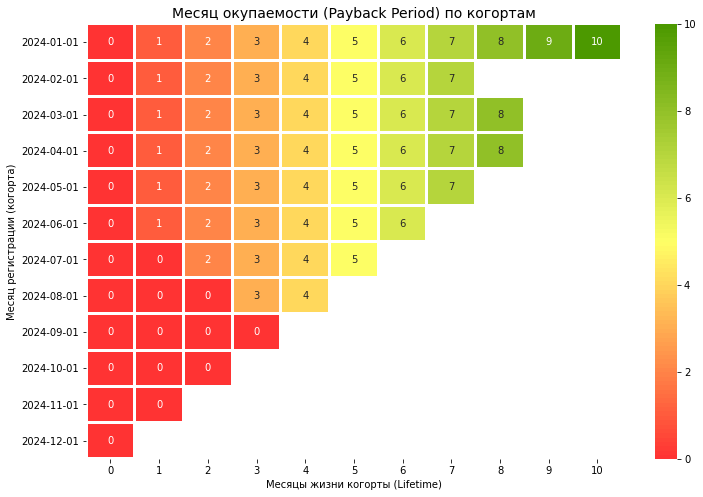

In [ ]:
# Определяем месяц окупаемости
cum_ltv_roi['payback_period'] = cum_ltv_roi.apply(
    lambda row: row['n_month'] if row['ltv'] >= row['cac'] else 0, axis=1)

# Строим сводную таблицу
payback_pivot = cum_ltv_roi.pivot_table(
    index='cohort_month',
    columns='n_month',
    values='payback_period'
)

# Форматируем даты в индексе для корректного отображения на графике
payback_pivot.index = payback_pivot.index.strftime('%Y-%m-%d')

# Визуализируем Payback Period: первая ненулевая цифра в строке означает месяц окупаемости когорты
plt.figure(figsize=(12, 8))
sns.heatmap(payback_pivot,
            annot=True,
            fmt='.0f',
            cmap=cmap,
            linewidths=2)

plt.title('Месяц окупаемости (Payback Period) по когортам', fontsize=14)
plt.xlabel('Месяцы жизни когорты (Lifetime)')
plt.ylabel('Месяц регистрации (когорта)')
plt.show()


## Выводы по этапам 2 и 3


<p style="font-size:20px"><strong>Аналитическая записка: состояние продукта и юнит-экономики (2024 год)</strong></p>

Несмотря на стабильность *среднего чека* (1200-1270 руб.), *выручка* к декабрю упала до уровня февраля. Проблема вызвана не отсутствием трафика, а привлечением нецелевой аудитории, которая не конвертируется в продажи и не окупается.

Связь метрик и причины падения: <br>
Спад активности и заказов: *количество заказов* сократился практически вдвое относительно пика (= май). Это произошло из-за целого ряда факторов: отток аудитории (*MAU*), ухудшению *воронки* (конверсия в оплату в конце года стала ниже январских значений), снижению *ретеншна* в активность и покупку у старой аудитории (кто пришел зимой-весной 2024) и притоком нецелевой аудитории (во второй половине года).

Кризис удержания:<br>
У продукта в целом низкая возвращаемость в покупку после 3-го месяца. Поэтому постоянно требуются новые пользователи. Однако при росте притока новых пользователей с июля в 1.5 раза, их удержание стало системно падать. Новые когорты перестают пользоваться продуктом значительно быстрее, чем весенние.

Проблемы с экономикой: <br>
Стоимость привлечения (*CAC*) стабильна (около 400 руб. на пользователя), но суммарный доход на пользователя (*LTV*) в течение месяца упал с 452 руб. (апрельская когорта) до 150 руб (ноябрьская). В результате *ROI* на следующий месяц после месяца регистрации упал до -55%, а срок окупаемости (*Payback Period*) вырос с 1 месяца до 6-7 (возможно и дольше).

На конец 2024 года зафиксированы существенные риски для окупаемости бизнеса.

## 4. Поиск инсайтов, точек роста и сегментация


На предыдущем этапе было выявлено снижение выручки и связанные с этим проблемные области в продукте:
- снижение количества заказов
- снижение активной аудитории
- приток нецелевой аудитории
- снижение ретеншна
- ухудшению воронки
- ухудшение метрик юнит-экономики

Сейчас погрузимся вглубь данных, чтобы точнее определить проблемы продукта, а также возможные точки роста.

<p style="font-size:20px"><strong>Анализ метрик в разрезе источника привлечения</strong></p>


Посчитаем число привлечённых пользователей для каждого источника в абсолютных и относительных значениях.

In [ ]:
# Рассчитаем общее число привлеченных пользователей по каждому каналу
channel_users = pa_marketplace_users.groupby('acq_channel')['user_id'].nunique().reset_index(name='n_users')
# Добавим столбец с долей пользователей источника от всех пользователей
channel_users['ratio'] = (channel_users['n_users'] / channel_users['n_users'].sum()).round(2)

# Выведем число привлечнных пользователей по источникам, отсортировав их по убыванию
display(channel_users.sort_values(by='n_users', ascending=False))

,acq_channel,n_users,ratio
5,TikTok,19228,0.44
2,Google Ads,9319,0.21
0,Affiliate,6069,0.14
4,Social Media,4179,0.09
3,SEO,3312,0.08
1,Email Marketing,2044,0.05


Распределение пользователей по каналам получилось неравномерное: больше всего пришли из TikTok (19228, 44%), в более чем в два раза меньше пользователей из Google Ads (9319, 21%), а из остальные пользователи из Affiliate (6069, 14%), Social Media (4179, 9% ), SEO (3312, 8%) и Email Marketing (2044, 5%).


Создадим пользовательскую функцию, с помощью которой будем считать и визуализировать метрики в разрезе сегмента.

In [ ]:


def plot_metric_by_segment(df, date_col, metric_col, segment_col, title):
    """
    Функция для расчета матрик и построения графиков по разным сегментам.
    Функция группирует данные по дате и сегменту, рассчитывает уникальных пользователей
    и строит линейный график для каждого сегмента.

    Параметры:
    df (pd.DataFrame): исходный датафрейм
    date_col (str): колонка с датой
    metric_col (str): колонка для расчета уникальных значений
    segment_col (str): колонка, по которой сегментируем
    title (str): заголовок графика
    """
    # Группируем данные по дате и выбранному сегменту
    data_grouped = df.groupby([date_col, segment_col])[metric_col].nunique().reset_index()
    segments = data_grouped[segment_col].unique()

    plt.subplots(figsize=(12, 6))

    # Строим линии для каждого сегмента
    for segment in segments:
        df_plot = data_grouped[data_grouped[segment_col] == segment]
        plt.plot(df_plot[date_col],  df_plot[metric_col], label=segment, color=colors.get(segment))

    # Оформление
    plt.title(title)
    plt.xlabel('Период')
    plt.ylabel('Значения')
    plt.legend()
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.show()



Визуализируем динамику набора новых пользователей по неделям в каждом источнике.

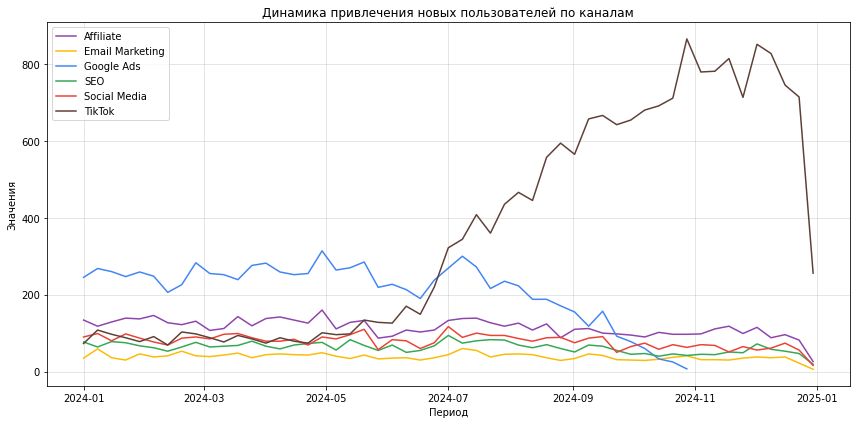

In [ ]:
# Создаем единый справочник цветов для всех источников проекта
colors = {
    'TikTok': '#5D4037',
    'Google Ads': '#4285F4',
    'SEO': '#34A853',
    'Social Media': '#EA4335',
    'Email Marketing': '#FBBC05',
    'Affiliate': '#8E44AD'
}

# Используем функцию plot_metric_by_segment
plot_metric_by_segment(pa_marketplace_users, 'cohort_week', 'user_id', 'acq_channel', 'Динамика привлечения новых пользователей по каналам')

На графике видно, что четыре канала (`Affiliate`, `Social Media`, `SEO`, `Email Marketing`) на протяжении года стабильны, еженедельно привлекая примерно одинаковое количество пользователей в диапазоне 50-170 человек. Существенные изменения связаны с двумя крупнейшими источниками трафика:
- `TikTok` с июля 2024 года стал основным источником: количество привлеченных пользователей ежемесячно росло, достигнув на пике около 850 человек в неделю
- `Google Ads`, напротив, показал нисходящий тренд: в первой половине года он лидировал по объемам привлечения (около 250 человек в неделю), после июля показатели начали падать, а в ноябре канал перестал привлекать трафик.

**DAU и MAU по каналам привлечения** <br>
Сравним теперь метрикаи активности аудитории из разных каналов.

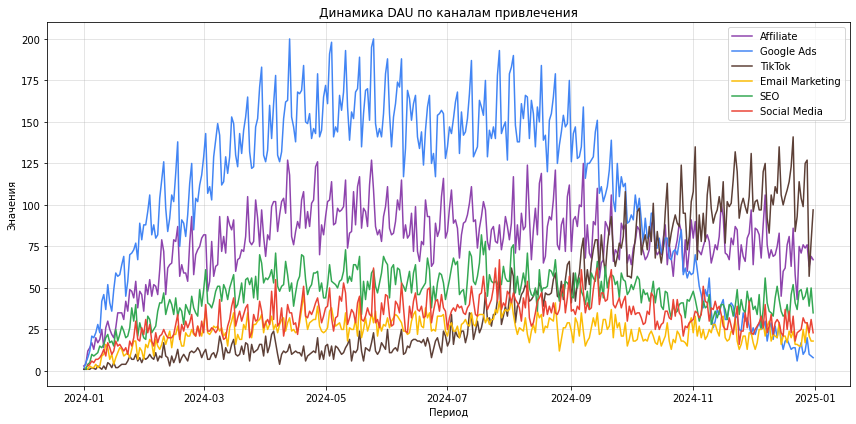

In [ ]:
# Возмем таблицу с активностью всех пользователей (включая оплату товара)
# Исключаем из анализа пользователей, по которым нет информации о канале привлечения
events_channel = all_active_users.dropna(subset=['acq_channel']).copy()

# Рассчитываем и визуализируем DAU с помощью функции
plot_metric_by_segment(events_channel, 'event_date', 'user_id', 'acq_channel', 'Динамика DAU по каналам привлечения')

График показывает изменение динамики привлечения пользователей по каналам.
- Ежедневная аудитория из `Google Ads` была самой активной пока канал работал - с января по май виден значительный рост до 175-200 посетителей в день. После мая была небольшая просадка летом, а с сентября метрика постепенно снижается до десяти посетителей в день.
- `TikTok` показывает аномально низкую вовлеченность. Несмотря на то, что канал к концу года привлекает примерно в 5 раз больше новых пользователей, чем остальные источники, его пиковый DAU составил всего 130-135 человек.
- Пользователи `Affiliate` стабильно активные: DAU растет с января по май, затем наблюдается небольшой спад к концу года. При среднем объеме привлечения около 100 человек в неделю, канал удерживает DAU на уровне 75–125 пользователей.
- `Social Media`, `SEO`, `Email Marketing` демонстрируют схожую динамику в пределах 10–75 активных пользователей в день. Показатели `SEO` немного выше, чем у `Email Marketing` и `Social Media`.

График подтверждает критическую разницу в качестве трафика из разных источников.

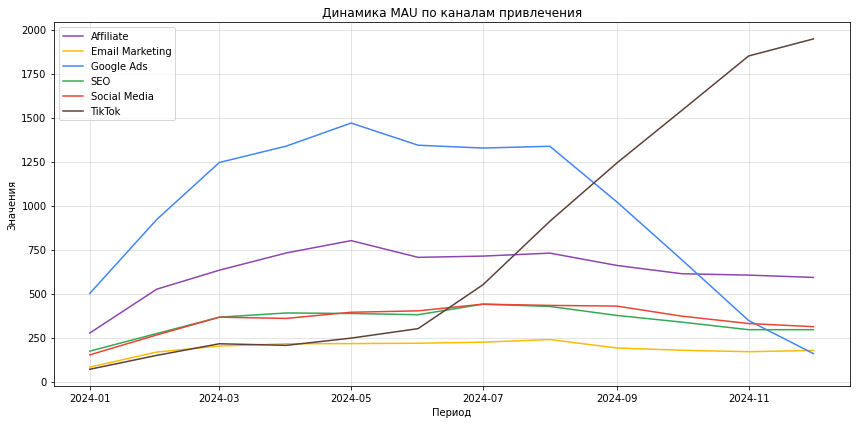

In [ ]:
# Рассчитываем и визуализируем MAU
plot_metric_by_segment(events_channel, 'event_month', 'user_id', 'acq_channel', 'Динамика MAU по каналам привлечения')

График MAU дополняет общую картину активности.

Месячная аудитория `TikTok` оказывается низкой в сравнении с дневной активностью, что указывает на то, что скорее всего новые пользователи, однажды посетив продукт, не возвращаются в него. MAU растет с июня по декабрь и достигает 2000 пользователей в месяц.
`Google Ads` показывает высокую вовлечность и по MAU - на пике (май) около 1500 посетителей в месяц.
Пользователи `Affiliate` (в среднем около 700) также стабильны и повтораяют динамику по DAU.
Месячная аудитория `Social Media` (в среднем около 400) оказывается во второй половине года немного выше, чем у `SEO` в то время как на графике DAU, наоборот, `SEO` выше. Это говорит о том, что аудитория SEO заходит в продукт чаще. Учитывая, что `SEO` привлекает меньше новых пользователей, это говорит о том, что аудитория этого канала более вовлеченная.
`Email Marketing` показывает стабильно низкие значения в районе 100-250 пользователей в месяц.

Дополнительно посмотрим на динамику метрики Stickiness, которая позволит сравнить ежедневное использовании продукта пользователями, которые пришли из разных источников.

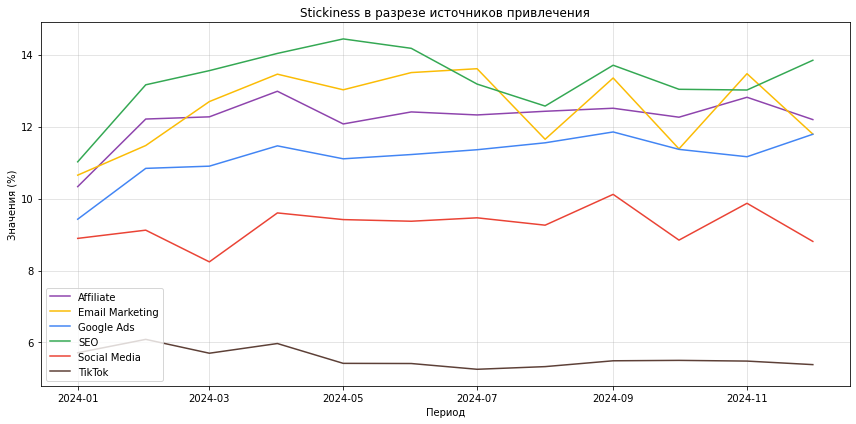

In [ ]:
# Рассчитываем DAU по каналам
dau_channel = events_channel.groupby(['event_date', 'acq_channel'])['user_id'].nunique().reset_index()

# Приводим даты к началу месяца для последующей группировки
dau_channel['event_month'] = pd.to_datetime(dau_channel['event_date']).dt.to_period('M').dt.to_timestamp()

# Считаем средний DAU для каждого канала по месяцам
dau_channel_avg = dau_channel.groupby(['event_month', 'acq_channel'])['user_id'].mean().reset_index(name = 'dau_avg')

# Рассчитываем MAU по каналам привлечения
mau_channel = events_channel.groupby(['event_month', 'acq_channel'])['user_id'].nunique().reset_index(name = 'mau')

# Объединяем в одну таблицу
stickiness_channel = pd.merge(dau_channel_avg, mau_channel, on=['event_month', 'acq_channel'], how='inner')

# Рассчитываем Stickiness: отношение дневной аудитории к месячной
stickiness_channel['stickiness'] = (stickiness_channel['dau_avg'] / stickiness_channel['mau']) * 100

# Сохраняем список уникальных каналов
channels = stickiness_channel['acq_channel'].unique()

# Визуализируем динамику Stickiness
plt.subplots(figsize=(12, 6))

for channel in channels:
    df_plot = stickiness_channel[stickiness_channel['acq_channel'] == channel]
    plt.plot(df_plot['event_month'], df_plot['stickiness'], label=channel, color=colors.get(channel))

# Оформляем
plt.title('Stickiness в разрезе источников привлечения')
plt.xlabel('Период')
plt.ylabel('Значения (%)')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


Анализ метрики Stickiness подтверждает гипотезу о низком качестве аудитории, привлекаемой через `TikTok`, по сравнению с остальными каналами.
На протяжении всего года показатель `TikTok` оставался стабильно низким и практически не менялся, колеблясь в диапазоне 5-6%. Это означает, что пользователи из этого источника почти не возвращаются в приложение.

В то же время остальные каналы показывают более высокую «липкость»:
- `SEO` является лидером по вовлеченности с показателями 13–14%.
- `Affiliate`, `Email Marketing` и `Google Ads` показывают стабильно хорошие результаты в районе 11–13%.
- `Social Media` удерживает среднюю позицию на уровне 9%.

Разрыв в Stickiness между `TikTok` и другими источниками более чем в два раза. Аудитория канала является нецелевой.

Далее посмотрим на динамику заказов по каналам.

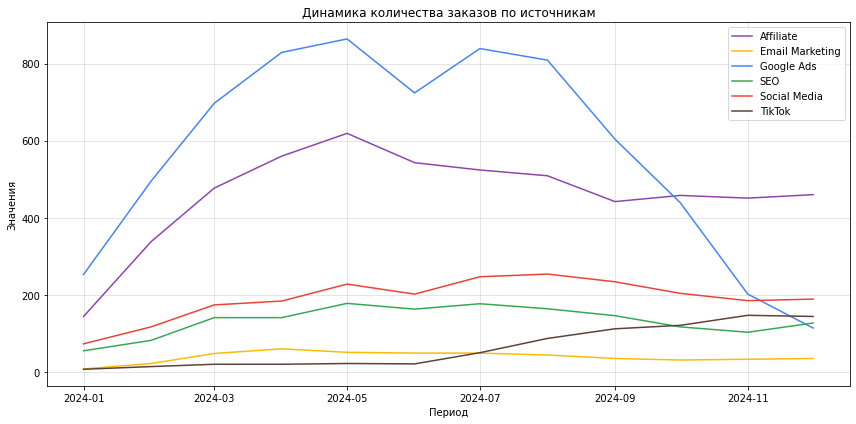

In [ ]:
# Формируем список уникальных заказов (объединяем товары, купленные одномоментно, в один заказ)
unique_orders_channel = pa_marketplace_orders.groupby(['user_id', 'order_date', 'order_month', 'acq_channel']).size().reset_index()

# Группируем данные по месяцам
orders_per_month_channel = unique_orders_channel.groupby(['order_month', 'acq_channel']).size().reset_index(name='order_count')

# Строим график в matplotlib
plt.subplots(figsize=(12,6))
for channel in channels:
    df_plot = orders_per_month_channel[orders_per_month_channel['acq_channel'] == channel]
    plt.plot(df_plot['order_month'], df_plot['order_count'], label=channel, color=colors.get(channel))

# Оформляем график
plt.title('Динамика количества заказов по источникам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

Для анализа качества трафика дополнительно рассчитаем конверсию в покупку из регистрации c окном атрибуции 30 дней.

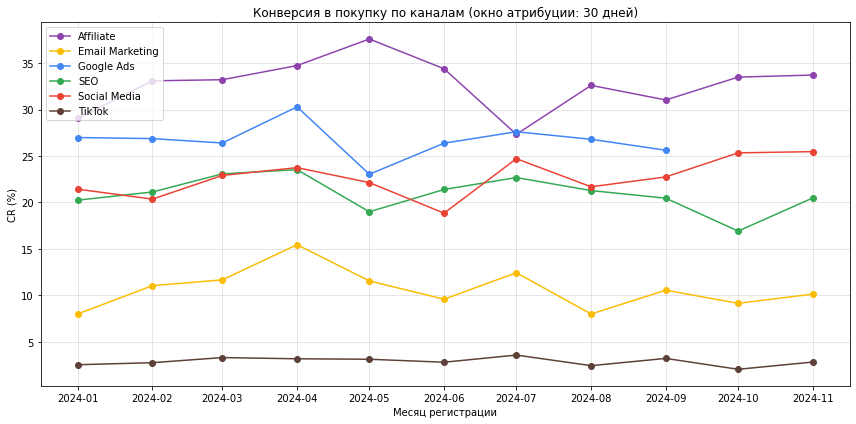

In [ ]:
# Определяем окно атрибуции покупок - 30 дней с момента регистрации (с 0 по 29)
attribution_window = 29

# Фильтруем заказы в окне 30 дней и считаем уникальных покупателей для каждой когорты
paying_users_30d = (
    orders_ltv[orders_ltv['n_days'].between(0, attribution_window)]
    .groupby(['cohort_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='retained_payers_30d')
)

# Рассчитываем размеры исходных когорт из таблицы pa_marketplace_users
cohort_sizes_channel = pa_marketplace_users.groupby(['cohort_month', 'acq_channel'])['user_id'].nunique().reset_index(name='total_users')

# Объединяем данные и считаем конверсию в покупку
conversion_table = pd.merge(paying_users_30d, cohort_sizes_channel, on=['cohort_month', 'acq_channel'], how='inner')
conversion_table['cr'] = (conversion_table['retained_payers_30d'] / conversion_table['total_users'] * 100).round(2)

# Визуализируем динамику
plt.subplots(figsize=(12, 6))

for channel in channels:
    df_plot = conversion_table[conversion_table['acq_channel'] == channel]
    plt.plot(df_plot['cohort_month'][:-1], df_plot['cr'][:-1],
             label=channel, color=colors.get(channel), marker='o')

plt.title('Конверсия в покупку по каналам (окно атрибуции: 30 дней)')
plt.xlabel('Месяц регистрации')
plt.ylabel('CR (%)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.grid(alpha=0.4)
plt.show()


График конверсии в покупку за первые 30 дней жизни когорты подтверждает низкое качество трафика из `TikTok`: конверсия 2.5-3.5%, что практически в 10 раз меньше показателей источника-лидера по конверсии (`Affiliate`). Для сравнения `Affiliate` и `Google Ads` демонстрируют стабильно высокие показатели в диапазоне 25-37%. Даже каналы с небольшим трафиком, такие как `Email Marketing`, показывают эффективность в 3-4 раза выше, чем `TikTok`. Трафик из `TikTok` является нецелевым и не конвертируется в продажи.

Далее рассмотрим юнит-экономику по каналам. Рассчитаем и визуализируем CAC.

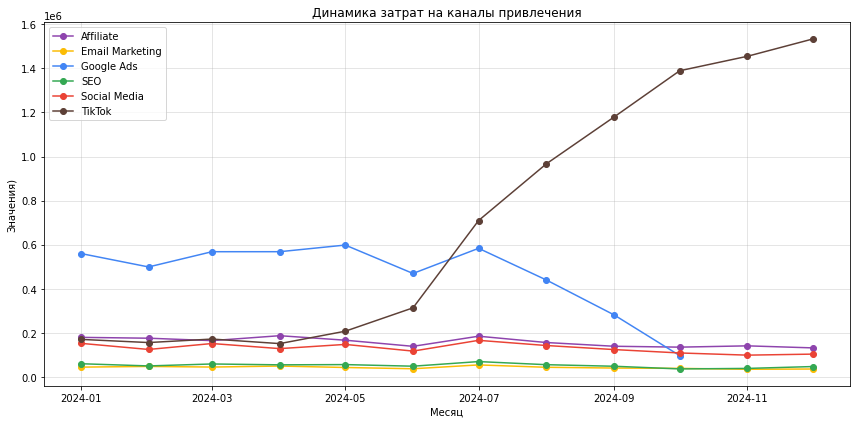

In [ ]:
# Рассчитаем суммарный бюджет на привлечения по каналам в разрезе месяца
# (убираем из данных канал 'Direct', потому что он не отслеживается в остальных таблицах)
budget_monthly_channel = pa_marketplace_campaign_costs[pa_marketplace_campaign_costs['acq_channel'] != 'Direct'].groupby(['spend_month', 'acq_channel'])['budget'].sum().reset_index()

# Переименуем название столбца с указанием месяца
budget_monthly_channel.rename(columns={'spend_month': 'cohort_month'}, inplace=True)


# Объединяем полученную таблицу с таблицей, где собрано количество пользователей, привлеченных по месяцам (cohort_sizes)
cac_monthly_channel = pd.merge(budget_monthly_channel, cohort_sizes_channel, how = 'inner', on = ['cohort_month', 'acq_channel'])

# Переименуем название столбца с количеством пользователей
cac_monthly_channel.rename(columns={'user_id': 'n_users'}, inplace=True)

# Рассчитаем САС
cac_monthly_channel['cac'] = cac_monthly_channel['budget'] / cac_monthly_channel['total_users']

# Приводим значения бюджета к целочисленному типу
cac_monthly_channel['budget'] = cac_monthly_channel['budget'].astype(int)


# Визуализируем динамику затрат на привлечение
plt.subplots(figsize=(12, 6))

for channel in channels:
    df_plot = cac_monthly_channel[cac_monthly_channel['acq_channel'] == channel]
    plt.plot(df_plot['cohort_month'], df_plot['budget'],
             label=channel, color=colors.get(channel), marker='o')

plt.title('Динамика затрат на каналы привлечения')
plt.xlabel('Месяц')
plt.ylabel('Значения)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.grid(alpha=0.4)
plt.show()

С июня 2024 года бюджет на `TikTok` вырос  с 200 тыс. до более чем 1.5 млн в месяц к декабрю. Это самый крупный источник по расходам. У `Google Ads` в начале года  бюджет около 600 тыс., но с с июля бюджет стали сокращаться. К октябрю затраты на канал прекратились. Затраты на `Affiliate`, `SEO`, `Social Media` и `Email Marketing` оставались на минимальном уровне (в пределах 50–200 тыс.) без попыток масштабирования.

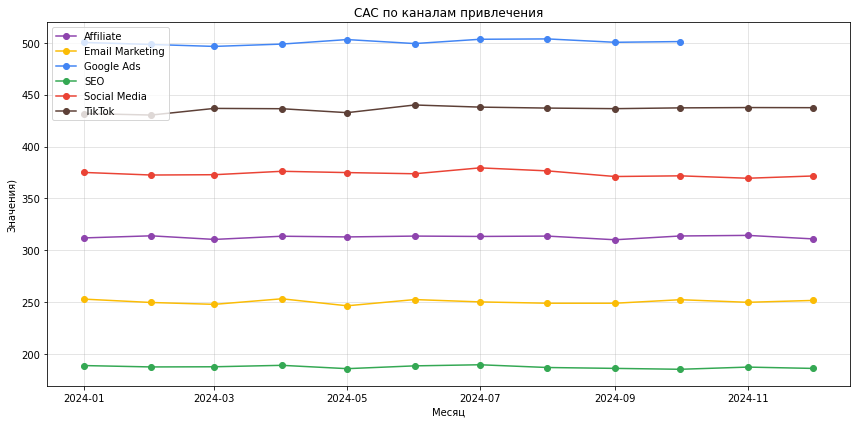

In [ ]:
# Визуализируем динамику CAC
plt.subplots(figsize=(12, 6))

for channel in channels:
    df_plot = cac_monthly_channel[cac_monthly_channel['acq_channel'] == channel]
    plt.plot(df_plot['cohort_month'], df_plot['cac'],
             label=channel, color=colors.get(channel), marker='o')

plt.title('CAC по каналам привлечения')
plt.xlabel('Месяц')
plt.ylabel('Значения)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.grid(alpha=0.4)
plt.show()

График динамики CAC по каналам привлечения демонстрирует стабильность протяжении всего года. Самым дорогим каналом является `Google Ads` со стоимостью около 500 руб. за пользователя (канал перестал работать в октябре 2024), за ним следует `TikTok` с показателем в районе 440 руб. Наиболее бюджетные источники:  `Email Marketing` (250 руб.) и `SEO` (180–190 руб.).

Далее рассчитаем и визуализаруем ROI по месяцам жизни разных когорт в разрезе канала.

In [ ]:
# Рассчитываем выручку по каждой когорте, месяцу жизни и каналу
cum_revenue_channel = orders_ltv.groupby(['cohort_month', 'n_month', 'acq_channel'])['revenue'].sum().reset_index()

# Считаем кумулятивную выручку для каждой когорты и по каналу
cum_revenue_channel['cum_revenue'] = cum_revenue_channel.groupby(['cohort_month', 'acq_channel'])['revenue'].cumsum()

# Объединяем кумулятивную выручку с данными о размере когорт и CAC
roi_channel = pd.merge(
    cum_revenue_channel,
    cac_monthly_channel[['cohort_month', 'acq_channel', 'total_users', 'cac']],
    on=['cohort_month', 'acq_channel'], # Важно: джойним и по месяцу, и по каналу
    how='inner'
)

# Рассчитываем LTV и ROI для каждого месяца жизни по каналам
roi_channel['ltv'] = roi_channel['cum_revenue'] / roi_channel['total_users']
roi_channel['roi'] = (roi_channel['ltv'] - roi_channel['cac']) / roi_channel['cac']

# Выводим первые строки таблицы
roi_channel.sort_values(by=['cohort_month', 'acq_channel', 'n_month']).head(8)

,cohort_month,n_month,acq_channel,revenue,cum_revenue,total_users,cac,ltv,roi
0,2024-01-01,0,Affiliate,151314.187500,151314.1875,575,311.901543,263.155109,-0.156288
1,2024-01-01,1,Affiliate,221207.171875,372521.3750,575,311.901543,647.863261,1.077140
2,2024-01-01,2,Affiliate,108931.281250,481452.6250,575,311.901543,837.308913,1.684530
3,2024-01-01,3,Affiliate,38450.718750,519903.3750,575,311.901543,904.179783,1.898927
4,2024-01-01,4,Affiliate,25742.066406,545645.4375,575,311.901543,948.948587,2.042462
5,2024-01-01,5,Affiliate,7533.915039,553179.3125,575,311.901543,962.050978,2.084470
6,2024-01-01,6,Affiliate,7551.182617,560730.5000,575,311.901543,975.183478,2.126575
7,2024-01-01,7,Affiliate,1847.285034,562577.8125,575,311.901543,978.396196,2.136875


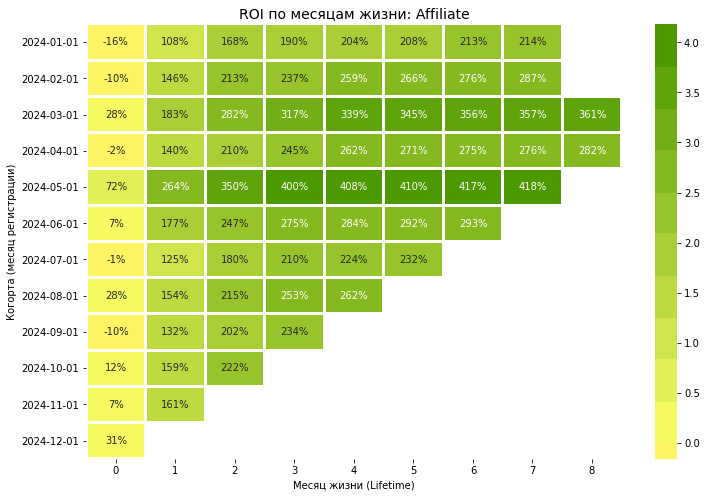

----------------------------------------------------------------------------------------------------


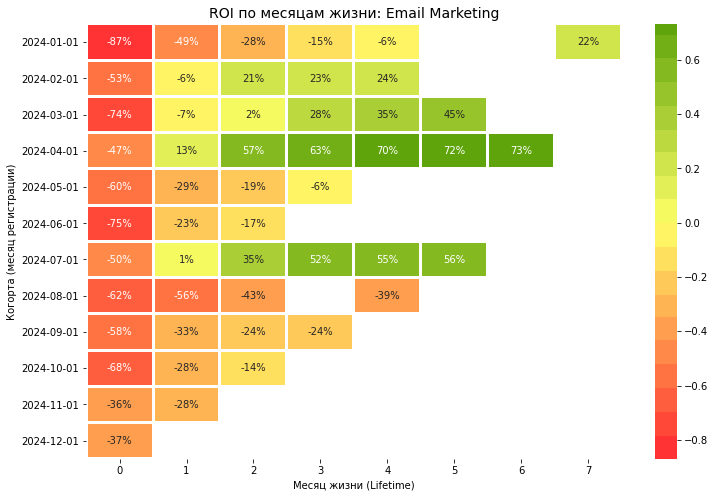

----------------------------------------------------------------------------------------------------


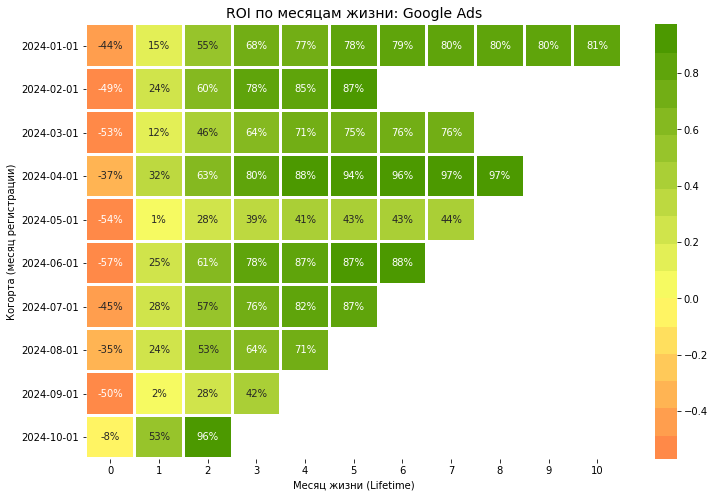

----------------------------------------------------------------------------------------------------


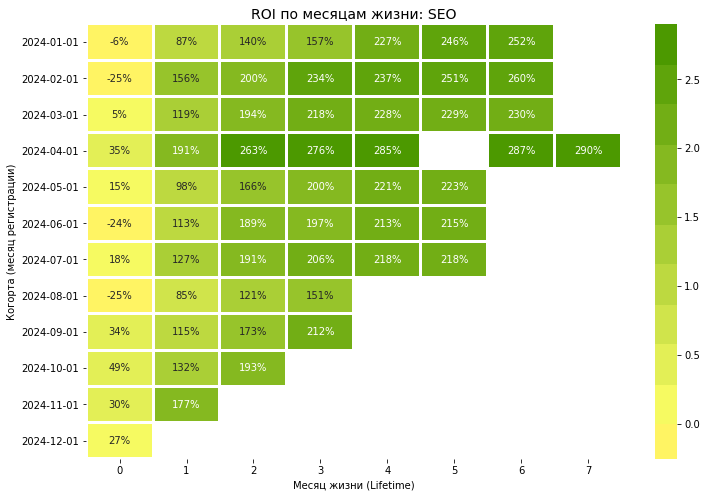

----------------------------------------------------------------------------------------------------


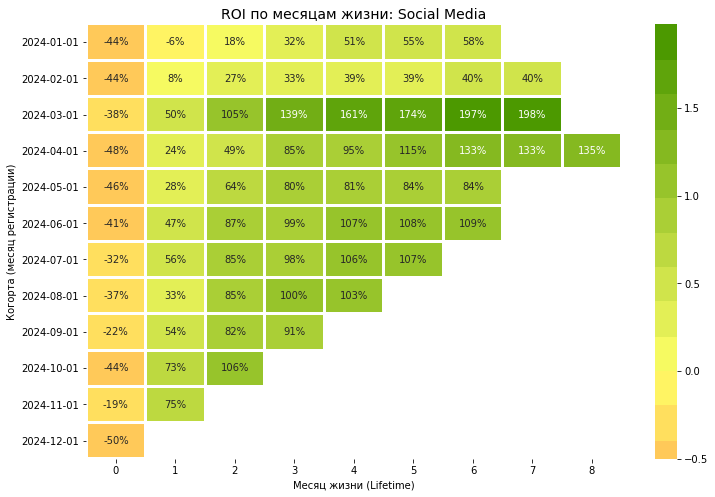

----------------------------------------------------------------------------------------------------


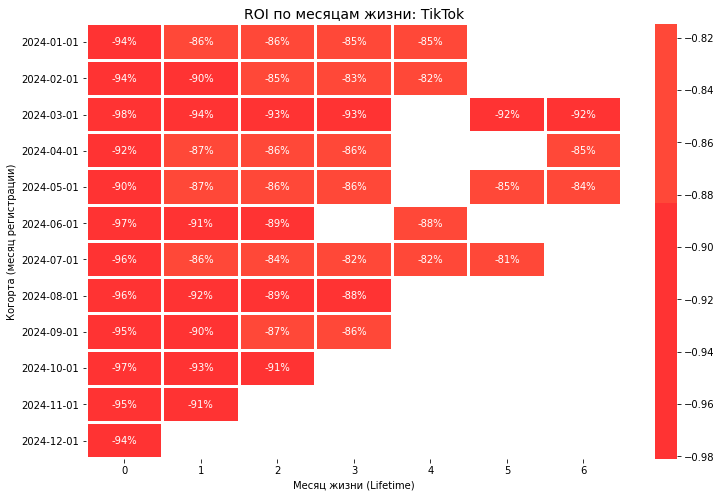

----------------------------------------------------------------------------------------------------


In [ ]:
# Настраиваем палитру
cmap = mcolors.LinearSegmentedColormap.from_list('roi_cmap', ['#FF3333', '#FFFF66', '#4C9900'], N=20)

# Создаем цикл по каналам
for channel in channels:
    data_plot = roi_channel[roi_channel['acq_channel'] == channel].pivot_table(
        index='cohort_month',
        columns='n_month',
        values='roi'
    )

    # Форматируем даты в индексе
    data_plot.index = data_plot.index.strftime('%Y-%m-%d')

    # Оформляем тепловую карту
    plt.figure(figsize=(12, 8))
    sns.heatmap(data_plot,
                annot=True,
                fmt='.0%',
                cmap=cmap,
                center=0,
                linewidths=2,
                annot_kws={"size": 10})

    plt.title(f'ROI по месяцам жизни: {channel}', fontsize=14)
    plt.xlabel('Месяц жизни (Lifetime)')
    plt.ylabel('Когорта (месяц регистрации)')
    plt.show()

    print("-" * 100)


**`Affiliate`** канал с быстрой окупаемостью в продукте. Почти все когорты окупаются уже на 1-ый месяц, показывая доходность выше 100%. В отличие от других каналов, здесь пользователи продолжают платить на длинной дистанции - ROI доcтигает 300-400% к полугоду жизни.

**`Email Marketing`** - канал со средней эффективностью и нестабильными сроками окупаемости. Rанал почти никогда не окупается в 1-ый  месяц. Срок окупаемости затрат на привлечение сильно варьируется - в основном 4-5 месяца. ROI у осенних когорт август-ноябрь накапливается медленнее (например, у августской когорты на 4-ый месяц ROI - 39%), что указывает на общее снижение качества аудитории этого канала.

**`Google Ads`** демонстрирует уверенную окупаемость, но имеет более длинный цикл возврата инвестиций по сравнению с `Affiliate`. Период окупаемости для канала составляет 1 месяц. В месяц регистрации (месяц жизни: 0) все когорты убыточны (ROI от -35% до -57%). Канал показывает стабильное накопление прибыли. К 5-6 месяцу жизни лучшие когорты (январь, апрель, июнь) достигают 80-97% ROI.

**`SEO`** - эффективных каналов с точки зрения окупаемости. Почти всегда окупается уже в месяц регистрации (месяц жизни: 0). Канал показывает прирост ROI на дистанции: к 6–7 месяцу жизни показатели достигают 250–290%. Это говорит о привлечении лояльной и целевой аудитории.

**`Social Media`** - демонстрирует хорошую окупаемость и стабильный рост доходности когорт. Канал выходит на окупаемость на 1-ый месяц жизни после месяца регистрации. К 5 месяцу показатели ROI большинства когорт превышают 100%. Последние когорты (сентябрь-ноябрь) идут немного лучше весенних.

**`TikTok`** - убыточный канал и основной источник нецелевого трафика. Все когорты остаются стабильно убыточными. Как было показано ранее, у пользователи из TikTok очень низкая конверяи в покупку из регистрации, из-за чего окупаемость не наступает со временем.

**Промежуточный вывод: анализ эффективности каналов привлечения** <br>
Сегментация подтвердила, что падение выручки во втором полугодии напрямую связано со сменой структуры трафика.

Основные результаты по каналам:
- `TikTok`: с июля канал стал основным источником новых пользователей (до 850 чел./неделю), однако это не привело к росту целевых показателей. У канала самый низкий Stickiness (около 5%) и минимальная конверсия из регистарции в покупку (около 2-3%). Ни одна когорта за 2024 год не вышла в окупаемость. При текущей стоимости привлечения трафик из этого источника не окупается и не формирует аудиторию лояльных пользователей.
- `Google Ads`: в первой половине года канал был важным истоничком выручки и активной аудитории (DAU/MAU). Источник показывал стабильную окупаемость на 1-ый месяц жизни. Сокращение и отключение источника в ноябре стало одной из причин снижения количества заказов и, соответственно, снижения выручки в конце года.
- `Affiliate` и `SEO`: каналы с быстрой окупаемостью. `SEO` привлекает наиболее вовлеченную аудиторию с самой высокой метрикой Stickiness. При этом объемы привлекаемой аудитории данных каналов ограничены и не могут компенсировать провал с `TikTok`.
- `Social Media` и `Email Marketing`: демонстрируют стабильную работу. `Social Media` во втором полугодии сохранил качественные показатели вовлеченности и к декабрю вышел на третье место по объему заказов, обогнав `TikTok`.


Масштабирование `TikTok` во втором полугодии привело к притоку большего объема нецелевого трафика.


**Точка роста**
- Остановить масштабирование `TikTok` и значительно сократить бюджет на этот канал
- Найти способы увеличения охватов в `Affiliate` и `SEO`, даже если это приведет к небольшому росту CAC. Это самые стабильные каналы с окупаемостью (ROI первого месяца > 100%)
- Сохранить текущий объем расходов на `Social Media` и протестировать небольшое увеличение бюджета. Канал показал качественный рост во втором полугодии и высокую конверсию в покупку, обойдя по количеству заказов TikTok при значительно меньших затратах.


<p style="font-size:20px"><strong>Анализ метрик в разрезе устройства и операционной системы</strong></p>

Посчитаем количество пользователей по устройствам.
Затем посмотрим на данные в разрезе разных типов устройств, прежде всего, на воронку для разных устройств.

In [ ]:
# Рассчитаем общее число привлеченных пользователей по устройствам
device_users = pa_marketplace_events.groupby('device')['user_id'].nunique().reset_index(name='n_users')
# Добавим столбец с долей пользователей устройства от всех пользователей
device_users['ratio'] = (device_users['n_users'] / device_users['n_users'].sum()).round(2)

# Выведем число привлечнных пользователей по источникам, отсортировав их по убыванию
display(device_users.sort_values(by='n_users', ascending=False))

,device,n_users,ratio
0,desktop,7447,0.34
1,mobile,7431,0.34
2,tablet,7260,0.33


Соотношение пользователей по устройствам равномерно.

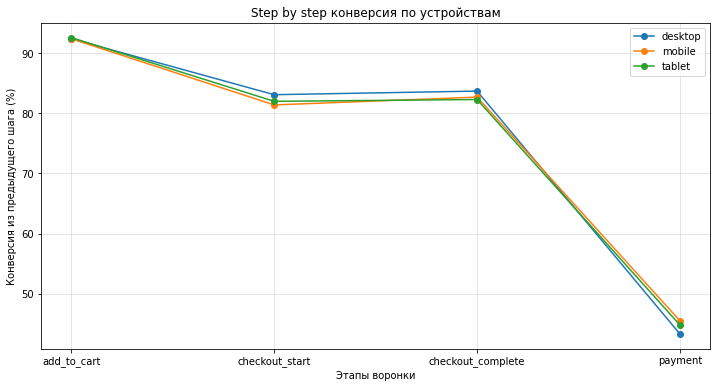

In [ ]:
# Задаем последовательность шагов воронки
funnel_steps_device = ['page_view',
                       'product_view',
                       'add_to_cart',
                       'checkout_start',
                       'checkout_complete']

# Формируем сводную таблицу по устройствам и этапам воронки
device_funnel = pa_marketplace_events[pa_marketplace_events['event_type'].isin(funnel_steps_device)].pivot_table(
    index='device',
    columns='event_type',
    values='user_id',
    aggfunc='nunique'
)[funnel_steps]

# Получаем уникальные ID пользователей, которые совершили оплату
paid_user_ids = pa_marketplace_orders['user_id'].unique()

# Считаем количество платящих пользователей в разрезе устройств (из этапа завершения оформления)
pay_by_device = pa_marketplace_events[
    (pa_marketplace_events['event_type'] == 'checkout_complete') &
    (pa_marketplace_events['user_id'].isin(paid_user_ids))
].groupby('device')['user_id'].nunique()

# Добавляем финальный шаг оплаты к основной воронке по устройствам
device_full_funnel = device_funnel.join(pd.DataFrame({'payment': pay_by_device}))

# Рассчитываем пошаговую конверсию из этапа в этап в процентах
device_step_cr = (device_full_funnel / device_full_funnel.shift(1, axis=1) * 100).round(1)

# Визуализируем пошаговую конверсию для каждого типа устройства
plt.subplots(figsize=(12, 6))

for device in device_step_cr.index:
    plt.plot(device_step_cr.columns[1:], device_step_cr.loc[device].iloc[1:],
             marker='o', label=device)

# Оформляем график
plt.title('Step by step конверсия по устройствам')
plt.ylabel('Конверсия из предыдущего шага (%)')
plt.xlabel('Этапы воронки')
plt.legend()
plt.grid(alpha=0.4)
plt.show()



График пошаговой конверсии по устройствам показывает, что узкие места воронки не зависят от типа типа устройства (`desktop`, `mobile` или `tablet`): поведение пользователей на всех платформах практически идентично.

Посмотрим на данные в разрезе операционных систем.

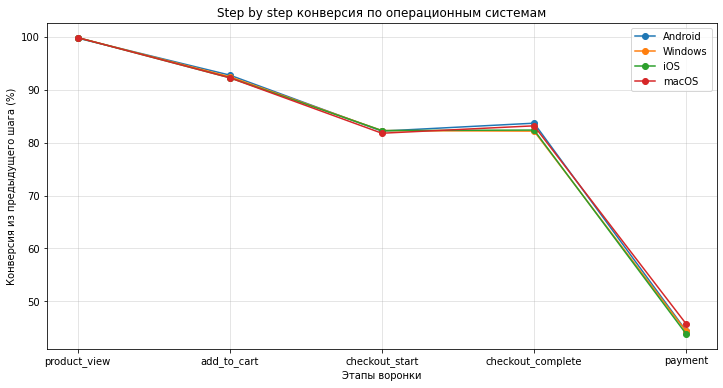

In [ ]:
# Задаем последовательность шагов воронки
funnel_steps_os = ['page_view',
                   'product_view',
                   'add_to_cart',
                   'checkout_start',
                   'checkout_complete']

# Формируем сводную таблицу по операционным системам и этапам воронки
os_funnel = pa_marketplace_events[pa_marketplace_events['event_type'].isin(funnel_steps_os)].pivot_table(
    index='os',
    columns='event_type',
    values='user_id',
    aggfunc='nunique'
)[funnel_steps_os]


# Считаем количество платящих пользователей в разрезе операционных систем (ОС) (через завершение оформления)
pay_by_os = pa_marketplace_events[
    (pa_marketplace_events['event_type'] == 'checkout_complete') &
    (pa_marketplace_events['user_id'].isin(paid_user_ids))
].groupby('os')['user_id'].nunique()

# Добавляем финальный шаг оплаты к основной воронке по ОС
os_full_funnel = os_funnel.join(pd.DataFrame({'payment': pay_by_os}))

# Рассчитываем пошаговую конверсию из этапа в этап в процентах
os_step_cr = (os_full_funnel / os_full_funnel.shift(1, axis=1) * 100).round(1)

# Визуализируем пошаговую конверсию для каждой операционной системы
plt.subplots(figsize=(12, 6))

for os_name in os_step_cr.index:
    plt.plot(os_step_cr.columns[1:], os_step_cr.loc[os_name].iloc[1:],
             marker='o', label=os_name)

# Оформляем график
plt.title('Step by step конверсия по операционным системам')
plt.ylabel('Конверсия из предыдущего шага (%)')
plt.xlabel('Этапы воронки')
plt.legend()
plt.grid(alpha=0.4)
plt.show()



График практически идентичен предыдущему и также не выявил различий в конверсии для операционных систем.

**Промежуточный вывод: анализ эффективности воронки**

Резюмируя узкие места в пользовательском пути можно вернуться к конверсии, рассчитанной на предыдущем этапе проекта.
Узких мест воронки два - переход из регистрации в активность (просмотр станиц) и из завершения оформления заказа к оплате.

Только 50% зарегистрированных пользователей начинают реально использовать приложение. Столь резкий отсев на старте указывает на системную проблему. Даже с учетом нецелевого трафика из `TikTok`, такая цифра аномальна. Вероятно, существует общая техническая ошибка после завершения регистрации или сложный интерфейс онбординга (или его отсуствие), который не дает пользователю быстро перейти к просмотру страниц и/или изучению товаров.

При переходе из завершения оформления к оплате заказа также происходит значительное падение: оплачивают только 44.5%. Такой обвал, одинаковый для всех типов устройств, говорит о том, что пользователи сталкиваются с барьером именно в момент платежа. Можно предположить, что клиентов могут не устраивать доступные способы оплаты или условия заказа (например, стоимость и сроки доставки), которые становятся окончательно понятны только на этом этапе.


**Точки роста**: <br>
Основной потенциал роста выручки в этом случае находится в устранении барьеров именно на этих двух этапах: активации новичков и завершении платежей.

![image.png](attachment:image.png)


<p style="font-size:20px"><strong>Анализ метрик в разрезе региона</strong></p>

Сначала проверим, как пользователи распределены по городам.

In [ ]:
# Рассчитаем общее число привлеченных пользователей по каждому региону
region_users = pa_marketplace_users.groupby('region')['user_id'].nunique().reset_index(name='n_users')
# Добавим столбец с долей пользователей региона от всех пользователей
region_users['ratio'] = (region_users['n_users'] / region_users['n_users'].sum()).round(2)

# Выведем число привлечнных пользователей по регионам, отсортировав их по убыванию
display(region_users.sort_values(by='n_users', ascending=False))

,region,n_users,ratio
0,Другие регионы,14516,0.33
3,Москва,10959,0.25
8,Санкт-Петербург,6690,0.15
4,Московская область,3549,0.08
1,Екатеринбург,2145,0.05
5,Нижний Новгород,1748,0.04
6,Новосибирск,1723,0.04
7,Ростов-на-Дону,1423,0.03
2,Краснодар,1398,0.03


Распределение аудитории по регионам выглядит следующим образом: более половины всех пользователей (58%) сосредоточены в Москве (25%) и "Других регионах" (33%).  Санкт-Петербург (15%) и Московская область (8%) суммарно составляют еще почти четверть трафика. На долю остальных крупных городов (Екатеринбург, Нижний Новгород и др.) приходится от 3% до 5%.

Проверим как распеределяется выручка по регионам.

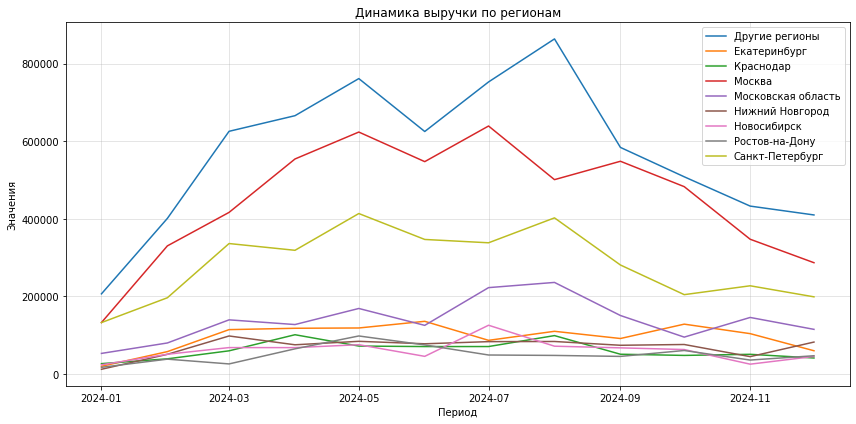

In [ ]:

# Группируем данные по месяцам и регионам для расчёта выручки
revenue_region = orders_ltv.groupby(['order_month', 'region'])['revenue'].sum().reset_index(name='revenue_sum')

# Визуализируем динамику выручки
plt.subplots(figsize=(12,6))
for region in revenue_region['region'].unique():
    df_plot = revenue_region[revenue_region['region'] == region]
    plt.plot(df_plot['order_month'], df_plot['revenue_sum'], label=region, color=colors.get(region))

# Оформляем график
plt.title('Динамика выручки по регионам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

Основной объем выручки обеспечивают "Другие регионы" (пик более 850 тыс. в августе) и Москва (пик около 650 тыс в июле). Обе линии показывают резкое снижение к концу года. Санкт-Петербург занимает третье место - в августе выручка обвалилась с 400 до 200 тыс. Стабильно низкие показатели: Остальные города (Екатеринбург, Новосибирск, Краснодар и др.) находятся в группе с выручкой ниже 150 тыс. Несмотря на общее падение, эти регионы практически не росли в течение года.

Рассчитаем и визуализируем метрика DAU и MAU.

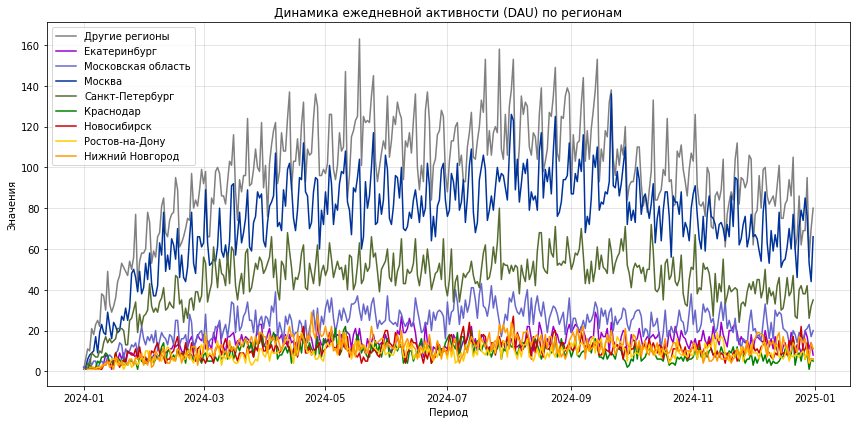

In [ ]:
# Создадим словарь цветов для регионов
colors = {
    'Москва': '#003399',
    'Санкт-Петербург': '#556B2F',
    'Краснодар': '#008000',
    'Нижний Новгород': '#FF9900',
    'Екатеринбург': '#9900CC',
    'Новосибирск': '#CC0000',
    'Ростов-на-Дону': '#FFCC00',
    'Московская область': '#6666CC',
    'Другие регионы': '#808080'
}

# Используем функцию plot_metric_by_segment для построения графика динамики DAU
plot_metric_by_segment(pa_marketplace_events, 'event_date', 'user_id', 'region', 'Динамика ежедневной активности (DAU) по регионам')

График динамики ежедневной активности (DAU) по регионам показывает распределение пользовательской активности в течение 2024 года.

Самые высокие показатели  демонстрируют Москва и категория "Другие регионы". Их активность росла до середины года, достигая пиков в 120-160 пользователей в день, после чего стабилизировалась с небольшим снижением к концу года. Наблюдается значительный отрыв столицы от остальных городов. Следующим по активности идет Санкт-Петербург, чей DAU колеблется в районе 40–60 пользователей. Московская область показывают схожую динамику с активностью до 20-40 человек в день.
Стабильно низкая активность у группы говородов: Краснодар, Новосибирск, Екатеринбург, Ростов-на-Дону и Нижний Новгород. У этих городов показатели DAU минимальны и практически не показывают роста, оставаясь в пределах 5-20 пользователей на протяжении всего года.

Аномалий или существенных изменений в динамике DAU не выявлено.


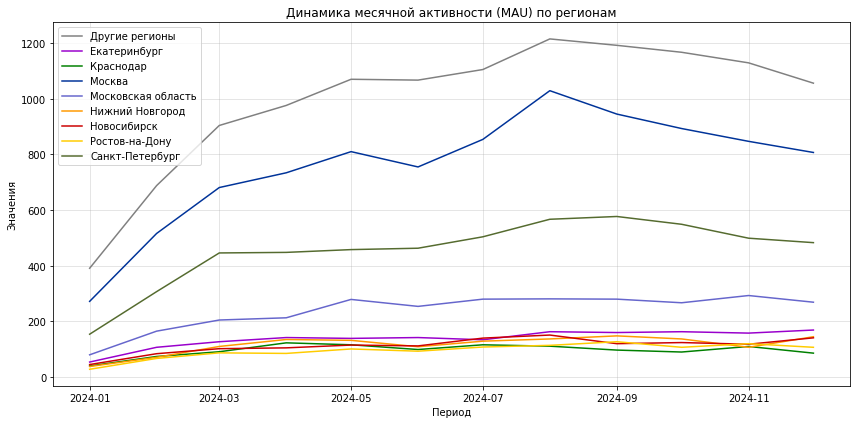

In [ ]:
plot_metric_by_segment(pa_marketplace_events, 'event_month', 'user_id', 'region', 'Динамика месячной активности (MAU) по регионам')



График MAU по регионам очень близок графику DAU по структуре распределения аудитории.
Основной объем аудитории формируют "Другие регионы" (пик больше 1200 пользователей в месяц) и Москва (пик около 1000). Оба сегмента показали активный рост до августа, после чего началось постепенное снижение. Санкт-Петербург занимает третье место с MAU в районе 500-600 человек. Московская область стабильно держится на уровне 250-300 пользователей. Екатеринбург, Новосибирск, Краснодар, Ростов-на-Дону и Нижний Новгород объединяются в группу с низкой активностью: в среднем до 150 пользователей в месяц без выраженной динамики роста.

Кривая роста и спада активности в регионах полностью повторяет общую динамику продукта без заметных отклонений. Это подтверждает, что негативные тренды второго полугодия затронули всю географию присутствия одинаково.

Рассмотрим далее динамику по количеству заказов.

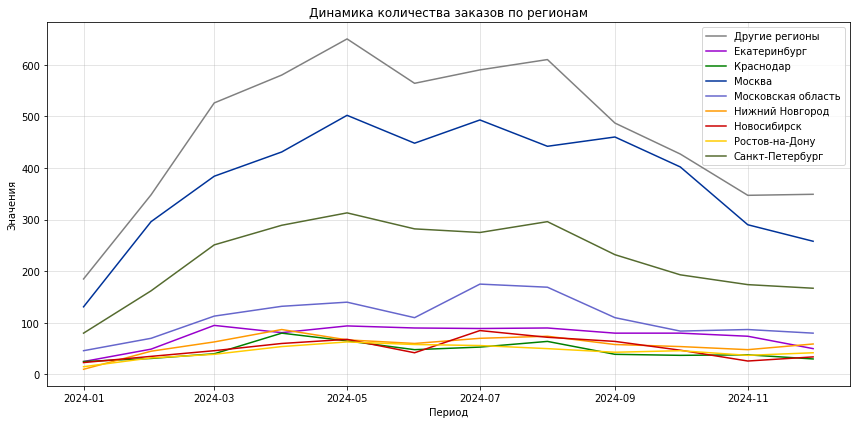

In [ ]:
# Формируем список уникальных заказов (объединяем товары, купленные одновременно)
unique_orders_region = orders_ltv.groupby(['user_id', 'order_date', 'order_month', 'region']).size().reset_index()

# Группируем данные по месяцам и регионам для расчёта количества заказов
orders_per_month_region = unique_orders_region.groupby(['order_month', 'region']).size().reset_index(name='order_count')

# Визуализируем динамику количества заказов по регионам
plt.subplots(figsize=(12,6))
for region in orders_per_month_region['region'].unique():
    df_plot = orders_per_month_region[orders_per_month_region['region'] == region]
    plt.plot(df_plot['order_month'], df_plot['order_count'], label=region, color=colors.get(region))

# Оформляем график
plt.title('Динамика количества заказов по регионам')
plt.xlabel('Период')
plt.ylabel('Значения')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


График заказов (оплат) по регионам повторяет общую динамику по продукту, что указывает на отсутствие региональных аномалий: рост до мая, затем спад. Основной объем продаж обеспечивают "Другие регионы" (пик около 650 заказов) и Москва (пик около 500).  Далее идут Санкт-Петербург (стабилизировался на уровне около 200 заказов) и Московская область (примерно 100 заказов) демонстрируют схожий тренд снижения активности к концу года. Остальные города (Краснодар и др.) сохраняют стабильно низкие показатели в пределах 50-80 заказов в месяц.

Теперь рассчитаем средний чек по регионам.

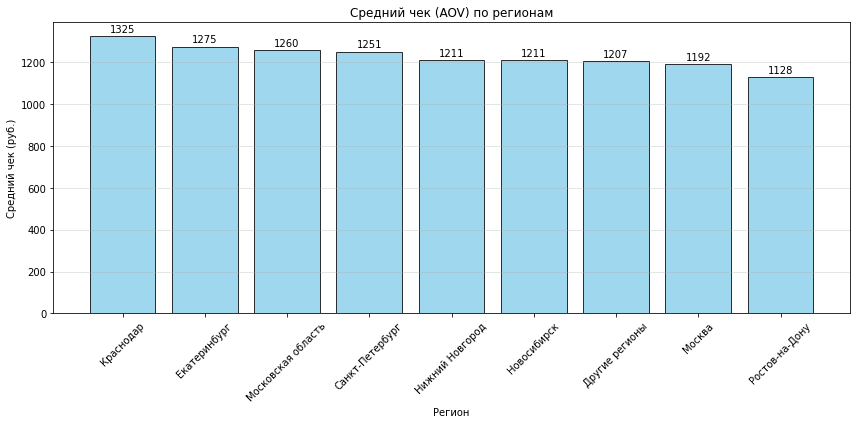

In [ ]:
# Группируем данные до уровня уникальных заказов и считаем выручку по каждому заказу
region_orders = pa_marketplace_orders.groupby(['region', 'user_id', 'order_date'])['revenue'].sum().reset_index()

# Считаем средний чек по регионам
region_aov = region_orders.groupby('region')['revenue'].mean().reset_index(name='aov')

# Сортируем данные по убыванию среднего чека для наглядности
region_aov = region_aov.sort_values(by='aov', ascending=False)

# Строим столбчатую диаграмму в matplotlib
plt.figure(figsize=(12, 6))

plt.bar(region_aov['region'], region_aov['aov'], color='skyblue', edgecolor='black', alpha=0.8)

# Добавляем подписи значений над столбцами
for i, val in enumerate(region_aov['aov']):
    plt.text(i, val + 10, f'{val:.0f}', ha='center', va='bottom')

# Оформляем график
plt.title('Средний чек (AOV) по регионам')
plt.xlabel('Регион')
plt.ylabel('Средний чек (руб.)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()


Анализ среднего чека (AOV) по регионам показал, что лидеры по объему выручки оказались в конце списка по среднему чеку.

Краснодар уверенно занимает первое место с самым высоким средним чеком (1325 руб.). При этом Москва находится в конце списка (предпоследнее место) с чеком ниже 1200 руб. Это говорит о том, что в столице пользователи чаще совершают небольшие покупки (вероятно, из категории "Продукты" или других бытовых), в то время как в регионах маркетплейс используют для более крупных и редких приобретений. Ростова-на-Дону замыкает рейтинг с самым низким чеком, что в сочетании с его низкой общей выручкой указывает на серьезные проблемы с вовлечением платежеспособной аудитории.

**Инсайт**: <br>
Высокая выручка Москвы держится исключительно на массовости и количестве заказов, а не на их цене. В то же время Краснодар и Екатеринбург показывают более здоровую экономику одного заказа. Это значит, что логистические затраты на один заказ в этих регионах окупаются лучше, чем в столице.

**Точка роста**: <br>
Необходимо изучить рекламные кампании в Краснодаре. Если там удается продавать товары с высоким чеком, этот опыт (и ассортиментную матрицу) нужно переносить на другие регионы.
Необходимо работать с чеком в Москве.  Внедрить инструменты дополнительных продаж, например, предлагать сопутствующие товары в корзине или давать небольшую скидку при увеличении суммы заказа. Из-за большого количества заказов в столице даже небольшая прибавка к каждому чеку в сумме даст ощутимый рост выручки всей компании за счёт масштаба без затрат на привлечение новых клиентов.



<p style="font-size:20px"><strong>Анализ сегментов пользователей</strong></p>

Пользователи разделены на 4 сегмента покупательской активности: regular, rare, one_time и medium.
Рассмотрим эти сегменты подробнее. Сначала посмотрим, как распределяются пользователи и покупатели по сегментам.

In [ ]:
# Рассчитаем количество привлеченных пользователей по каждому сегменту
buyer_segment_users = pa_marketplace_users.groupby('buyer_segment')['user_id'].nunique().reset_index(name='n_users')
# Добавим столбец с долей пользователей сегмента от всех пользователей
buyer_segment_users['ratio'] = (buyer_segment_users['n_users'] / buyer_segment_users['n_users'].sum()).round(2)

# Выведем число привлечнных пользователей по источникам, отсортировав их по убыванию
display(buyer_segment_users.sort_values(by='n_users', ascending=False))

,buyer_segment,n_users,ratio
0,medium,16421,0.37
2,rare,13256,0.30
3,regular,7773,0.18
1,one_time,6701,0.15


In [ ]:
# Рассчитаем количество покупателей по каждому сегменту
buyer_segment_orders = pa_marketplace_orders.groupby('buyer_segment')['user_id'].nunique().reset_index(name='n_users')
# Добавим столбец с долей покупателей сегмента от всех покупателей
buyer_segment_orders['ratio'] = (buyer_segment_orders['n_users'] / buyer_segment_orders['n_users'].sum()).round(2)

# Выведем число привлечнных пользователей по источникам, отсортировав их по убыванию
display(buyer_segment_orders.sort_values(by='n_users', ascending=False))

,buyer_segment,n_users,ratio
3,regular,3716,0.43
0,medium,3692,0.43
2,rare,988,0.11
1,one_time,258,0.03


Более 85% пользователей относятся к сегментам со средней и высокой частотой покупок. Остальные покупают редко или один раз.
Учитывая, что лишь часть аудитории продукта производит заказы, непонятно, каким образом пользователи, которые не совершали покупку из таблицы `pa_marketplace_users` попали в тот или иной сегмент.

Далее посмотрим описательные статистики по сегментам.


In [ ]:


# Группируем товарные позиции в уникальные заказы по пользователям и датам
orders_by_buyer_segment = orders_ltv.groupby(['buyer_segment', 'user_id', 'order_date']).size().reset_index()

# Считаем общее количество заказов для каждого пользователя внутри сегмента
user_orders = orders_by_buyer_segment.groupby(['buyer_segment', 'user_id']).size().reset_index(name='user_orders_total')

# Рассчитываем описательную статистику по сегментам
buyer_segment_stats = user_orders.groupby('buyer_segment')['user_orders_total'].describe(
    percentiles=[.25, .5, .75, .95]
)

# Выводим итоговую таблицу
display(buyer_segment_stats)



,count,mean,std,min,25%,50%,75%,95%,max
buyer_segment,,,,,,,,,
medium,3692.0,1.524106,0.917167,1.0,1.0,1.0,2.0,3.0,9.0
one_time,258.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0,1.0
rare,988.0,1.143725,0.399583,1.0,1.0,1.0,1.0,2.0,4.0
regular,3716.0,2.824004,2.490623,1.0,1.0,2.0,4.0,8.0,25.0


Описательная статистика раскрывает структуру сегментации (лояльности), которая отличается от названий сегментов.
У сегмента `medium` медиана равна 1. Это значит, что более половины пользователей в этой группе совершили всего один заказ, несмотря на название категории. B даже в самом активном сегменте медиана составляет всего 2, то есть основная доля "лояльных" клиентов ограничивается двумя покупками. Разница между 95-м перцентилем (8) и максимумом (25) в сегменте `regular` значительная - это говорит о наличии набольшого числа пользователей, которые сильно завышают среднее значение.
Сегмент `rare` практически не отличается от `one_time`, поскольку 75% пользователей здесь также сделали всего по одному заказу.

**Инсайт**: <br>
Текущая сегментация в базе данных вводит в заблуждение. В маркетплейсе очень мала доля пользователей, которые на самом деле совершают покупки регулярно. В основном в продукте наблюдается короткий цикл потребления, то есть для большинства пользователей "лояльность" заканчивается на втором заказе. Реальная группа постоянных лояльных пользователей это те, кто кто совершил более 8  покупок (это составляет менее 5% от сегмента `regular`). В целом анализ сегментации пользователей подтверждает выводы сделанные на предыдущем этапе при исследовании ретеншна.


**Точки роста**:  <br>
Главная зона роста - это конверсия во вторую, третью покупку. Поскольку даже в основном в сегментах большинство людей с 1 заказом, компании нужно сфокусироваться на преодолении порога одного заказа. Например, можно внедрять скидки или другие типы стимулирования к заказу  после 2-й покупки. Кроме того, необходимо также работать с конверсией в четвертую и последующие покупки за счет стимулирования пользователей к повторным покупкам.

Необходимость пересмотра системы сегментации. Текущие критерии присвоения сегментов не отражают реальную ценность клиента и его активность. Необходимо внедрить прозрачную RFM-сегментацию, чтобы разделять лояльных клиентов от тех, кто совершил пару покупок и перестал пользоваться продуктом.


Дополнительно посмотрим на среднюю и медиальную выручку, а также глубину чека по сегментам.

In [ ]:
# Групперуем данные до уровня уникальных заказов, считая выручку и глубину чека
orders_stats = orders_ltv.groupby(['buyer_segment', 'user_id', 'order_date']).agg({
    'revenue': 'sum',
    'order_id': 'count',
    'quantity': 'sum'
}).reset_index()

# Считаем итоговые показатели выручки, количество позиций в чеке, количестве товаров в разрезе сегментов
segment_pivot = orders_stats.groupby('buyer_segment').agg({
    'revenue': ['mean', 'median'],
    'order_id': 'mean',
    'quantity': 'mean'
}).round(2)

# Переименовываем столбцы для удобства
segment_pivot.columns = ['avg_revenue', 'median_revenue', 'avg_basket_depth', 'avg_quantity']

# Выводим таблицу, отсортированную по среднему чеку
display(segment_pivot.sort_values(by='avg_revenue', ascending=False))


,avg_revenue,median_revenue,avg_basket_depth,avg_quantity
buyer_segment,,,,
regular,1418.949951,862.479980,2.01,4.04
rare,926.469971,535.989990,1.33,2.68
medium,922.429993,519.239990,1.34,2.68
one_time,856.789978,487.670013,1.34,2.46


У покупателей из сегмента `regular` средний чек (1418.9 руб.), что значительно выше, чем у остальных сегментов. При этом медианный чек 862.5 руб., что говорит, скорее всего, о присутствии разовых дорогих покупок.
Сегменты `rare` и `medium` демонстрируют практически одинаковые знаения по среднему чеку (около 925 руб.) и их составы глубина чека почти идентичны.
У `one_time` пользователей самый низкий чек (856.8 руб.).

**Инсайт**: <br>
Главное различие между сегментами прослеживается в глубине чека. У сегмента `regular` показатель avg_basket_depth составляет 2.01, тогда как у всех остальных групп он в районе 1.33-1.34. Это означает, что лояльные клиенты покупают товары наборами, в то время как остальные чаще всего покупают что-то одно и игнорируют сопутствующие товары.

**Точка роста**: <br>
Важный потенциал в увеличении глубины чека для сегментов `one_time`, `rare` и `medium`. Различные механики по стимулированию
к добавлению второй позиции в корзину (например, через "вместе дешевле" или персонализированные рекомендации) позволит поднять их средний чек до того, как они станут постоянными клиентами.

Далее посмотрим на то, как распеределены категории товаров по сегментам пользователей.

In [ ]:
# Считаем количество товаров по категориям и сегментам
category_stats = orders_ltv.groupby(['category_name', 'buyer_segment'])['order_id'].count().unstack(fill_value=0)

# Рассчитываем долю каждой категории внутри сегмента (по столбцам)
# Сразу применяем округление до одного знака
category_share = category_stats / category_stats.sum() * 100

# Выбираем Топ-10 категорий по общим продажам
top_10_categories = pa_marketplace_orders['category_name'].value_counts().head(10).index
cat_share_final = category_share.loc[top_10_categories]

# Выстраиваем сегменты в логическом порядке: от разовых к регулярным
segment_order = ['one_time', 'rare', 'medium', 'regular']
cat_share_final = cat_share_final[segment_order]

# Визуализируем через градиент, сортируя по самому лояльному сегменту
cat_share_final = cat_share_final.sort_values(by='regular', ascending=False).style.background_gradient(cmap='YlGn', axis=0)

# Выводим таблицу
cat_share_final


buyer_segment,one_time,rare,medium,regular
Продукты питания,14.782609,12.458361,12.260893,13.069476
Детская одежда,4.927536,4.996669,4.423486,4.498861
Книги и канцтовары,4.057971,3.664224,4.024973,4.342255
Зоотовары,4.057971,4.197202,5.074389,4.285308
Одежда для спорта,4.637681,2.798135,3.971838,4.109719
Товары для кухни,2.898551,4.330446,3.706164,4.052771
Женская одежда,4.637681,2.998001,3.493624,3.943622
Обувь женская,6.086957,4.397069,3.706164,3.872437
Обувь мужская,4.347826,4.330446,3.998406,3.862946
Аксессуары для гаджетов,3.478261,3.997335,4.596174,3.815490


Таблица демонстрирует распределение продаж по категориям внутри каждого сегмента. В целом здесь инсайтов не обнаружено, поскольку данные однородны. Профили потребления всех групп практически идентичны. "Продукты питания" ожидаемо занимают первое место во всех сегментах с долей 12-15%. Небольшие колебания в долях женской обуви или одежды для спорта носят скорее случайный характер.


**Промежуточный вывод: анализ сегментов пользователей**

Анализ сегментов показал, что текущая лояльность в продукте носит скорее номинальный характер и ограничена коротким циклом потребления.
- Медиана количества заказов даже в сегменте `regular` всего 2, а в `medium` - 1. Значит, большинство "лояльных" пользователей по факту совершили всего одну-две покупки.
- Период жизни "регулярного" клиента и нового пользователя практически идентичен. В пользовательской базе крайне мало клиентов, которые покупали бы на протяжении долгого времени.

<p style="font-size:20px"><strong>Анализ категорий товаров</strong></p>

Проведем анализ категорий товаров. Прежде всего, посмотрим на топ-10 категорий по общей выручки, средней цене, доле от всей выручки.

In [ ]:
# Группируем данные по категориям для расчета ключевых метрик
category_top = pa_marketplace_orders.groupby('category_name').agg(
    orders_count=('order_id', 'count'),
    total_revenue=('revenue', 'sum'),
    avg_price=('unit_price', 'mean')
).reset_index()

# Добавляем долю выручки для оценки значимости каждой категории
category_top['revenue_share_%'] = (category_top['total_revenue'] / category_top['total_revenue'].sum() * 100).round(2)

# Сортируем по выручке
category_top = category_top.sort_values(by='total_revenue', ascending=False).round(2)

# Настраиваем и Выводим топ-10 категорий
styled_category = category_top.head(10).style.format({
    'total_revenue': '{:.0f}',
    'avg_price': '{:.1f}',
    'revenue_share_%': '{:.2f}'
})
styled_category


,category_name,orders_count,total_revenue,avg_price,revenue_share_%
11,Мебель для дома,979,3580998,36413.3,16.28
2,Бытовая техника,1030,2248933,21855.6,10.22
24,Украшения и часы,1024,1718297,16682.3,7.81
18,Спортивный инвентарь,1000,1165361,11614.3,5.30
23,Товары для туризма,970,1137318,11695.7,5.17
0,Автотовары,1043,1044822,9829.8,4.75
21,Товары для кухни,1237,1030402,8374.1,4.68
15,Обувь мужская,1253,942482,7571.5,4.28
20,Сумки и аксессуары,1180,873491,7477.2,3.97
14,Обувь женская,1211,860489,7077.6,3.91


Категории Мебель, Бытовая техника и Украшения суммарно приносят 34% всей выручки. Это дорогостоящие сегменты с самым высоким средним чеком (от 16 до 36 тыс. руб.). Категории Обувь и Товары для кухни лидируют по количеству заказов (>1200) среди топ-10 по объему выручки, но из-за низкого чека их вклад в выручку в 3-4 раза меньше, чем у мебели. Топ-10 категорий обеспечивают более 66% выручки маркетплейса, получается, что бизнес сильно зависит от продаж товаров с высоким чеком.

Посмотрим теперь на топ-10 товаров по количеству заказов.

In [ ]:
# Сортируем по количеству заказов
category_top = category_top.sort_values(by='orders_count', ascending=False)

# Выводим топ-10 категорий по количеству заказов
styled_category = category_top.head(10).style.format({
    'total_revenue': '{:.0f}',
    'avg_price': '{:.1f}',
    'revenue_share_%': '{:.2f}'
})
styled_category

,category_name,orders_count,total_revenue,avg_price,revenue_share_%
17,Продукты питания,4027,596448,1478.9,2.71
4,Детская одежда,1421,321305,2240.9,1.46
7,Зоотовары,1396,372584,2628.9,1.69
9,Книги и канцтовары,1316,204443,1548.2,0.93
1,Аксессуары для гаджетов,1255,693470,5403.5,3.15
15,Обувь мужская,1253,942482,7571.5,4.28
16,Одежда для спорта,1248,535901,4206.8,2.44
21,Товары для кухни,1237,1030402,8374.1,4.68
14,Обувь женская,1211,860489,7077.6,3.91
6,Женская одежда,1191,687335,5680.0,3.12


Категория Продукты питания лидирует с отрывом (более 4000 заказов), что в 3 раза выше ближайших конкурентов. Тем не менее разрыв на коллосальный, что говорит о том, что в маркетплейсе не преварирует эта категория. Большинство категорий (Продукты, Книги, Детская одежда) имеют самый низкий средний чек  (от 1.5 до 2.5 тыс. руб.). Они создают частоту покупок, но почти не влияют на выручку. Обувь и Товары для кухни - эьо единственные категории, которые входят в топ и по заказам, и по деньгам.



In [ ]:
# Считаем выручку по регионам и категориям
region_cat_revenue = pa_marketplace_orders.groupby(['region', 'category_name'])['revenue'].sum().unstack(fill_value=0)

# Переводим в доли внутри каждого региона (по строкам), чтобы сравнить структуру
region_cat_share = region_cat_revenue.div(region_cat_revenue.sum(axis=1), axis=0) * 100

# Оставляем только те Топ-10 категорий по выручке
top_10_revenue_cats = ['Мебель для дома', 'Бытовая техника', 'Украшения и часы',
                       'Спортивный инвентарь', 'Товары для туризма', 'Автотовары',
                       'Товары для кухни', 'Обувь мужская', 'Сумки и аксессуары', 'Обувь женская']

region_cat_share = region_cat_share[top_10_revenue_cats].round(1)

# Визуализируем через тепловую карту для поиска аномалий
styled_region_share = region_cat_share.style.background_gradient(cmap='YlOrRd', axis=1).format("{:.1f}%")

display(styled_region_share)


category_name,Мебель для дома,Бытовая техника,Украшения и часы,Спортивный инвентарь,Товары для туризма,Автотовары,Товары для кухни,Обувь мужская,Сумки и аксессуары,Обувь женская
region,,,,,,,,,,
Другие регионы,16.2%,10.1%,8.9%,5.0%,4.8%,4.5%,4.8%,3.9%,3.2%,3.9%
Екатеринбург,15.9%,11.2%,6.9%,5.8%,8.1%,3.4%,4.9%,5.3%,3.2%,4.5%
Краснодар,21.9%,7.5%,8.7%,6.4%,4.4%,3.2%,6.8%,4.2%,3.3%,4.8%
Москва,16.1%,10.0%,5.9%,4.5%,5.7%,5.4%,4.8%,4.4%,4.1%,3.5%
Московская область,15.1%,10.0%,10.2%,6.3%,5.5%,4.1%,3.9%,4.8%,4.9%,3.6%
Нижний Новгород,13.2%,14.0%,6.4%,6.5%,4.8%,3.0%,2.9%,5.9%,5.4%,4.1%
Новосибирск,12.3%,7.2%,7.5%,6.5%,7.2%,4.7%,4.9%,3.3%,5.1%,5.0%
Ростов-на-Дону,10.4%,14.4%,6.1%,8.2%,3.7%,6.6%,4.9%,3.3%,5.0%,4.2%
Санкт-Петербург,18.8%,10.3%,8.0%,4.5%,4.4%,5.3%,4.7%,3.9%,4.4%,4.3%


Таблица показала, что есть региональная специфика, которую можно использовать для точечного роста.

*Мебель* - лидер почти везде: категория держит долю 15–19% в большинстве городов. Однако в Краснодаре наблюдается аномальный пик - 21.9%, а в Ростове-на-Дону, наоборот, провал до 10.4%.
*Бытовая техника* в большем приоритете у регионов: В Нижнем Новгороде и Ростове-на-Дону эта категория обходит мебель, занимая  14-14.4% (самые популярные категории в этих регионах).
*Товаров для туризма*  пользуются спросом в Екатеринбурге (8.1%) и Новосибирске (7.2%).
*Спортивный инвентарь* с небольшим перевесом лидирует в Московской области (10,2%)

**Инсайт**:
У маркетплейса нет единого профиля потребления. Это можно использовать в рекламе.

**Точка роста**:
Локальное акции и программы по конктертному ассортименту. В Краснодаре нужно усиливать рекламу мебели - там на это есть сформированный спрос. В Ростове и Нижнем Новгороде делать упор на бытовую технику. В Екатеринбурге и Новосибирске использовать туризм как категорию для привлечения новых пользователей.

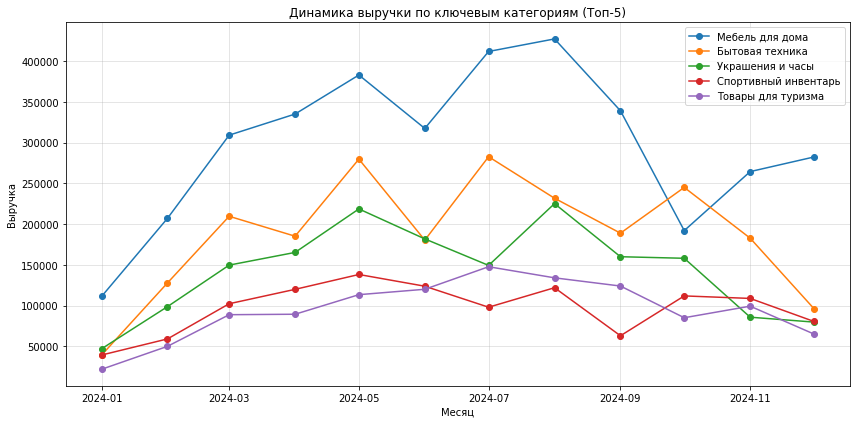

In [ ]:
# Считаем выручку по месяцам для каждой категории
cat_dynamic = pa_marketplace_orders.groupby(['order_month', 'category_name'])['revenue'].sum().reset_index()

# Определяем Топ-5 категорий по суммарной выручке за весь период
top_5_cats = pa_marketplace_orders.groupby('category_name')['revenue'].sum().sort_values(ascending=False).head(5).index

# Фильтруем данные только для этих топ-категорий
cat_dynamic_top = cat_dynamic[cat_dynamic['category_name'].isin(top_5_cats)]

# Строим график
plt.subplots(figsize=(12, 6))
for cat in top_5_cats:
    df_plot = cat_dynamic_top[cat_dynamic_top['category_name'] == cat]
    plt.plot(df_plot['order_month'], df_plot['revenue'], label=cat, marker='o')

# Оформляем визуализацию
plt.title('Динамика выручки по ключевым категориям (Топ-5)')
plt.xlabel('Месяц')
plt.ylabel('Выручка')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()



Категория Мебель для дома, которая была главным локомотивом роста до августа (пик - более 400 тыс.), к октябрю обвалилась в два раза. Несмотря на рост в конце года, она так и не вернулась к прежним показателям. Самый тревожный сигнал - динамика Бытовой техники и Украшений в декабре. Вместо ожидаемого преднновогоднего пика обе категории показали резкое падение. Бытовая техника снизилась с 250 до 100 тыс. Спортивный инвентарь и Товары для туризма начали снижаться с августа, но их вклад в общую выручку небольшой.

Чтобы проверить, какова динамика товаров из иной ценовой категории, посмотрим на самые популярные товары по количеству продаж.


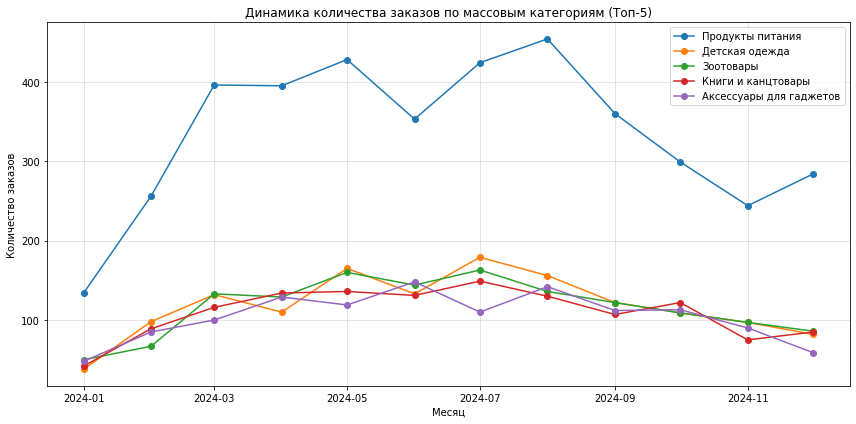

In [ ]:
# Считаем количество заказов по месяцам для каждой категории
cat_orders_dynamic = pa_marketplace_orders.groupby(['order_month', 'category_name'])['order_id'].count().reset_index(name='order_count')

# Определяем Топ-5 категорий по количеству заказов за весь период
top_5_sales_cats = pa_marketplace_orders['category_name'].value_counts().head(5).index

# Фильтруем и строим график
cat_orders_top = cat_orders_dynamic[cat_orders_dynamic['category_name'].isin(top_5_sales_cats)]

plt.subplots(figsize=(12, 6))
for cat in top_5_sales_cats:
    df_plot = cat_orders_top[cat_orders_top['category_name'] == cat]
    plt.plot(df_plot['order_month'], df_plot['order_count'], label=cat, marker='o')

plt.title('Динамика количества заказов по массовым категориям (Топ-5)')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()




Категория Продукты питания показала резкое падение во втором полугодии. С августа (более 450 заказов в месяц) она рухнула до 250 к ноябрю. Это критично, так как именно эта категория удерживала пользователей в приложении.
Все остальные массовые категории (Детская одежда, Зоотовары, Книги) показывают идентичный тренд - плавный рост до середины года и затяжное падение к декабрю. В отличие от дорогой техники, массовые товары в декабре показали не такой сильный спад.

## Выводы по этапу 4

<p style="font-size:20px"><strong>Аналитическая записка: Поиск точек роста и аномалий</strong></p>


- *Какие сегменты работают лучше и хуже остальных?* <br>

**Каналы привлечения** <br>
Лидерами по привлечению качественной аудитории являются `Affiliate` и `SEO` (быстрая окупаемость, высокое удержание и конверсия). Худшим сегментом признан `TikTok`: с июля стал основным каналом по объему регистраций, но не дал целевых показателей. У канала худший Stickiness (около 5%) и низкая конверсия в покупку (2-3%). Ни одна когорта за 2024 год не вышла в окупаемость. Источник не формирует лояльную базу. `Google Ads` был ключевым источником качественной аудитории и выручки в первой половине года. Показывал стабильную окупаемость на 1-й месяц. Отключение канала в ноябре стало одной из причин снижения выручки в конце года. На `Direct` тратятся бюджеты на маркетинг, но в данных этот канал не атрибутирован по пользователям. Это говорит либо о техническом сбое - не видим  пользователей канала в системе, либо о том, что деньги уходят впустую: канал приводит трафик, который не регистрируется в приложении.

**Регионы** <br>
Москва и Другие регионы - лидеры по объему выручки. Краснодар выделяется качеством заказов: у него самый высокий средний чек (1321 руб.) и высокая доля категории «Мебель для дома» (22%). Худшая динамика и самый низкий чек - у Ростова-на-Дону.

**Пользовательская лояльность** <br>
Сегментация в базе данных номинальна. Реально регулярыне пользователи составляют примерно только 5% базы (те, кто совершил более 8 заказов). Основная часть аудитории совершают покупки 1-2 раза и имеют «короткий» жизненный цикл в 60-90 дней.


- *На каких этапах воронки теряются пользователи?* <br>

В пользовательском пути выделяются два критических узких места:
Активация (регистрация → просмотр страниц): только 50% зарегистрированных пользователей начинают использовать приложение. Столь резкий отсев на старте указывает на системную проблему - вероятно, существует техническая ошибка после регистрации или отсутствует понятный онбординг, что мешает пользователю перейти к изучению товаров.

Оплата (оформление заказа → оплата): на финальном шаге оплату совершают только 44.5% пользователей. Одинаково низкая конверсия для всех устройств подтверждает наличие барьера в момент платежа. Скорее всего, клиентов не устраивают доступные способы оплаты или условия (цена и сроки доставки), которые становятся понятны только на этом этапе.

- *Группы для масштабирования и инвестиций* <br>

Изменение стратегии по каналам привлечения. Необходимо прекратить масштабирование и значительно сократить бюджет на `TikTok`. Масштабирование `Affiliate` и `SEO`: нужно увеличить охваты, даже при росте CAC, так как это самые стабильные источники с ROI первого месяца. Сохранить текущие расходы на `Social Media` с небольшим увеличением бюджета. Во втором полугодии канал показал качественный рост и обошел `TikTok` по заказам при меньших затратах.

Работа с удержанием. Основные усилия нужно направить на пользователей в первые 30–60 дней. Так как значительная часть аудитории перестает покупать уже к 3-му месяцу, важно автоматизировать рассылки и спецпредложения именно в этот период. Необходимо успеть перевести новичка в категорию постоянного клиента через 2-й и 3-й заказы.

Региональное развитие. Необходимо проанализировать рекламные кампании и структуру продаж в Краснодаре. Успешный опыт реализации товаров с высоким чеком (мебель) и текущую ассортиментную матрицу региона следует адаптировать и протестировать в других перспективных городах.

**Гипотезы по развитию продукта** <br>
*Гипотеза №1: Оптимизация платежного пути* <br>
Если на этапе оформления заказа явно указать свдения о способах оплаты и условиях заказа (например, стоимость и сроки доставки), то конверсия из checkout_complete в payment вырастет с 44.5% до 55%.
Обоснование: Статистика воронки показывает, что более половины клиентов не оплачивают заказ после его оформления. Это характерно для ситуаций, когда пользователь сталкивается с внезапным ростом итоговой суммы или отсутствием удобного способа оплаты на последнем шаге. <br>


*Гипотеза №2: Увеличение глубины чека*  <br>
Если внедрить инструменты товарных рекомендаций и механику "вместе дешевле" для сегментов пользователей `one_time`, `rare` и `medium`, то их средний чек вырастет до уровня лояльных пользователей (`regular`).
Обоснование: Анализ заказов показал, что у лояльных клиентов глубина чека составляет 2, в то время как у остальных групп она замерла на уровне 1.3. Стимулирование покупки второй позиции позволит растить доход с пользователя еще до того, как он станет постоянным клиентом. <br>

*Гипотеза №3: Экспансия «товаров-магнитов» в регионах* <br>
Если перераспределить рекламный бюджет в пользу категории «Мебель» в Краснодаре и «Бытовая техника» в Ростове-на-Дону, то региональная выручка вырастет на 15%.
Обоснование: Региональный срез долей категорий выявил устойчивые предпочтения жителей этих городов, которые сейчас не поддерживаются таргетированным маркетингом.


## 5. Подготовка эксперимента и подведение его результатов



# Новые данные:
```python
pa_marketplace_events_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events_AB.csv')
pa_marketplace_orders_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders_AB.csv')
pa_marketplace_users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users_AB.csv')
```
# Результаты сплита лежат в таблице:
```python
pa_marketplace_AB_split_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_AB_split_users.csv')
```
* user_id – id клиента
* group – группа, в которую попал клиент


# Дизайн эксперимента: Бонус на первую покупку для пользователей TikTok
1. Контекст и цель эксперимента
- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку
---
2. Формат эксперимента
- **Тип эксперимента:** Сплит-роллинг (rolling split)
- **Канал:** Только пользователи, пришедшие с TikTok
- **Группы:**
    - **Контрольная (A):** пользователи TikTok без бонуса
    - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации
- **Период проведения:** 3 недели (фиксировано)
---
3. Ключевые метрики <br>

Основная метрика <br>
- **Конверсия в первую покупку** — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку
- *Цель:* увеличить конверсию с помощью бонуса
- *Критерий успеха:* статистически значимый рост конверсии в тестовой группе

Вспомогательные метрики <br>
- **ARPU** (средняя выручка на пользователя TikTok)
- **ARPPU** (средняя выручка на покупателя TikTok)
- **AOV** (средний чек TikTok)

Барьерная метрика <br>
- **Общая выручка от пользователей TikTok**
---
4. Размеры групп и запуск
- **Целевая аудитория:** только пользователи TikTok
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


Проведем эксперимент, подготовим рекомендации по его итогам, если необходимо, опишем проблемы, присутствующие в тесте.

<p style="font-size:20px"><strong>Загрузка данных и предобработка</strong></p>


In [ ]:
# Выгружаем данные в датафреймы

path = 'https://code.s3.yandex.net/'
events_AB = pd.read_csv(path + '/datasets/pa_marketplace_events_AB.csv', parse_dates=['event_date', 'event_week', 'event_month'])
orders_AB = pd.read_csv(path + '/datasets/pa_marketplace_orders_AB.csv', parse_dates=['order_date', 'order_week', 'order_month'])
users_AB = pd.read_csv(path + '/datasets/pa_marketplace_users_AB.csv', parse_dates=['registration_date', 'cohort_week', 'cohort_month'])
AB_split_users = pd.read_csv(path + '/datasets/pa_marketplace_AB_split_users.csv')

Познакомимся с данными таблицы с пользовательской базой.

In [ ]:
# Выводим первые строки и информацию о пользователях
show_df(users_AB)

,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,49,M,Екатеринбург,TikTok,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,50,M,Санкт-Петербург,TikTok,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,60,F,Москва,TikTok,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,31,M,Екатеринбург,TikTok,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,44,M,Санкт-Петербург,TikTok,rare,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   age                22196 non-null  int64         
 3   gender             22196 non-null  object        
 4   region             22196 non-null  object        
 5   acq_channel        22196 non-null  object        
 6   buyer_segment      22196 non-null  object        
 7   cohort_week        22196 non-null  datetime64[ns]
 8   cohort_month       22196 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 1.5+ MB



In [ ]:
# Выводим первые строки и информацию о пользовательских событиях
show_df(events_AB)

,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01 15:23:56,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01 15:24:01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01 15:24:10,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      831231 non-null  int64         
 1   user_id       831231 non-null  int64         
 2   event_date    831231 non-null  datetime64[ns]
 3   event_type    831231 non-null  object        
 4   os            831231 non-null  object        
 5   device        831231 non-null  object        
 6   product_name  409054 non-null  object        
 7   event_week    831231 non-null  datetime64[ns]
 8   event_month   831231 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 57.1+ MB



In [ ]:
# Выводим первые строки и информацию о заказах
show_df(orders_AB)

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       33280 non-null  int64         
 1   user_id        33280 non-null  int64         
 2   order_date     33280 non-null  datetime64[ns]
 3   product_name   33280 non-null  object        
 4   quantity       33280 non-null  int64         
 5   unit_price     33280 non-null  float64       
 6   total_price    33280 non-null  float64       
 7   category_name  33280 non-null  object        
 8   order_week     33280 non-null  datetime64[ns]
 9   order_month    33280 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.5+ MB



In [ ]:
# Выводим первые строки и информацию о сплитовании пользователей в эксперименте
show_df(AB_split_users)

,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB



Все датаесети, кроме **`pa_marketplace_AB_split_users.csv`** содержат данные о пользователях, их активности и заказах за 2024 и начало 2025 года (включая время проведения эксперимента). Проверим корректность разделения пользователей по группам, затем необходимо объединить информацию о группах эксперимента из таблицы `AB_split_users` с остальными таблицами. После этого еще раз детальнее посмотрим на данные.

In [ ]:
# Сгруппируем пользователей по группам
split_check = AB_split_users.groupby('user_id')['group'].nunique().reset_index(name='group_count')

# Вывежем количество пользователей, которые попали в несколько групп, если таковые произошло
print(f'Количество пользователей, которые попали в две группы: {(split_check["group_count"] > 1).sum()}')

Количество пользователей, которые попали в две группы: 0


In [ ]:
# Добавляем в таблицы  информацию о группах экспермиента
users_AB_filtered = pd.merge(AB_split_users, users_AB, how = 'inner', on = 'user_id')
events_AB_filtered = pd.merge(AB_split_users, events_AB, how = 'inner', on = 'user_id')
orders_AB_filtered = pd.merge(AB_split_users, orders_AB, how = 'inner', on = 'user_id')


Познакомимся детальнее с **таблицей с пользовательской базой** после фильтрации.

In [ ]:
show_df(users_AB_filtered)

,user_id,group,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,44965,control,2025-01-01 18:10:00,66,M,Новосибирск,TikTok,one_time,2024-12-30,2025-01-01
1,44967,control,2025-01-01 11:29:00,70,M,Московская область,TikTok,rare,2024-12-30,2025-01-01
2,44968,control,2025-01-01 13:05:00,68,F,Нижний Новгород,TikTok,regular,2024-12-30,2025-01-01
3,44969,treatment,2025-01-01 00:23:00,24,F,Краснодар,TikTok,medium,2024-12-30,2025-01-01
4,44970,control,2025-01-01 06:33:00,50,M,Санкт-Петербург,TikTok,regular,2024-12-30,2025-01-01


<class 'pandas.core.frame.DataFrame'>
Int64Index: 2968 entries, 0 to 2967
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            2968 non-null   int64         
 1   group              2968 non-null   object        
 2   registration_date  2968 non-null   datetime64[ns]
 3   age                2968 non-null   int64         
 4   gender             2968 non-null   object        
 5   region             2968 non-null   object        
 6   acq_channel        2968 non-null   object        
 7   buyer_segment      2968 non-null   object        
 8   cohort_week        2968 non-null   datetime64[ns]
 9   cohort_month       2968 non-null   datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(5)
memory usage: 255.1+ KB



In [ ]:
# Выводим уникальные значения полей gender, region, acq_channel, buyer_segment
print_unique_categorical_values(users_AB_filtered, ['gender', 'region', 'acq_channel', 'buyer_segment'])

# Выведем количество уникальных значений полей  user_id, region, age, acq_channel, buyer_segment
print_count_uniq_values(users_AB_filtered, ['user_id', 'age', 'region', 'acq_channel', 'buyer_segment'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(users_AB_filtered)

# Проверим датафрейм на наличие неявных дубликатов одновременно по полям: registration_date, age, gender, region
show_subset_duplicates(users_AB_filtered, ['registration_date', 'age', 'gender', 'region'])

# Смотрим времеменной диапозон по полю registration_date
check_time_ranges(users_AB_filtered, ['registration_date'])

gender: ['M' 'F']
region: ['Новосибирск' 'Московская область' 'Нижний Новгород' 'Краснодар'
 'Санкт-Петербург' 'Москва' 'Ростов-на-Дону' 'Другие регионы'
 'Екатеринбург']
acq_channel: ['TikTok']
buyer_segment: ['one_time' 'rare' 'regular' 'medium']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 2968

Количество уникальных значений в user_id: 2968
Количество уникальных значений в age: 53
Количество уникальных значений в region: 9
Количество уникальных значений в acq_channel: 1
Количество уникальных значений в buyer_segment: 4

Дубликатов нет

Анализ дубликатов по столбцам: registration_date, age, gender, region
Найдено строк с дубликатами: 2
Количество уникальных пар/групп дубликатов: 1

Примеры дублирующихся записей:


,user_id,group,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
2538,48315,control,2025-01-23 13:08:00,68,M,Москва,TikTok,one_time,2025-01-20,2025-01-01
2634,48441,treatment,2025-01-23 13:08:00,68,M,Москва,TikTok,rare,2025-01-20,2025-01-01


Анализ колонки: 'registration_date'
Начало периода: 2025-01-01 00:05:00
Конец периода:  2025-01-26 23:41:00
Временной диапазон: 25 дней



**Описание данных таблицы `users_AB_filtered` после добавления сведений о группах эксперимента**: <br>
Таблица состоит из **10 полей и 2968 записей** о пользователях. <br>
- 2968 уникальных пользователей (соответствует количеству записей)
- 53 уникальных значений по возрасту возраста (широкий диапозон по возрасту)
- Пользователи распределены по 9 регионам: Москва, Санкт-Петербург, Краснодар, Нижний Новгород, Екатеринбург, Новосибирск, Ростов-на-Дону, Московская область и Другие регионы
- Все пользователи из канала `TikTok`
- 4 сегмента покупательской активности: regular, rare, one_time и medium
- Явные дубликатов нет, но обнаружен один потенциальный неявный дубликат: два пользователя идентичны по веремени регистрации (до минуты), возрасту, городу, полу.
- Временной диапозон регистраций: с 1 по 26 января 2025 (включительно) - 25 дней.
- Для полей `user_id`, `age` можно понизить разрядность.





Познакомимся с данными **таблицы с пользовательскими событиями**.

In [ ]:
show_df(events_AB_filtered)

,user_id,group,event_id,event_date,event_type,os,device,product_name,event_week,event_month
0,44967,control,843550,2025-01-17 19:32:26,page_view,iOS,tablet,NaN,2025-01-13,2025-01-01
1,44967,control,843551,2025-01-17 19:33:25,product_view,iOS,tablet,Подгузники,2025-01-13,2025-01-01
2,44967,control,843552,2025-01-17 19:33:55,product_click,iOS,tablet,Перчатки кожаные,2025-01-13,2025-01-01
3,44967,control,843553,2025-01-17 19:34:23,add_to_cart,iOS,tablet,Колготки детские,2025-01-13,2025-01-01
4,44967,control,843554,2025-01-17 19:34:54,checkout_start,iOS,tablet,NaN,2025-01-13,2025-01-01


<class 'pandas.core.frame.DataFrame'>
Int64Index: 4349 entries, 0 to 4348
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       4349 non-null   int64         
 1   group         4349 non-null   object        
 2   event_id      4349 non-null   int64         
 3   event_date    4349 non-null   datetime64[ns]
 4   event_type    4349 non-null   object        
 5   os            4349 non-null   object        
 6   device        4349 non-null   object        
 7   product_name  2335 non-null   object        
 8   event_week    4349 non-null   datetime64[ns]
 9   event_month   4349 non-null   datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(5)
memory usage: 373.7+ KB



In [ ]:
# Выводим уникальные значения полей event_type, os, acq_channel, buyer_segment
print_unique_categorical_values(events_AB_filtered, ['event_type', 'os', 'device'])

# Выведем количество уникальных значений полей  event_type, os, acq_channel, buyer_segment
print_count_uniq_values(events_AB_filtered, ['user_id', 'event_type', 'os', 'device'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(events_AB_filtered)

# Проверим датафрейм на наличие неявных дубликатов одновременно по полям: event_id, event_date, user_id
show_subset_duplicates(events_AB_filtered, ['event_id', 'user_id'])

# Смотрим времеменной диапозон по полю event_date
check_time_ranges(events_AB_filtered, ['event_date'])

event_type: ['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'category_view' 'user_logout' 'banner_click'
 'user_login' 'filter_apply' 'promo_view' 'remove_from_cart' 'search'
 'wishlist_add']
os: ['iOS' 'macOS' 'Android' 'Windows']
device: ['tablet' 'desktop' 'mobile']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 4349

Количество уникальных значений в user_id: 499
Количество уникальных значений в event_type: 15
Количество уникальных значений в os: 4
Количество уникальных значений в device: 3

Дубликатов нет

Анализ дубликатов по столбцам: event_id, user_id
Дубликатов по выбранным полям не обнаружено.

Анализ колонки: 'event_date'
Начало периода: 2025-01-02 03:25:32
Конец периода:  2025-01-26 23:46:15
Временной диапазон: 24 дней



**Описание данных таблицы `events_AB_filtered` после добавления сведений о группах эксперимента**: <br>
Таблица состоит из **10 полей и 4349 записей** о пользовательских событиях. <br>
- 499 уникальных пользователей совершили действия в продукте
- Используются 3 типа устройств: mobile, desktop и tablet
- События распределены по 4 операционным системам: iOS, Windows, macOS и Android
- Все пользователи из канала `TikTok`
- Явных и неявных дубликатов не обнаружено.
- Временной диапозон пользовательских событий: с 2 по 26 января 2025 (24 дня).
- Для поля `user_id` можно понизить разрядность.



Познакомимся с данными **таблицы с заказами**.

In [ ]:
show_df(orders_AB_filtered)

,user_id,group,order_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,44970,control,37063,2025-01-04 23:06:48,Пазл 1000 элементов,3,4905.23,14715.69,Детские игрушки,2024-12-30,2025-01-01
1,44984,treatment,37089,2025-01-18 20:22:02,Мокасины кожаные,2,8483.11,16966.22,Обувь мужская,2025-01-13,2025-01-01
2,44993,treatment,37090,2025-01-03 13:29:16,Машинка радиоуправляемая,3,2564.11,7692.33,Детские игрушки,2024-12-30,2025-01-01
3,45002,treatment,37096,2025-01-14 13:37:37,Серьги золотые,1,12508.51,12508.51,Украшения и часы,2025-01-13,2025-01-01
4,45002,treatment,37095,2025-01-14 13:37:37,Перчатки кожаные,3,12847.15,38541.45,Сумки и аксессуары,2025-01-13,2025-01-01


<class 'pandas.core.frame.DataFrame'>
Int64Index: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        255 non-null    int64         
 1   group          255 non-null    object        
 2   order_id       255 non-null    int64         
 3   order_date     255 non-null    datetime64[ns]
 4   product_name   255 non-null    object        
 5   quantity       255 non-null    int64         
 6   unit_price     255 non-null    float64       
 7   total_price    255 non-null    float64       
 8   category_name  255 non-null    object        
 9   order_week     255 non-null    datetime64[ns]
 10  order_month    255 non-null    datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(3)
memory usage: 23.9+ KB



In [ ]:
# Выводим уникальные значения полей product_name, quantity, category_name
print_unique_categorical_values(orders_AB_filtered, ['product_name', 'quantity', 'category_name'])

# Выведем количество уникальных значений полей  user_id, order_id, quantity, product_name, category_name
print_count_uniq_values(orders_AB_filtered, ['user_id', 'order_id',  'quantity', 'product_name', 'category_name'])

# Проверим датафрейм на наличие явных дубликатов
show_duplicates(orders_AB_filtered)

# Проверим датафрейм на наличие неявных дубликатов одновременно по полям: order_id, age, order_date
show_subset_duplicates(orders_AB_filtered, ['order_id', 'order_date'])

# Смотрим времеменной диапозон по полю registration_date
check_time_ranges(orders_AB_filtered, ['order_date'])

product_name: ['Пазл 1000 элементов' 'Мокасины кожаные' 'Машинка радиоуправляемая'
 'Серьги золотые' 'Перчатки кожаные' 'Тумба ТВ' 'Рис длиннозерный'
 'Игрушка-погремушка' 'Масло подсолнечное' 'Цепочка серебряная'
 'Поводок и ошейник' 'Весы кухонные' 'Корм для кошек' 'Чай черный'
 'Куртка детская' 'Джинсы детские' 'Маска для волос' 'Настольная игра'
 'Костюм спортивный' 'Шорты для тренировок']
quantity: [3 2 1]
category_name: ['Детские игрушки' 'Обувь мужская' 'Украшения и часы' 'Сумки и аксессуары'
 'Мебель для дома' 'Продукты питания' 'Товары для новорожденных'
 'Зоотовары' 'Товары для кухни' 'Детская одежда' 'Косметика и парфюмерия'
 'Одежда для спорта' 'Декор и освещение' 'Средства для ухода'
 'Бытовая техника' 'Книги и канцтовары' 'Аксессуары для гаджетов'
 'Инструменты и садовый инвентарь' 'Товары для туризма' 'Мужская одежда']

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 255

Количество уникальных значений в user_id: 126
Количество уникальных значений

**Описание данных таблицы с заказами `orders_AB_filtered` после добавления сведений о группах эксперимента**.

Таблица состоит из **11 полей** и **88 записей** с информацией о заказах.

- 126 уникальных пользователя совершили покупки за период
- Всего 255 уникальных заказов (`order_id`) <br>
Помним, что id заказов (`order_id`) разделены по наименованиям товара - то есть выступают идентификатором позиции в заказе. Если пользователь одномоментно приобрел несколько товаров, в данных это представлено разными строками с одинаковым временем совершения операции.
- В данных представлено 141 наименований товаров (`product_name`)
- Товары распределены по 25 категориям (`category_name`)
- Количество позиций в одном заказе (`quantity`) варьируется от 1 до 3
- Датасет охватывает полный календарный год: с 1 по 26 декабря 2025 (25 дней)
- Явные и неявные дубликаты отсутствуют
- Для оптимизации памяти в полях `order_id`, `user_id`, `quantity`, `unit_price`, `total_price`  можно понизить разрядность


Стоит отметить, что доступный временной диапазон данных превышает трехнедельный период теста. Для анализа будет использована полная выборка, так как увеличение объема данных повышает статистическую мощность исследования и позволяет получить более надежные оценки метрик. Также обратим внимание на то, что эксперимент частично выпал на новогодние праздники, что потенциально может ограничить выводы по разультатам теста, потому что поведение пользователей в праздничные дни и в обычный период обычно различается.

Визуализируем динамику регистраций и заказов по дням, чтобы посмотреть, как меняется поведение пользователей во время эксперимента.

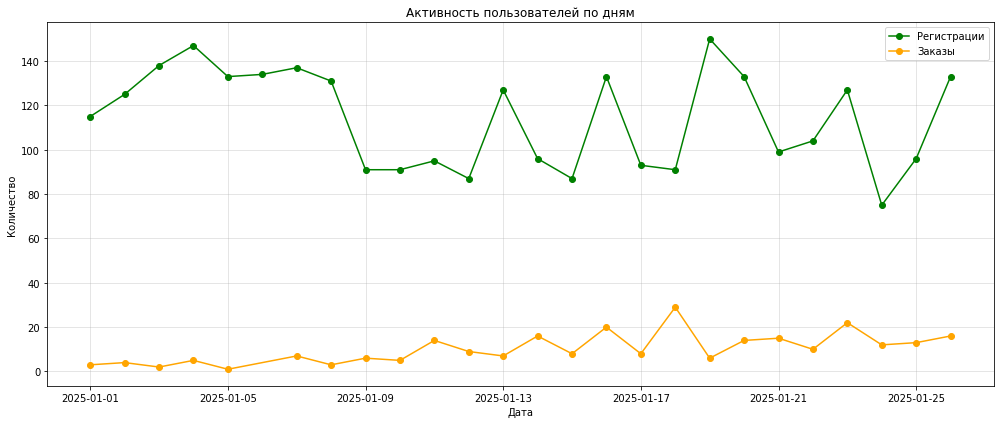

In [ ]:
# Группируем регистрации и заказы по дням
reg_by_day = users_AB_filtered.groupby(users_AB_filtered['registration_date'].dt.date)['user_id'].nunique()
orders_by_day = orders_AB_filtered.groupby(orders_AB_filtered['order_date'].dt.date)['order_id'].nunique()

# Строим графики
plt.figure(figsize=(14, 6))

plt.plot(reg_by_day.index, reg_by_day.values, label='Регистрации', color='green', marker='o')
plt.plot(orders_by_day.index, orders_by_day.values, label='Заказы', color='orange', marker='o')

plt.title('Активность пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


На графике заметно, что в первой дни января регистрации растут, в то время как заказы остаются на минимальном уровне. Вероятно, в праздники пользователи склонны регистрироваться, но откладывают покупки, что может искусственно занизить конверсию. Рост заказов начинается после 10 января.

Из-за того, что эксперимент совпал с новогодними празниками, экстраполяция его результатов на типичное поведение пользователей (то есть поведение не в праздничные дни) ограничена. Это является одной из методологических проблем теста, на которую стоит обратить внимание при интерпретации его итогов.

Проверим сопоставимость групп эксперимента по ключевым атрибутам пользователей. Для корректности выводов группы должны быть сбалансированы по своему составу, иначе результаты теста могут быть искажены (смещением в сторону определенного сегмента, возраста или региона).

Сначала посмотрим на распределение пользователей по группам.

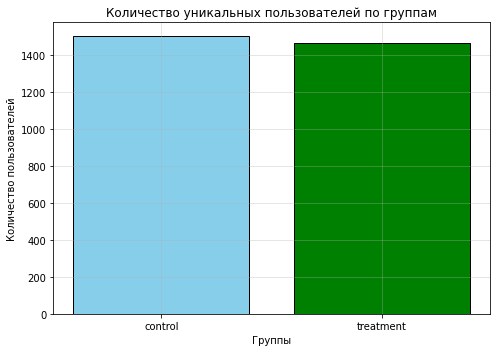

Количество уникальных пользователей в контрольной группе: 1503
Количество уникальных пользователей в тестовой группе: 1465


In [ ]:
# Считаем количество уникальных пользователей по группам
group_counts = users_AB_filtered.groupby('group')['user_id'].nunique()

# Строим график
plt.figure(figsize=(7, 5))
plt.bar(group_counts.index, group_counts.values, color=['skyblue', 'green'], edgecolor='black')

# Оформляем график
plt.title('Количество уникальных пользователей по группам')
plt.xlabel('Группы')
plt.ylabel('Количество пользователей')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

print(f'Количество уникальных пользователей в контрольной группе: {group_counts.values[0]}')
print(f'Количество уникальных пользователей в тестовой группе: {group_counts.values[1]}')

Разбиение аудитории корректно: объем выборок в контрольной (1503) и тестовой (1465) группах сопоставим.

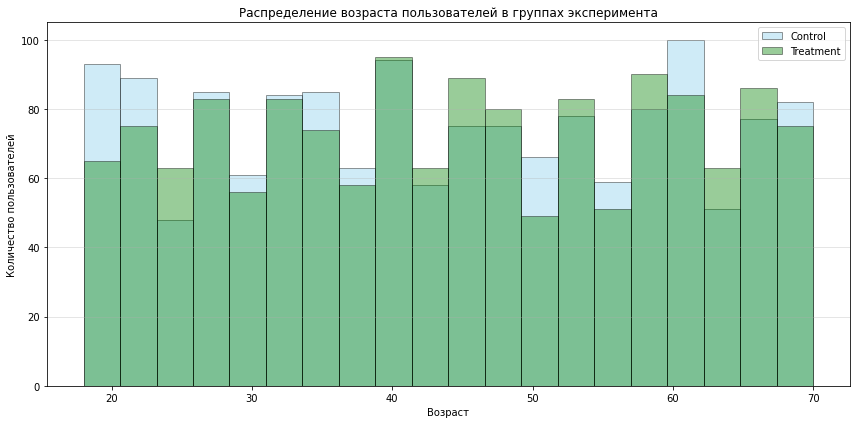

In [ ]:
# Разделяем данные по группам эксперимента
control_age = users_AB_filtered[users_AB_filtered['group'] == 'control']['age']
treatment_age = users_AB_filtered[users_AB_filtered['group'] == 'treatment']['age']

# Визуализируем распределение возраста
plt.figure(figsize=(12, 6))

# Строим гистограммы
plt.hist(control_age, bins=20, alpha=0.4, label='Control', color='skyblue', edgecolor='black')
plt.hist(treatment_age, bins=20, alpha=0.4, label='Treatment', color='green', edgecolor='black')

# Оформляем график
plt.title('Распределение возраста пользователей в группах эксперимента')
plt.xlabel('Возраст')
plt.ylabel('Количество пользователей')
plt.legend()
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()


В обеих группах представлены все возрастные категории от 18 до 70 лет. Распределение пользователей в двух группа по возрасту во многом совпадают.

In [ ]:

# Создаем сводную таблицу, чтобы сравнить количество пользователей в разных городах по группам
groups_region = users_AB_filtered.pivot_table(
    index='group',
    columns='region',
    values='user_id',
    aggfunc='nunique'
).reset_index()

# Выводим таблицу
groups_region.style.background_gradient(cmap='Blues', axis=0, low=0.3, high=0.7)

region,group,Другие регионы,Екатеринбург,Краснодар,Москва,Московская область,Нижний Новгород,Новосибирск,Ростов-на-Дону,Санкт-Петербург
0,control,487,68,63,371,115,65,65,39,230
1,treatment,494,72,46,359,120,59,50,45,220


В распределении пользователей по городам нет системных перековсов, есть только мелкие отклонения, которые взаимно компенсируют друг друга.

In [ ]:
# Создаем сводную таблицу c распределением по полу
groups_gender = users_AB_filtered.pivot_table(
    index='group',
    columns='gender',
    values='user_id',
    aggfunc='nunique'
).reset_index()

# Выводим таблицу
groups_gender.style.background_gradient(cmap='Blues', axis=0, low=0.3, high=0.8)

gender,group,F,M
0,control,745,758
1,treatment,766,699


Распределение по полу в группах выглядит достаточно близким, значимых смещений нет.

In [ ]:
# Создаем сводную таблицу c распределением по сегментам пользователей
groups_usersegm = users_AB_filtered.pivot_table(
    index='group',
    columns='buyer_segment',
    values='user_id',
    aggfunc='nunique'
).reset_index()

# Выводим таблицу
groups_usersegm.style.background_gradient(cmap='Blues', axis=0, low=0.3, high=0.8)

buyer_segment,group,medium,one_time,rare,regular
0,control,539,215,456,293
1,treatment,530,246,431,258


Распределение пользователей по покупательским сегментам достаточно близко. Однако сегментация сформирована на основе поведения пользователей в период эксперимента или позже,  поэтому данные различия скорее отражают реакцию аудитории на фичу.



Результаты проверки подтверждают корректность сплитования: распределение пользователей в группах по регионам, полу и возрасту сопоставимо. Выборки однородны, значимых перекосов не обнаружено, что позволяет приступать к анализу метрик эксперимента.

Теперь проведем **предобработку**.

Понизим разрядность полей с типом данных int64

In [ ]:
# Понизим разрядность полей с типом данных int64 и float64
downcast_numeric(users_AB_filtered)
downcast_numeric(events_AB_filtered)
downcast_numeric(orders_AB_filtered)



Расчитаем поле с выручкой в таблице с заказами.

In [ ]:
# Рассчитываем выручку как 5% комиссии от общей стоимости продажи
orders_AB_filtered['revenue'] = orders_AB_filtered['total_price'] * 0.05

**Промежуточный вывод** <br>
Данные проверены на корректность сплитования: распределение пользователей в группах по регионам, полу и возрасту сопоставимо. В контрольной группе оказалось 1503 пользователей, в тестовой - 1465. Выборки однородны, значимых перекосов не обнаружено, что позволяет приступать к анализу метрик.

Качество данных оценивается как высокое: типы данных приведены в соответствие (включая оптимизацию разрядности), а структура событий позволяет детально проследить путь пользователя. Временной период эксперимента с 1  по 26 января превышает отведенные 3 недели, но для анализа будем использовать все данные.


<p style="font-size:20px"><strong>Исследование результатов А/В эксперимента</strong></p>


Рассчитаем значение **ключевой, барьерной и вспомогательных метрик** по группам.

**Ключевая метрика**: Конверсия в первую покупку — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку <br>
*Цель*: увеличить конверсию с помощью бонуса <br>
*Критерий успеха*: статистически значимый рост конверсии в тестовой группе <br>

 **Вспомогательные метрики**:
- ARPU (средняя выручка на пользователя)
- ARPPU (средняя выручка на покупателя)
- AOV (средний чек)

**Барьерная метрика**:
- Общая выручка от пользователей




In [ ]:
# Считаем базовые показатели по группам для расчета метрик

# Группируем товарные позиции в уникальные заказы для расчета AOV
unique_orders = orders_AB_filtered.groupby(['group', 'user_id', 'order_date'])['revenue'].sum().reset_index()

# Количество уникальных пользователей, которые зарегистрировались за время эксперимента
users_stats = users_AB_filtered.groupby('group')['user_id'].nunique()

# Количество платящих пользователей
payers_stats = unique_orders.groupby('group')['user_id'].nunique()

# Общее количество заказов (считаем строки в сгруппированной таблице unique_orders)
orders_stats = unique_orders.groupby('group').size()

# Общая выручка по группам
revenue_stats = unique_orders.groupby('group')['revenue'].sum()

# Присваиваем значения переменным для контрольной и тестовой групп
c_users, t_users = users_stats['control'], users_stats['treatment']
c_payers, t_payers = payers_stats['control'], payers_stats['treatment']
c_orders, t_orders = orders_stats['control'], orders_stats['treatment']
c_rev, t_rev = revenue_stats['control'], revenue_stats['treatment']

# Формируем итоговую таблицу с
df_metrics = pd.DataFrame({
    'Метрика': [
        'Ключевая метрика: конверсия в покупку (%)',
        'Вспомогательная метрика 1: ARPU',
        'Вспомогательная метрика 2: ARPPU',
        'Вспомогательная метрика 3: AOV',
        'Барьерная метрика: общая выручка'
    ],
    'Control': [
        (c_payers / c_users) * 100,
        c_rev / c_users,
        c_rev / c_payers,
        c_rev / c_orders,
        c_rev
    ],
    'Test': [
        (t_payers / t_users) * 100,
        t_rev / t_users,
        t_rev / t_payers,
        t_rev / t_orders,
        t_rev
    ]
})

# Добавляем расчет абсолютной и относительной разницы
df_metrics['Absolute Lift'] = (df_metrics['Test'] - df_metrics['Control']).round(2)
df_metrics['Relative Lift (%)'] = ((df_metrics['Test'] / df_metrics['Control'] - 1) * 100).round(2)

# Выводим результат
df_metrics


,Метрика,Control,Test,Absolute Lift,Relative Lift (%)
0,Ключевая метрика: конверсия в покупку (%),1.064538,7.508532,6.44,605.33
1,Вспомогательная метрика 1: ARPU,12.587255,131.249051,118.66,942.71
2,Вспомогательная метрика 2: ARPPU,1182.415283,1747.998722,565.58,47.83
3,Вспомогательная метрика 3: AOV,1051.035807,1629.490334,578.45,55.04
4,Барьерная метрика: общая выручка,18918.644531,192279.859375,173361.21,916.35


Эксперимент показал значительный рост по всем метрикам.
Конверсия в первую покупку в тестовой группе составила 7.5% и это выше метрики в контроле - 1.06%, относительный лифт - 605.3%.
В тестовой группе ARPU составил 131.2 руб., в контрольной - 12.6 руб., абсолютный прирост составил 118.6 руб., а относительный - 942%. ARPPU в тестовой группе составил 1748 руб., в контроле 1182.4 руб., абсолютный лифт при этом 565.6 руб, относительный лифт - 47.8%. AOV (средний чек) в тесте составил 1629.4 руб., в контроле — 1051 руб., относительный рост метрики составил 55%. Барьерная метрика (общая выручка) в тестовой группе достигла 192279 руб., а в контрольно - 18918 руб., продемонстрировав рост на 916%.

Оценим, являются ли полученные различия статистически значимыми.<br>

Для ключевой метрики гипотезы сформулироуем так: <br>
**Нулевую гипотезу**: конверсия из регистрации в покупку в контрольной и тестовой группе не различаются.

**Альтернативная гипотеза**: конверсия из регистрации в покупку в тестовой группе выше, чем в контрольной.

Статистический тест: z-тест пропорций (поскольку мы сравниваем пропорции в двух выборках и это величина, которая считается на пользователя). Также проверяем условия применимости z-теста пропорции.

Поскольку мы проводим несколько тестов (4 теста -  для одной ключевой и трех вспомогательных метрик) на одних данных, будем применять поправку Бонферрони.

In [ ]:
# Проведем статистический тест
# Задаим уровень значимости (альфа) с поправкой Бонферрони
alpha = 0.05 / 4

# Проверяем условия применимости z-теста пропорции
n_a = orders_AB_filtered[orders_AB_filtered['group'] == 'control']['user_id'].nunique()
m_a = users_AB_filtered[users_AB_filtered['group'] == 'control']['user_id'].nunique()

n_b = orders_AB_filtered[orders_AB_filtered['group'] == 'treatment']['user_id'].nunique()
m_b = users_AB_filtered[users_AB_filtered['group'] == 'treatment']['user_id'].nunique()

# Расчитываем конверсии
p_a = n_a / m_a
p_b =  n_b / m_b

# Проверяем условия применимости z-теста пропорции
print('Проверяем условия применимости z-теста пропорции:')
if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    print('предпосылка о достаточном количестве данных выполняется\n')
else:
    print('предпосылка о достаточном количестве данных НЕ выполняется\n')

print(f'Конверсия в контрольной группе: {p_a:.2%}')
print(f'Конверсия в тестовой группе: {p_b:.2%}')
print(f'Absolute Lift: {(p_b - p_a):.2%}')
print(f'Relative Lift: {(p_b / p_a - 1):.2%}\n')

# Определяем уровень значимости
_, p_value_cr = proportions_ztest([n_b, n_a], [m_b, m_a], alternative='larger')


print(f'p-value = {p_value_cr:.4f}\n')
if p_value_cr > alpha:
    print('Нулевая гипотеза не отвергается: конверсия в тестовой группе не выше, чем в контрольной группе')

else:
    print('Нулевая гипотеза отвергается: конверсия в тестовой группе выше, чем в контрольной группе')






Проверяем условия применимости z-теста пропорции:
предпосылка о достаточном количестве данных НЕ выполняется

Конверсия в контрольной группе: 1.06%
Конверсия в тестовой группе: 7.51%
Absolute Lift: 6.44%
Relative Lift: 605.33%

p-value = 0.0000

Нулевая гипотеза отвергается: конверсия в тестовой группе выше, чем в контрольной группе


Статистический тест подтвердил, что введение бонуса на первую покупку для пользователей из канала TikTok привело к статистически значимому росту конверсии. Абсолютный прирост конверсии составил 6.4 процентных пункта, а относительный лифт 605%.


Далее проведем статистический тест Уэлча для оценки этой разницы в ARPU между группами. <br>
**Нулевую гипотезу**: ARPU в контрольной и тестовой группе не различаются.  <br>
**Альтернативная гипотеза**: ARPU в тестовой группе выше, чем в контрольной.

In [ ]:
# Проведем статистический тест для сравнения ARPU между группами
# Задаим уровень значимости (альфа) с поправкой Бонферрони
alpha = 0.05 / 4

# Считаем суммарную выручку на каждого пользователя из таблицы заказов
revenue_per_user = orders_AB_filtered.groupby('user_id')['revenue'].sum().reset_index()

# Формируем список всех уникальных пользователей, которые зарегистрировались за время эксперимента
all_users_group = users_AB_filtered[['user_id', 'group']]

# Объединяем данные, пропуски заменяем на 0
user_revenue = pd.merge(all_users_group, revenue_per_user, on='user_id', how='left').fillna(0)

# Создаем данные по группам
control_arpu = user_revenue[user_revenue['group'] == 'control']['revenue']
treatment_arpu = user_revenue[user_revenue['group'] == 'treatment']['revenue']

# Проводим статистический тест для сравнения ARPU (используем тест Уэлча, который не требуется равенства дисперсий)
_, p_value_arpu = ttest_ind(control_arpu, treatment_arpu, equal_var=False)

# Считаем метрику по группам и разницу между ними
print(f"ARPU Контрольной группы: {control_arpu.mean():.2f}")
print(f"ARPU Тестовой группы: {treatment_arpu.mean():.2f}")
print(f'Absolute Lift: {(treatment_arpu.mean() - control_arpu.mean()):.1f}')
print(f'Relative Lift: {(treatment_arpu.mean() / control_arpu.mean() - 1):.1%}\n')

# Выводим результат теста
print(f'p-value = {p_value_arpu:.4f}')
if p_value_arpu < alpha:
    print('Нулевая гипотеза отвергается: ARPU в тестовой группе выше, чем в контрольной.')
else:
    print('Нулевая гипотеза не отвергается: значимых различий по ARPU между группами не обнаружено.')



ARPU Контрольной группы: 12.59
ARPU Тестовой группы: 131.25
Absolute Lift: 118.7
Relative Lift: 942.7%

p-value = 0.0000
Нулевая гипотеза отвергается: ARPU в тестовой группе выше, чем в контрольной.


Введение бонуса на первую покупку для пользователей из TikTok привело к статистически значимому росту вспомогательной метрики ARPU. Абсолютный прирост ARPU составил 118.7 руб., а относительный лифт - 942.7%.

Далее расчитаем ARPPU (средняя выручка на покупателя) по группам.
Будем снова использовать тест Уэлча. <br>
**Нулевую гипотезу**: ARPPU в контрольной и тестовой группе не различаются.  <br>
**Альтернативная гипотеза**: ARPPU в тестовой группе выше, чем в контрольной.

In [ ]:
# Проведем статистический тест для сравнения ARPPU между группами
# Задаим уровень значимости (альфа) с поправкой Бонферрони
alpha = 0.05 / 4

# Считаем суммарную выручку на каждого пользователя из таблицы заказов (c учетом группы эксперимента)
revenue_users_with_group = orders_AB_filtered.groupby(['group', 'user_id'])['revenue'].sum().reset_index()

# Создаем данные по группам
control_arppu = revenue_users_with_group[revenue_users_with_group['group'] == 'control']['revenue']
treatment_arppu = revenue_users_with_group[revenue_users_with_group['group'] == 'treatment']['revenue']

# Проводим статистический тест для сравнения ARPPU (используем тест Уэлча, который не требуется равенства дисперсий)
_, p_value_arppu = ttest_ind(control_arppu, treatment_arppu, equal_var=False)

# Считаем метрику по группам и разницу между ними
print(f"ARPPU Контрольной группы: {control_arppu.mean():.2f}")
print(f"ARPPU Тестовой группы: {treatment_arppu.mean():.2f}")
print(f'Absolute Lift: {(treatment_arppu.mean() - control_arppu.mean()):.1f}')
print(f'Relative Lift: {(treatment_arppu.mean() / control_arppu.mean() - 1):.1%}\n')

# Выводим результат теста
print(f'p-value = {p_value_arppu:.4f}')
if p_value_arppu < alpha:
    print('Нулевая гипотеза отвергается: ARPPU в тестовой группе выше, чем в контрольной.')
else:
    print('Нулевая гипотеза не отвергается: значимых различий по ARPU между группами не обнаружено.')



ARPPU Контрольной группы: 1182.42
ARPPU Тестовой группы: 1748.00
Absolute Lift: 565.6
Relative Lift: 47.8%

p-value = 0.0493
Нулевая гипотеза не отвергается: значимых различий по ARPU между группами не обнаружено.


Несмотря на то, что ARPPU в тестовой группе выше, чем в контрольной, в результате теста мы не можем отклонить нулевую гипотезу.

Далее расчитаем AOV (средний чек) по группам.
Для оценки статистической значимости различий снова будем использовать тест Уэлча. <br>
**Нулевую гипотезу**: AOV в контрольной и тестовой группе не различаются.  <br>
**Альтернативная гипотеза**: AOV в тестовой группе выше, чем в контрольной.

In [ ]:
# Проведем статистический тест для сравнения AOV между группами
# Задаим уровень значимости (альфа) с поправкой Бонферрони
alpha = 0.05 / 4

# Группируем выручку до уровня уникальных заказов
unique_orders = orders_AB_filtered.groupby(['group', 'user_id', 'order_date'])['revenue'].sum().reset_index()

# Разделяем выручку по заказам на две группы
control_aov = unique_orders[unique_orders['group'] == 'control']['revenue']
treatment_aov = unique_orders[unique_orders['group'] == 'treatment']['revenue']


# Считаем метрику по группам и разницу между ними
print(f"Средний чек (AOV) Контрольной группы: {control_aov.mean():.2f}")
print(f"Средний чек (AOV) Тестовой группы: {treatment_aov.mean():.2f}")
print(f'Absolute Lift: {(treatment_aov.mean() - control_aov.mean()):.1f}')
print(f'Relative Lift: {(treatment_aov.mean() / control_aov.mean() - 1):.1%}\n')

# Проводим статистический тест для сравнения AOV (используем тест Уэлча, который не требуется равенства дисперсий)
_, p_value_aov = ttest_ind(control_aov, treatment_aov, equal_var=False)

# Выводим результат теста
print(f'p-value = {p_value_aov:.4f}')
if p_value_aov < alpha:
    print('Нулевая гипотеза отвергается: AOV в тестовой группе выше, чем в контрольной.')
else:
    print('Нулевая гипотеза не отвергается: значимых различий по AOV между группами не обнаружено.')


Средний чек (AOV) Контрольной группы: 1051.04
Средний чек (AOV) Тестовой группы: 1629.49
Absolute Lift: 578.5
Relative Lift: 55.0%

p-value = 0.0323
Нулевая гипотеза не отвергается: значимых различий по AOV между группами не обнаружено.


Снова несмотря на различия между группами теста показал, что значимых различий по среднему чеку между групами не обнаружено (p-value = 0.0323, что выше уровня значимости альфа с поправкой Бонферрони - 0.0125) и мы не можем отклонить нулевую гипотезу.

Барьерная метрика в данном эксперименте - это общая выручка от пользователя, для использвется для контроля "здоровья" экономики продукта. Метрика в экспериментальной группе не упала, а выросла на 916.3%: в тесте	192279 руб., в контроле	18918 руб. Данная динамика является закономерным следствием кратного увеличения конверсии: в тестовой группе количество пользователей, совершивших покупку, существенно выше, что обеспечило положительный баланс барьерной метрики.

Добавим результаты тестов (p-value) в таблицу с метриками.

In [ ]:
# Создаем список с рассчитанными p-value
p_values = [p_value_cr, p_value_arpu,  p_value_arppu,  p_value_aov, 'не проводился']

# Добавляем колонку в существующий датафрейм
df_metrics['p-value'] = p_values

# Добавляем колонку с информацией о том, статистически значимые различия между группами или нет
df_metrics['Статистический вывод'] = df_metrics['p-value'].apply(
    lambda x: 'статистически значимо' if isinstance(x, (int, float)) and x < alpha
    else ('не значимо' if isinstance(x, (int, float)) else '—')
)

# Выводим итоговую таблицу
display(df_metrics)

print(f'* уровень значимости определен с поправкой Бонферонни: {alpha}')

,Метрика,Control,Test,Absolute Lift,Relative Lift (%),p-value,Статистический вывод
0,Ключевая метрика: конверсия в покупку (%),1.064538,7.508532,6.44,605.33,0.0,статистически значимо
1,Вспомогательная метрика 1: ARPU,12.587255,131.249051,118.66,942.71,0.0,статистически значимо
2,Вспомогательная метрика 2: ARPPU,1182.415283,1747.998722,565.58,47.83,0.049277,не значимо
3,Вспомогательная метрика 3: AOV,1051.035807,1629.490334,578.45,55.04,0.032256,не значимо
4,Барьерная метрика: общая выручка,18918.644531,192279.859375,173361.21,916.35,не проводился,—


* уровень значимости определен с поправкой Бонферонни: 0.0125


Статистический тест подтвердил эффективность введения бонуса для пользователей из TikTok. Ключевая метрика - конверсия в покупку - показала рост с 1.06% до 7.5%. Эксперимент также положительно повлиял на монетизацию: ARPU увеличился на 942% (со 12.6 руб. до 131.2 руб.). Прирост среднего чека (AOV) и выручки на одного платящего пользователя (ARPPU) не оказался статистически значимым (p-value > 0.0125). Барьерная метрика продемонстрировала девятикратный рост общей выручки, что подтверждает финансовую целесообразность внедрения фичи.

## Выводы по этапу 5

В данной  части проекта мы исследовали влияние бонуса на первую покупку для пользователей, привлеченных через канал `TikTok` в маркетплейс. Предполагалось, что данная механика стимулирует новых пользователей быстрее проходить путь до покупки товаров и повысит общую выручку в этом сегменте.

Эксперимент показал статистически значимый рост активности аудитории: конверсия в покупку увеличилась на 605% (с 1.06% до 7.5%). При этом ARPU продемонстрировал рост более чем в 9 раз, увеличившись с 12.6 руб. до 131.2 руб. Барьерная метрика - общая выручка - показала девятикратный прирост, что подтверждает окупаемость предложенной фичи.

Несмотря на прирост среднего чека (AOV вырос на 55%) и выручки на платящего пользователя (ARPPU вырос на 48%), с учетом поправки Бонферрони эти изменения не являются статистически значимыми. Это указывает на то, что основной результат достигнут за счет резкого притока новых покупателей (роста конверсии), а не за счет того, что каждый отдельный клиент стал тратить больше (по крайней мере в рамках 3-недельного эксперимента мы этого не выявили). Бонус сработал как механизм преодоления порога первой покупки, при этом средние траты пользователей остались без изменений.

В целом критерий успеха эксперимента можно считать достигнутым: ключевая, вспомогательная (ARPU) и барьерная метрики показали кратный рост, что подтвержадет высокую эффективность бонусов для сегмента TikTok. Влияние праздничного периода начала января на поведение пользователей накладывает определенные ограничения на экстраполяцию выводов, однако общая динамика позволяет рекомендовать внедрение данной фичи.

# Итоговый вывод и рекомендации
Анализ маркетплейса выявил системные проблемы в привлечении, удержании и монетизации.

**Состояние продукта** <br>
Выручка к декабрю упала до уровня февраля при стабильном среднем чеке (1200-1270 руб.). Причина — не нехватка трафика, а нецелевая аудитория, которая не конвертируется и не окупается. Заказы сократились вдвое от пика в мае: ухудшилась воронка, снизился ретеншн старой аудитории, новые когорты с июля удерживаются хуже весенних.

CAC стабилен (около 400 руб.), но LTV упал с 452 до 150 руб. ROI первого месяца -55%, окупаемость выросла с 1 до 6–7 месяцев.

**Каналы** <br>
`Affiliate` и `SEO` — лидеры по качеству аудитории, окупаемость на 1-й месяц.
`Google Ads` — был ключевым источником выручки, отключение в ноябре ускорило спад.
`TikTok` — основной канал регистраций с июля, но Stickiness около 5%, CR 2-3%, ни одна когорта не окупилась.
`Direct` — бюджеты тратятся, но не атрибутируются по пользователям.
Воронка
Два критических узких места: активация (только 50% зарегистрированных переходят к просмотру) и оплата (44.5% оплачивают заказ — барьер на всех устройствах).

**Рекомендации** <br>
Каналы: сократить TikTok, масштабировать `Affiliate` и `SEO`, сохранить `Social Media`, разобраться с атрибуцией `Direct`.
Удержание: работать с первыми 30-60 днями — автоматизировать рассылки, стимулировать 2-й и 3-й заказы до того, как пользователь уйдёт.
Воронка: устранить барьеры на этапах активации (онбординг) и оплаты (показ способов оплаты и условий доставки до checkout).
Регионы: масштабировать опыт Краснодара (высокий чек, «Мебель») на другие города.
A/B-тест (бонус на первую покупку для TikTok): конверсия выросла на 605%, ARPU — в 9 раз, выручка — кратно. Рекомендовать к внедрению с оговоркой на влияние праздничного периода.

**Гипотезы для развития** <br>
Показ условий оплаты и доставки до checkout → конверсия в оплату с 44.5% до 55%.
Товарные рекомендации и «вместе дешевле» для сегментов one_time/rare/medium → рост среднего чека до уровня лояльных.
Перераспределение бюджета на «товары-магниты» в регионах → рост выручки на 15%.